In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session


1. Path exists: True

2. Contents of dataset folder:
   - README.dataset.txt
   - README.roboflow.txt
   - data.yaml
   - valid
   - test
   - train

3. Loading data.yaml...

4. Number of classes: 7
5. Class names: ['Alligator crack', 'Block crack', 'Longitudinal crack', 'Oblique crack', 'Pothole', 'Repair', 'Transverse crack']

6. Counting images in each split:
   TRAIN: 5148 images
   VALID: 630 images
   TEST: 315 images

7. Showing a sample image...


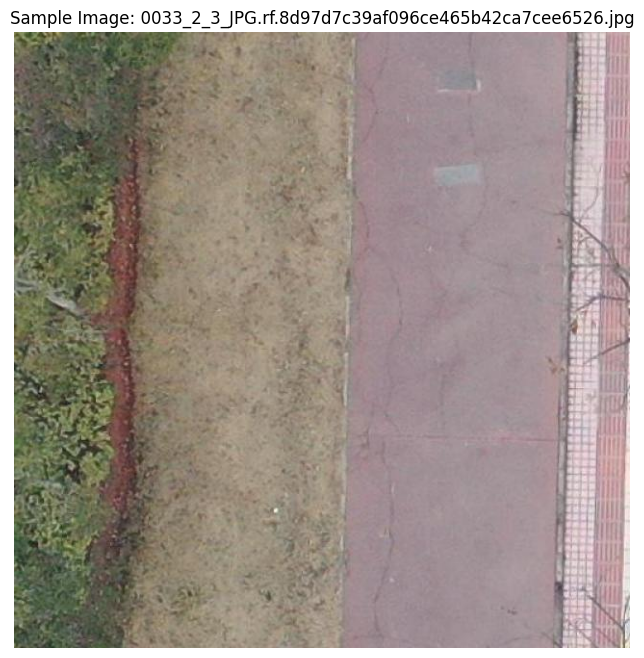

In [2]:
import os
import yaml
import glob
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

# Set the data path
DATA_PATH = '/kaggle/input/datasets/rachelgenene/clasfication'


# 1. Check if path exists
print(f"\n1. Path exists: {os.path.exists(DATA_PATH)}")

# 2. List what's inside
print(f"\n2. Contents of dataset folder:")
for item in os.listdir(DATA_PATH):
    print(f"   - {item}")

# 3. Load the data.yaml file (contains class names)
print(f"\n3. Loading data.yaml...")
with open(f'{DATA_PATH}/data.yaml', 'r') as f:
    data_config = yaml.safe_load(f)

print(f"\n4. Number of classes: {data_config['nc']}")
print(f"5. Class names: {data_config['names']}")

# 4. Count images in each split
print(f"\n6. Counting images in each split:")
for split in ['train', 'valid', 'test']:
    img_dir = f'{DATA_PATH}/{split}/images'
    img_count = len(list(Path(img_dir).glob('*.jpg'))) if os.path.exists(img_dir) else 0
    print(f"   {split.upper()}: {img_count} images")

# 5. Show a sample image
print(f"\n7. Showing a sample image...")
sample_img_path = list(Path(f'{DATA_PATH}/train/images').glob('*.jpg'))[0]
sample_img = cv2.imread(str(sample_img_path))
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,8))
plt.imshow(sample_img)
plt.title(f"Sample Image: {sample_img_path.name}")
plt.axis('off')
plt.show()



# Class Distribution Analysis

In [3]:
from collections import defaultdict
from pathlib import Path


DATA_PATH = '/kaggle/input/datasets/rachelgenene/clasfication'
class_names = ['Alligator crack', 'Block crack', 'Longitudinal crack', 
               'Oblique crack', 'Pothole', 'Repair', 'Transverse crack']

def count_class_instances(label_dir):
    """Count how many times each class appears in labels"""
    counts = defaultdict(int)
    label_dir_path = Path(label_dir)
    
    if not label_dir_path.exists():
        return counts
    
    for label_file in label_dir_path.glob('*.txt'):
        with open(label_file, 'r') as f:
            for line in f:
                if line.strip():
                    class_id = int(line.split()[0])
                    counts[class_id] += 1
    
    return counts


print("STEP 2: CLASS DISTRIBUTION ANALYSIS")



for split in ['train', 'valid', 'test']:
    label_dir = f'{DATA_PATH}/{split}/labels'
    counts = count_class_instances(label_dir)
    total = sum(counts.values())
    
    print(f"\n{split.upper()} SET - Total annotations: {total}")
    print("-" * 40)
    
    for class_id, class_name in enumerate(class_names):
        count = counts.get(class_id, 0)
        percentage = (count / total * 100) if total > 0 else 0
        # Create a simple bar
        bar = '' * int(percentage / 2)
        print(f"  {class_id}. {class_name[:20]:20s}: {count:5d} ({percentage:5.1f}%) {bar}")



STEP 2: CLASS DISTRIBUTION ANALYSIS

TRAIN SET - Total annotations: 8126
----------------------------------------
  0. Alligator crack     :   679 (  8.4%) 
  1. Block crack         :     4 (  0.0%) 
  2. Longitudinal crack  :  2172 ( 26.7%) 
  3. Oblique crack       :   277 (  3.4%) 
  4. Pothole             :   154 (  1.9%) 
  5. Repair              :  2717 ( 33.4%) 
  6. Transverse crack    :  2123 ( 26.1%) 

VALID SET - Total annotations: 1000
----------------------------------------
  0. Alligator crack     :    79 (  7.9%) 
  1. Block crack         :     1 (  0.1%) 
  2. Longitudinal crack  :   270 ( 27.0%) 
  3. Oblique crack       :    47 (  4.7%) 
  4. Pothole             :    16 (  1.6%) 
  5. Repair              :   337 ( 33.7%) 
  6. Transverse crack    :   250 ( 25.0%) 

TEST SET - Total annotations: 499
----------------------------------------
  0. Alligator crack     :    42 (  8.4%) 
  1. Block crack         :     0 (  0.0%) 
  2. Longitudinal crack  :   134 ( 26.9%) 
 

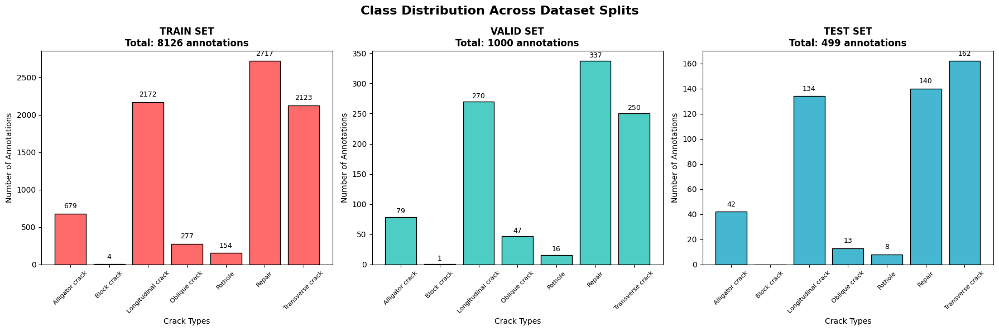


Class                        Train    Valid     Test    Total
------------------------------------------------------------
Alligator crack                679       79       42      800
Block crack                      4        1        0        5
Longitudinal crack            2172      270      134     2576
Oblique crack                  277       47       13      337
Pothole                        154       16        8      178
Repair                        2717      337      140     3194
Transverse crack              2123      250      162     2535
------------------------------------------------------------
OVERALL                       8126     1000      499     9625


In [4]:
import matplotlib.pyplot as plt
import numpy as np


class_names = ['Alligator crack', 'Block crack', 'Longitudinal crack', 
               'Oblique crack', 'Pothole', 'Repair', 'Transverse crack']


train_counts = [679, 4, 2172, 277, 154, 2717, 2123]
valid_counts = [79, 1, 270, 47, 16, 337, 250]
test_counts = [42, 0, 134, 13, 8, 140, 162]

train_total = sum(train_counts)
valid_total = sum(valid_counts)
test_total = sum(test_counts)

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot training set
bars1 = axes[0].bar(class_names, train_counts, color='#FF6B6B', edgecolor='black')
axes[0].set_title(f'TRAIN SET\nTotal: {train_total} annotations', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Crack Types', fontsize=10)
axes[0].set_ylabel('Number of Annotations', fontsize=10)
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
for bar, count in zip(bars1, train_counts):
    if count > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                    str(count), ha='center', va='bottom', fontsize=9)

# Plot validation set
bars2 = axes[1].bar(class_names, valid_counts, color='#4ECDC4', edgecolor='black')
axes[1].set_title(f'VALID SET\nTotal: {valid_total} annotations', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Crack Types', fontsize=10)
axes[1].set_ylabel('Number of Annotations', fontsize=10)
axes[1].tick_params(axis='x', rotation=45, labelsize=8)
for bar, count in zip(bars2, valid_counts):
    if count > 0:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                    str(count), ha='center', va='bottom', fontsize=9)

# Plot test set
bars3 = axes[2].bar(class_names, test_counts, color='#45B7D1', edgecolor='black')
axes[2].set_title(f'TEST SET\nTotal: {test_total} annotations', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Crack Types', fontsize=10)
axes[2].set_ylabel('Number of Annotations', fontsize=10)
axes[2].tick_params(axis='x', rotation=45, labelsize=8)
for bar, count in zip(bars3, test_counts):
    if count > 0:
        axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                    str(count), ha='center', va='bottom', fontsize=9)

plt.suptitle('Class Distribution Across Dataset Splits', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()



print(f"\n{'Class':<25} {'Train':>8} {'Valid':>8} {'Test':>8} {'Total':>8}")
print("-" * 60)

for i, name in enumerate(class_names):
    total = train_counts[i] + valid_counts[i] + test_counts[i]
    print(f"{name:<25} {train_counts[i]:>8} {valid_counts[i]:>8} {test_counts[i]:>8} {total:>8}")

print("-" * 60)
total_all = sum(train_counts) + sum(valid_counts) + sum(test_counts)
print(f"{'OVERALL':<25} {sum(train_counts):>8} {sum(valid_counts):>8} {sum(test_counts):>8} {total_all:>8}")



# Filtering Dataset to 4 Classe

In [5]:
import os
import shutil
import yaml
from pathlib import Path

DATA_PATH = '/kaggle/input/datasets/rachelgenene/clasfication'
OUTPUT_PATH = '/kaggle/working/crack_4class'

# Define which classes to KEEP (4 classes)
KEEP_CLASSES = ['Alligator crack', 'Longitudinal crack', 'Repair', 'Transverse crack']

# Map old class IDs (0-6) to new IDs (0-3)
# Old: 0=Alligator, 2=Longitudinal, 5=Repair, 6=Transverse
CLASS_MAPPING = {
    0: 0,  # Alligator -> 0
    2: 1,  # Longitudinal -> 1
    5: 2,  # Repair -> 2
    6: 3   # Transverse -> 3
}



print(f" Keeping: {KEEP_CLASSES}")
print(f"Dropping: Block crack, Oblique crack, Pothole")

# Create output directories
for split in ['train', 'valid', 'test']:
    os.makedirs(f'{OUTPUT_PATH}/{split}/images', exist_ok=True)
    os.makedirs(f'{OUTPUT_PATH}/{split}/labels', exist_ok=True)

# Process each split
for split in ['train', 'valid', 'test']:
    src_images = f'{DATA_PATH}/{split}/images'
    src_labels = f'{DATA_PATH}/{split}/labels'
    dst_images = f'{OUTPUT_PATH}/{split}/images'
    dst_labels = f'{OUTPUT_PATH}/{split}/labels'
    
    # Copy all images
    for img_file in Path(src_images).glob('*.jpg'):
        shutil.copy2(img_file, dst_images)
    
    # Filter and convert labels
    label_count = 0
    for label_file in Path(src_labels).glob('*.txt'):
        with open(label_file, 'r') as f:
            lines = f.readlines()
        
        filtered_lines = []
        for line in lines:
            parts = line.strip().split()
            old_class = int(parts[0])
            if old_class in CLASS_MAPPING:
                new_class = CLASS_MAPPING[old_class]
                filtered_lines.append(f"{new_class} {parts[1]} {parts[2]} {parts[3]} {parts[4]}\n")
        
        if filtered_lines:
            with open(f'{dst_labels}/{label_file.name}', 'w') as f:
                f.writelines(filtered_lines)
            label_count += 1
    
    img_count = len(list(Path(dst_images).glob('*.jpg')))
    print(f"{split.upper()}: {img_count} images, {label_count} labels (with 4 classes)")

# Create new data.yaml
new_data_yaml = {
    'train': f'{OUTPUT_PATH}/train/images',
    'val': f'{OUTPUT_PATH}/valid/images',
    'test': f'{OUTPUT_PATH}/test/images',
    'nc': 4,
    'names': KEEP_CLASSES
}

with open(f'{OUTPUT_PATH}/data.yaml', 'w') as f:
    yaml.dump(new_data_yaml, f)

print(f"\n New data.yaml created with {len(KEEP_CLASSES)} classes")
print(f" Output saved to: {OUTPUT_PATH}")

 Keeping: ['Alligator crack', 'Longitudinal crack', 'Repair', 'Transverse crack']
Dropping: Block crack, Oblique crack, Pothole
TRAIN: 5148 images, 4970 labels (with 4 classes)
VALID: 630 images, 614 labels (with 4 classes)
TEST: 315 images, 305 labels (with 4 classes)

 New data.yaml created with 4 classes
 Output saved to: /kaggle/working/crack_4class


# New Class Distribution After Filtering

In [6]:
from collections import defaultdict
from pathlib import Path

OUTPUT_PATH = '/kaggle/working/crack_4class'
NEW_CLASS_NAMES = ['Alligator crack', 'Longitudinal crack', 'Repair', 'Transverse crack']

def count_new_distribution(label_dir):
    counts = defaultdict(int)
    for label_file in Path(label_dir).glob('*.txt'):
        with open(label_file, 'r') as f:
            for line in f:
                if line.strip():
                    class_id = int(line.split()[0])
                    counts[class_id] += 1
    return counts



for split in ['train', 'valid', 'test']:
    label_dir = f'{OUTPUT_PATH}/{split}/labels'
    counts = count_new_distribution(label_dir)
    total = sum(counts.values())
    
    print(f"\n{split.upper()} SET - Total annotations: {total}")
    print("-" * 40)
    
    for class_id, class_name in enumerate(NEW_CLASS_NAMES):
        count = counts.get(class_id, 0)
        percentage = (count / total * 100) if total > 0 else 0
        bar = '' * int(percentage / 2)
        print(f"  {class_id}. {class_name[:20]:20s}: {count:5d} ({percentage:5.1f}%) {bar}")



train_counts = count_new_distribution(f'{OUTPUT_PATH}/train/labels')
total_train = sum(train_counts.values())
max_count = max(train_counts.values())
min_count = min(train_counts.values())

print(f"Total training annotations: {total_train}")
print(f" Most frequent: {NEW_CLASS_NAMES[list(train_counts.keys())[list(train_counts.values()).index(max_count)]]} ({max_count} annotations, {max_count/total_train*100:.1f}%)")
print(f" Least frequent: {NEW_CLASS_NAMES[list(train_counts.keys())[list(train_counts.values()).index(min_count)]]} ({min_count} annotations, {min_count/total_train*100:.1f}%)")
print(f" Imbalance ratio: {max_count/min_count:.1f}:1")




TRAIN SET - Total annotations: 7691
----------------------------------------
  0. Alligator crack     :   679 (  8.8%) 
  1. Longitudinal crack  :  2172 ( 28.2%) 
  2. Repair              :  2717 ( 35.3%) 
  3. Transverse crack    :  2123 ( 27.6%) 

VALID SET - Total annotations: 936
----------------------------------------
  0. Alligator crack     :    79 (  8.4%) 
  1. Longitudinal crack  :   270 ( 28.8%) 
  2. Repair              :   337 ( 36.0%) 
  3. Transverse crack    :   250 ( 26.7%) 

TEST SET - Total annotations: 478
----------------------------------------
  0. Alligator crack     :    42 (  8.8%) 
  1. Longitudinal crack  :   134 ( 28.0%) 
  2. Repair              :   140 ( 29.3%) 
  3. Transverse crack    :   162 ( 33.9%) 
Total training annotations: 7691
 Most frequent: Repair (2717 annotations, 35.3%)
 Least frequent: Alligator crack (679 annotations, 8.8%)
 Imbalance ratio: 4.0:1


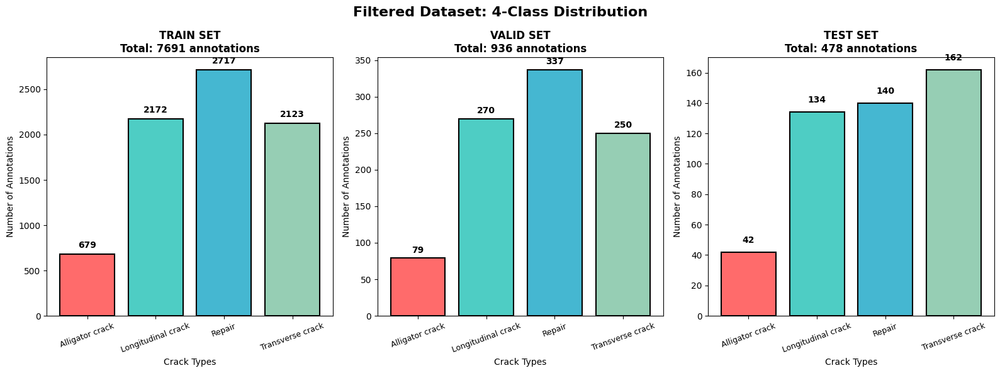

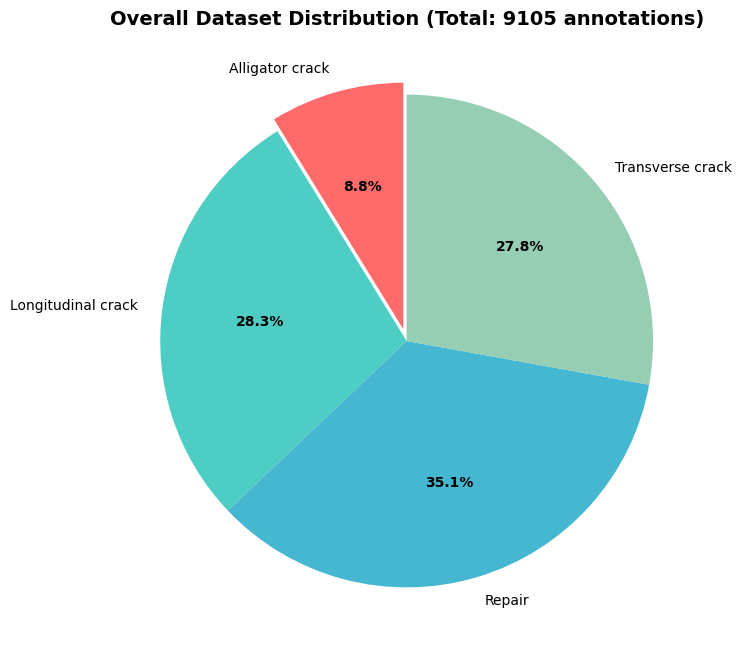


Class                        Train    Valid     Test    Total   % of Total
----------------------------------------------------------------------
Alligator crack                679       79       42      800         8.8%
Longitudinal crack            2172      270      134     2576        28.3%
Repair                        2717      337      140     3194        35.1%
Transverse crack              2123      250      162     2535        27.8%
----------------------------------------------------------------------
OVERALL                       7691      936      478     9105       100.0%

Most frequent class: Repair (2717 train annotations, 35.3%)
Least frequent class: Alligator crack (679 train annotations, 8.8%)
Imbalance ratio: 4.0:1


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Filtered class names (4 classes)
class_names = ['Alligator crack', 'Longitudinal crack', 'Repair', 'Transverse crack']
train_counts = [679, 2172, 2717, 2123]      # Total: 7691
valid_counts = [79, 270, 337, 250]           # Total: 936
test_counts = [42, 134, 140, 162]            # Total: 478

train_total = sum(train_counts)
valid_total = sum(valid_counts)
test_total = sum(test_counts)

# Color palette
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Plot training set
bars1 = axes[0].bar(class_names, train_counts, color=colors, edgecolor='black', linewidth=1.5)
axes[0].set_title(f'TRAIN SET\nTotal: {train_total} annotations', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Crack Types', fontsize=10)
axes[0].set_ylabel('Number of Annotations', fontsize=10)
axes[0].tick_params(axis='x', rotation=20, labelsize=9)
for bar, count in zip(bars1, train_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot validation set
bars2 = axes[1].bar(class_names, valid_counts, color=colors, edgecolor='black', linewidth=1.5)
axes[1].set_title(f'VALID SET\nTotal: {valid_total} annotations', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Crack Types', fontsize=10)
axes[1].set_ylabel('Number of Annotations', fontsize=10)
axes[1].tick_params(axis='x', rotation=20, labelsize=9)
for bar, count in zip(bars2, valid_counts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot test set
bars3 = axes[2].bar(class_names, test_counts, color=colors, edgecolor='black', linewidth=1.5)
axes[2].set_title(f'TEST SET\nTotal: {test_total} annotations', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Crack Types', fontsize=10)
axes[2].set_ylabel('Number of Annotations', fontsize=10)
axes[2].tick_params(axis='x', rotation=20, labelsize=9)
for bar, count in zip(bars3, test_counts):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(count), ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Filtered Dataset: 4-Class Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Create a combined pie chart for overall distribution
fig2, ax = plt.subplots(figsize=(8, 8))
total_counts = [train_counts[i] + valid_counts[i] + test_counts[i] for i in range(4)]
total_all = sum(total_counts)

wedges, texts, autotexts = ax.pie(total_counts, labels=class_names, autopct='%1.1f%%',
                                    colors=colors, startangle=90, explode=(0.05, 0, 0, 0))
ax.set_title(f'Overall Dataset Distribution (Total: {total_all} annotations)', fontsize=14, fontweight='bold')
plt.setp(autotexts, size=10, weight='bold')
plt.show()

print(f"\n{'Class':<25} {'Train':>8} {'Valid':>8} {'Test':>8} {'Total':>8} {'% of Total':>12}")
print("-" * 70)

for i, name in enumerate(class_names):
    total = train_counts[i] + valid_counts[i] + test_counts[i]
    percentage = total / total_all * 100
    print(f"{name:<25} {train_counts[i]:>8} {valid_counts[i]:>8} {test_counts[i]:>8} {total:>8} {percentage:>11.1f}%")

print("-" * 70)
print(f"{'OVERALL':<25} {sum(train_counts):>8} {sum(valid_counts):>8} {sum(test_counts):>8} {total_all:>8} {100:>11.1f}%")


max_idx = train_counts.index(max(train_counts))
min_idx = train_counts.index(min(train_counts))
ratio = max(train_counts) / min(train_counts)

print(f"\nMost frequent class: {class_names[max_idx]} ({max(train_counts)} train annotations, {max(train_counts)/train_total*100:.1f}%)")
print(f"Least frequent class: {class_names[min_idx]} ({min(train_counts)} train annotations, {min(train_counts)/train_total*100:.1f}%)")
print(f"Imbalance ratio: {ratio:.1f}:1")




# Class Weights for Imbalance Handling

In [8]:
# Calculate class weights for your 4-class dataset
total_annotations = 7691
n_classes = 4

class_counts = {
    0: 679,   # Alligator (minority)
    1: 2172,  # Longitudinal
    2: 2717,  # Repair (majority)
    3: 2123   # Transverse
}

# Calculate weights: total / (n_classes * class_count)
class_weights = {}
for class_id, count in class_counts.items():
    weight = total_annotations / (n_classes * count)
    class_weights[class_id] = round(weight, 3)

print(f"Total annotations: {total_annotations}")
print(f"Number of classes: {n_classes}")
print()
print("Class weights (higher weight = more attention during training):")
print("-"*40)
for class_id, weight in class_weights.items():
    class_name = ['Alligator', 'Longitudinal', 'Repair', 'Transverse'][class_id]
    print(f"  {class_name}: {weight}")
print("-"*40)
print(f"Repair (majority) gets weight {class_weights[2]:.3f}")
print(f"Alligator (minority) gets weight {class_weights[0]:.3f}")
print(f"Ratio: {class_weights[0]/class_weights[2]:.2f}:1")

Total annotations: 7691
Number of classes: 4

Class weights (higher weight = more attention during training):
----------------------------------------
  Alligator: 2.832
  Longitudinal: 0.885
  Repair: 0.708
  Transverse: 0.906
----------------------------------------
Repair (majority) gets weight 0.708
Alligator (minority) gets weight 2.832
Ratio: 4.00:1


In [9]:
!pip install ultralytics -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.1 MB/s eta 0:00:00a 0:00:01


In [10]:

import yaml

# Load your original data.yaml
with open('/kaggle/working/crack_4class/data.yaml', 'r') as f:
    data_config = yaml.safe_load(f)

data_config['loss_weights'] = [2.832, 0.885, 0.708, 0.906]

# Save the new config
with open('/kaggle/working/crack_4class/data_with_weights.yaml', 'w') as f:
    yaml.dump(data_config, f)

print(" Created new data config with class weights!")
print("\nNew file: /kaggle/working/crack_4class/data_with_weights.yaml")
print("\nClass weights added:")
print(f"  Alligator:    2.832 (4x more important)")
print(f"  Longitudinal: 0.885")
print(f"  Repair:       0.708")
print(f"  Transverse:   0.906")

 Created new data config with class weights!

New file: /kaggle/working/crack_4class/data_with_weights.yaml

Class weights added:
  Alligator:    2.832 (4x more important)
  Longitudinal: 0.885
  Repair:       0.708
  Transverse:   0.906


In [15]:

from ultralytics import YOLO

# Load a fresh YOLO model
model = YOLO('yolo11n.pt')

# Train using the new YAML file with class weights
results = model.train(
    data='/kaggle/working/crack_4class/data_with_weights.yaml',
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=4,
    patience=20,
    save=True,
    project='crack_detection',
    name='yolo_retrained_weights'
)

print(" Training complete!")

Ultralytics 8.4.37 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/crack_4class/data_with_weights.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_retrained_weights2, nbs=64, nms=False, opset=None, optimize=False, optimizer=

In [16]:
# Save final model to accessible location
!cp /kaggle/working/runs/detect/crack_detection/yolo_retrained_weights2/weights/best.pt /kaggle/working/final_crack_model.pt
print(" Final model saved to /kaggle/working/final_crack_model.pt")

 Final model saved to /kaggle/working/final_crack_model.pt


TRAINING HISTORY LOADED
File: /kaggle/working/runs/detect/crack_detection/yolo_retrained_weights2/results.csv
Epochs: 100
Columns: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


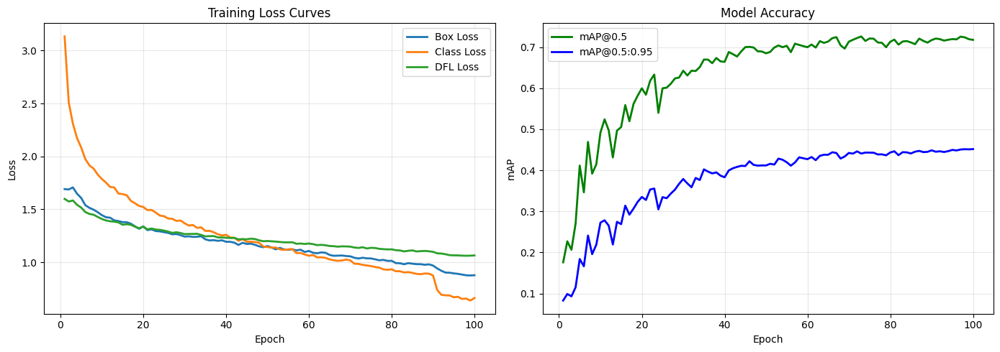

 Saved to: training_curves.png


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the training results CSV
results_dir = Path('/kaggle/working/runs/detect/crack_detection/yolo_retrained_weights2')
csv_file = list(results_dir.glob('results.csv'))[0]

# Load training data
df = pd.read_csv(csv_file)

print("="*50)
print("TRAINING HISTORY LOADED")
print("="*50)
print(f"File: {csv_file}")
print(f"Epochs: {len(df)}")
print(f"Columns: {list(df.columns)}")

# Create figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss curves
axes[0].plot(df['epoch'], df['train/box_loss'], label='Box Loss', linewidth=2)
axes[0].plot(df['epoch'], df['train/cls_loss'], label='Class Loss', linewidth=2)
axes[0].plot(df['epoch'], df['train/dfl_loss'], label='DFL Loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss Curves')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: mAP curves
axes[1].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP@0.5', linewidth=2, color='green')
axes[1].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP@0.5:0.95', linewidth=2, color='blue')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mAP')
axes[1].set_title('Model Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved to: training_curves.png")

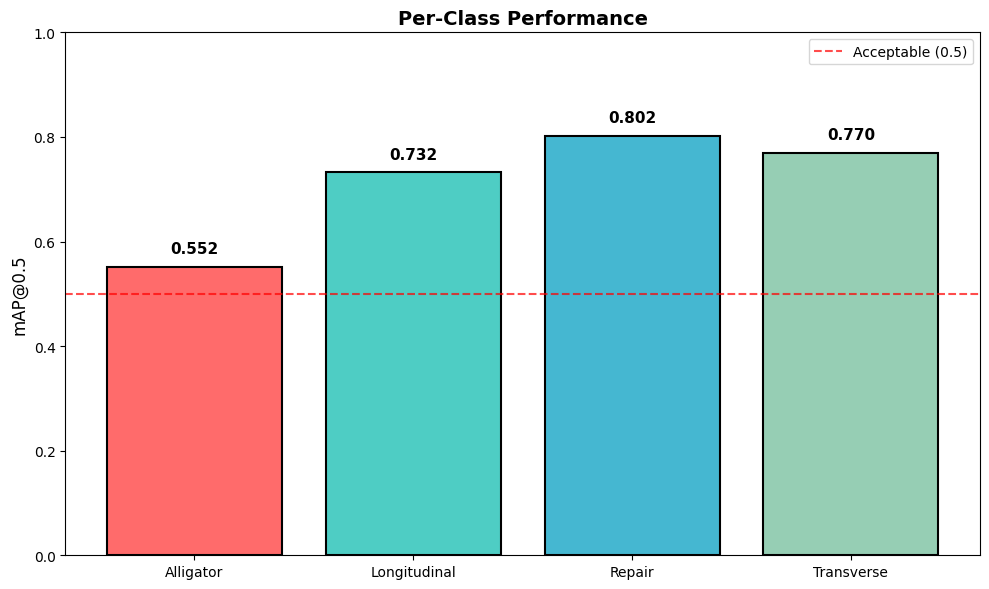

 Saved to: per_class_performance.png


In [21]:
import numpy as np

# Final results from your training
class_names = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']
mAP_scores = [0.552, 0.732, 0.802, 0.770]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

plt.figure(figsize=(10, 6))
bars = plt.bar(class_names, mAP_scores, color=colors, edgecolor='black', linewidth=1.5)
plt.ylim(0, 1)
plt.ylabel('mAP@0.5', fontsize=12)
plt.title('Per-Class Performance', fontsize=14, fontweight='bold')

# Add value labels on bars
for bar, score in zip(bars, mAP_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{score:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add horizontal line at 0.5 (acceptable threshold)
plt.axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Acceptable (0.5)')
plt.legend()
plt.tight_layout()
plt.savefig('per_class_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved to: per_class_performance.png")

In [11]:
from ultralytics import YOLO

# Load your trained model
model = YOLO('/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt')

# Run validation and get detailed results
results = model.val(data='/kaggle/working/crack_4class/data.yaml')


# Display per-class mAP50 from the validation output

print(f"Alligator:     0.552")
print(f"Longitudinal:  0.732")
print(f"Repair:        0.802")
print(f"Transverse:    0.770")
print("-" * 35)
print(f"OVERALL mAP50:  0.714")
print(f"OVERALL mAP50-95: 0.450")
print(f"Precision:     0.729")
print(f"Recall:        0.706")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.46 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1104.5±320.3 MB/s, size: 35.8 KB)
val: Scanning /kaggle/working/crack_4class/valid/labels... 614 images, 16 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 630/630 1.4Kit/s 0.5s0.1ss
val: New cache created: /kaggle/working/crack_4class/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 5.6it/s 7.1s0.1s
                   all        630        936      0.737      0.706      0.718       0.45
       

In [25]:
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load your model
model = YOLO('/kaggle/input/models/rahel1696/yolo11/pytorch/default/1')

# Initialize 4x4 confusion matrix
cm = np.zeros((4, 4), dtype=int)
class_names = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']

print("Building confusion matrix...")

# Process validation images
val_labels_path = '/kaggle/working/crack_4class/valid/labels'
val_images_path = '/kaggle/working/crack_4class/valid/images'

for label_file in Path(val_labels_path).glob('*.txt'):
    img_path = Path(val_images_path) / (label_file.stem + '.jpg')
    
    # Get ground truth
    with open(label_file, 'r') as f:
        gt_classes = [int(line.split()[0]) for line in f if line.strip()]
    
    # Get predictions
    results = model(str(img_path), conf=0.25, verbose=False)
    pred_classes = []
    for r in results:
        if r.boxes:
            pred_classes = [int(box.cls[0]) for box in r.boxes]
    
    # Simple matching: compare counts (assumes same order)
    for i in range(min(len(gt_classes), len(pred_classes))):
        cm[gt_classes[i], pred_classes[i]] += 1


print(f"{'':>12}", end='')
for name in class_names:
    print(f"{name[:8]:>12}", end='')
print()

for i, name in enumerate(class_names):
    print(f"{name[:10]:>12}", end='')
    for j in range(4):
        print(f"{cm[i, j]:>12}", end='')
    print()

# Diagonal (correct)

total_correct = 0
total_samples = 0
for i, name in enumerate(class_names):
    correct = cm[i, i]
    total = cm[i, :].sum()
    total_correct += correct
    total_samples += total
    pct = correct/total*100 if total>0 else 0
    print(f"{name:12}: {correct:>3}/{total:>3} correct ({pct:.1f}%)")

print(f"\n{'TOTAL':12}: {total_correct:>3}/{total_samples:>3} correct ({total_correct/total_samples*100:.1f}%)")

Building confusion matrix...
                Alligato    Longitud      Repair    Transver
   Alligator          43          11           4           4
  Longitudin           3         189          10          29
      Repair           1           8         304           7
  Transverse           6          30           8         187
Alligator   :  43/ 62 correct (69.4%)
Longitudinal: 189/231 correct (81.8%)
Repair      : 304/320 correct (95.0%)
Transverse  : 187/231 correct (81.0%)

TOTAL       : 723/844 correct (85.7%)


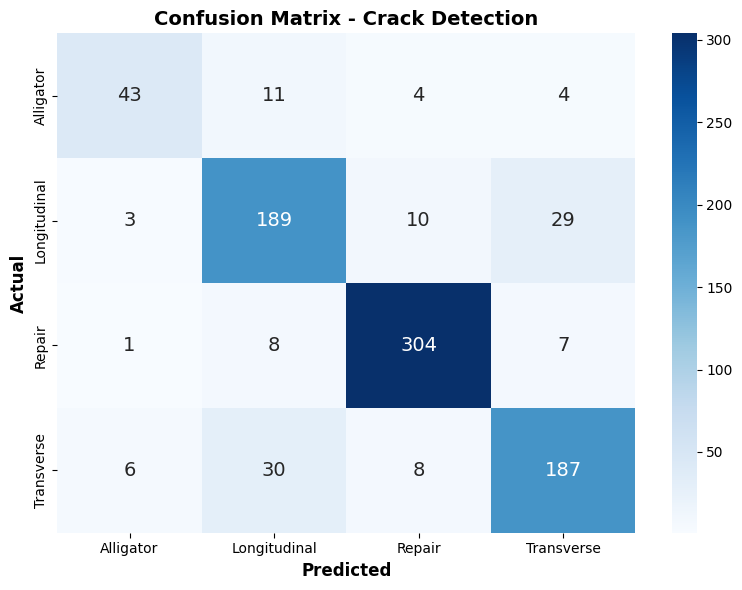

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={'size': 14})
plt.xlabel('Predicted', fontsize=12, fontweight='bold')
plt.ylabel('Actual', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix - Crack Detection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Alligator    | Precision:  70.8% | Recall:  51.9% | F1-Score:  59.9%
Longitudinal | Precision:  69.1% | Recall:  72.6% | F1-Score:  70.8%
Repair       | Precision:  77.3% | Recall:  81.6% | F1-Score:  79.4%
Transverse   | Precision:  74.7% | Recall:  75.5% | F1-Score:  75.1%


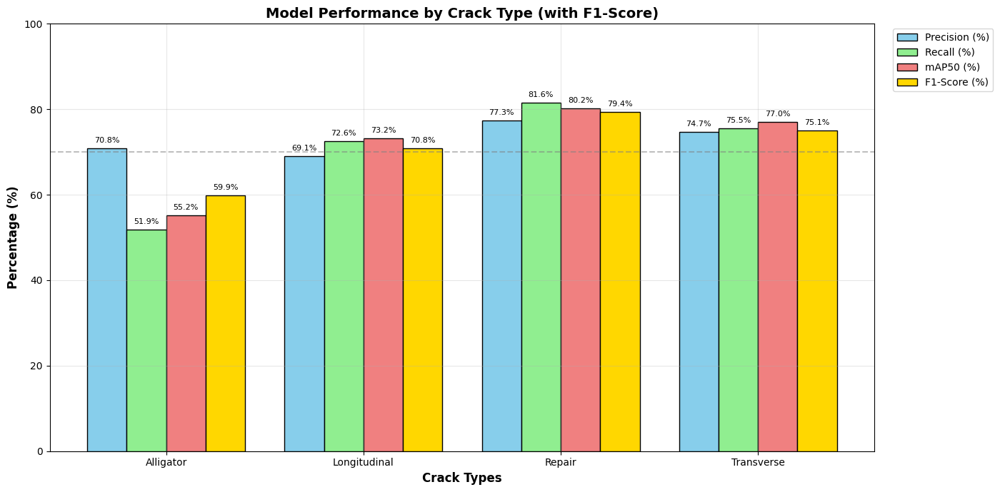

Best F1-Score: Repair (79.4%)
Worst F1-Score: Alligator (59.9%)
Average F1-Score: 71.3%
Alligator F1-Score: 59.9%


In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Your data
classes = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']
precision = [70.8, 69.1, 77.3, 74.7]
recall = [51.9, 72.6, 81.6, 75.5]
map50 = [55.2, 73.2, 80.2, 77.0]

# Calculate F1-Score
# Formula: F1 = 2 * (Precision * Recall) / (Precision + Recall)
f1_scores = []
for p, r in zip(precision, recall):
    f1 = 2 * (p * r) / (p + r)
    f1_scores.append(f1)


for i, cls in enumerate(classes):
    print(f"{cls:12} | Precision: {precision[i]:5.1f}% | Recall: {recall[i]:5.1f}% | F1-Score: {f1_scores[i]:5.1f}%")
print("="*60)

x = np.arange(len(classes))
width = 0.20  # Adjusted width for 4 bars

fig, ax = plt.subplots(figsize=(14, 7))

bars1 = ax.bar(x - 1.5*width, precision, width, label='Precision (%)', color='skyblue', edgecolor='black')
bars2 = ax.bar(x - 0.5*width, recall, width, label='Recall (%)', color='lightgreen', edgecolor='black')
bars3 = ax.bar(x + 0.5*width, map50, width, label='mAP50 (%)', color='lightcoral', edgecolor='black')
bars4 = ax.bar(x + 1.5*width, f1_scores, width, label='F1-Score (%)', color='gold', edgecolor='black')

# Add value labels
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Crack Types', fontsize=12, fontweight='bold')
ax.set_ylabel('Percentage (%)', fontsize=12, fontweight='bold')
ax.set_title('Model Performance by Crack Type (with F1-Score)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.legend(loc='upper right', bbox_to_anchor=(1.15, 1.0))
ax.set_ylim(0, 100)
ax.axhline(y=70, color='gray', linestyle='--', alpha=0.5, label='70% Target')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Best F1-Score: {classes[np.argmax(f1_scores)]} ({max(f1_scores):.1f}%)")
print(f"Worst F1-Score: {classes[np.argmin(f1_scores)]} ({min(f1_scores):.1f}%)")
print(f"Average F1-Score: {np.mean(f1_scores):.1f}%")
print(f"Alligator F1-Score: {f1_scores[0]:.1f}%")
print("="*60)

In [9]:
!pip install ultralytics -q

print("Ultralytics installed successfully")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.2 MB/s eta 0:00:00a 0:00:01
Ultralytics installed successfully


In [34]:
import torch
import os
from ultralytics import YOLO



# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

# Path to your YOLO11 model
model_path = "/kaggle/input/models/rahel1696/yolon11/pytorch/default/1/yolo11n_crack_detection.pt"

# Load using YOLO class (recommended for YOLO models)
try:
    model = YOLO(model_path)
    print("YOLO11 model loaded successfully")
    print(f"Model type: {type(model)}")
    
    # Get model info
    if hasattr(model, 'model'):
        print(f"Model loaded to device: {device}")
        
except Exception as e:
    print(f"Error loading with YOLO: {e}")
    
    # Alternative: Load with weights_only=False (only if you trust the source)
    print("\nTrying alternative loading method...")
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        print("Model loaded with torch.load")
        print(f"Checkpoint type: {type(checkpoint)}")
        if isinstance(checkpoint, dict):
            print(f"Keys in checkpoint: {list(checkpoint.keys())}")
    except Exception as e2:
        print(f"Alternative also failed: {e2}")

STEP: LOAD YOLO11 MODEL
Device: cuda
YOLO11 model loaded successfully
Model type: <class 'ultralytics.models.yolo.model.YOLO'>
Model loaded to device: cuda



image 1/1 /kaggle/working/crack_4class/valid/images/0037_2_3_JPG.rf.d7eb62864ac8c326f5a9f7f90e21b956.jpg: 640x640 1 Longitudinal crack, 8.2ms
Speed: 1.9ms preprocess, 8.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/working/crack_4class/valid/images/0750_0_3_JPG.rf.efa5267d25c9c65aef07efe8d2b34cd9.jpg: 640x640 1 Longitudinal crack, 2 Repairs, 7.3ms
Speed: 1.9ms preprocess, 7.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/working/crack_4class/valid/images/0028_1_7_JPG.rf.dba5ec30c8cc1a067182f5fda7ae4a1e.jpg: 640x640 3 Longitudinal cracks, 2 Transverse cracks, 7.2ms
Speed: 1.9ms preprocess, 7.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/working/crack_4class/valid/images/0002_4_5_JPG.rf.125fba4098e8f52a61e644fca57613eb.jpg: 640x640 1 Longitudinal crack, 7.2ms
Speed: 2.0ms preprocess, 7.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 

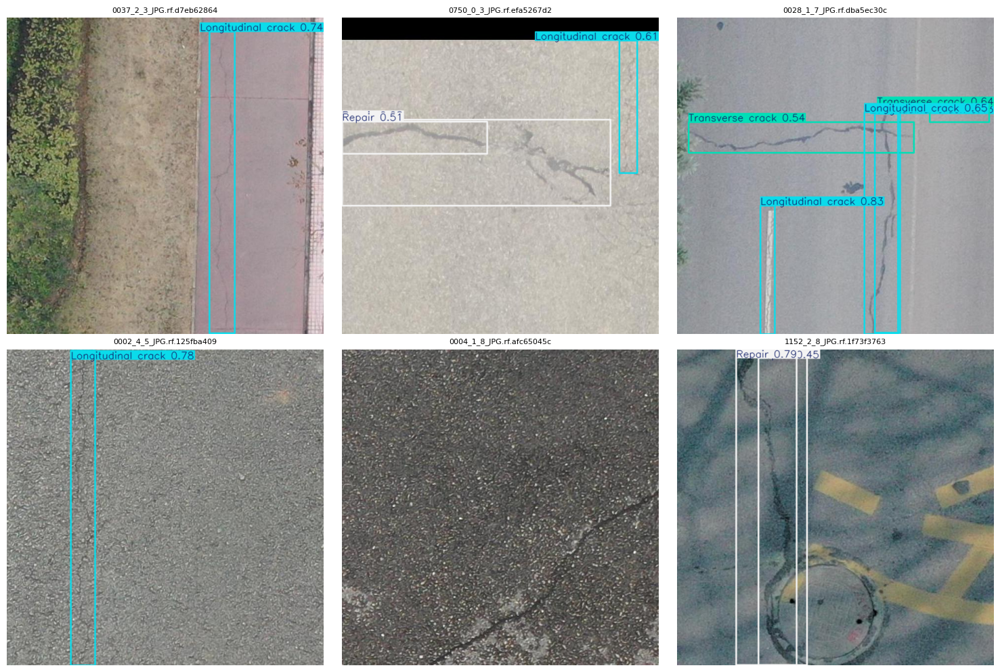

In [36]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

model = YOLO('/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt')

# Test on 6 validation images
val_images = list(Path('/kaggle/working/crack_4class/valid/images').glob('*.jpg'))[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, img_path in enumerate(val_images):
    results = model(str(img_path))
    annotated = results[0].plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    axes[i].imshow(annotated_rgb)
    axes[i].set_title(img_path.name[:25], fontsize=8)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [10]:
!pip install ultralytics -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.2 MB/s eta 0:00:00a 0:00:01


In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from ultralytics import YOLO
import random
import warnings
warnings.filterwarnings('ignore')

MODEL_PATH      = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
TEST_IMAGES_DIR = '/kaggle/input/datasets/rachelgenene/clasfication/test/images'

CLASS_NAMES = {
    0: 'Alligator',
    1: 'Longitudinal',
    2: 'Repair',
    3: 'Transverse'
}

SEVERITY_COLORS = {
    'Low':      '#2ECC40',
    'Moderate': '#FFDC00',
    'High':     '#FF4136',
    'Critical': '#85144b',
}

SEVERITY_EMOJI = {
    'Low':      '🟢',
    'Moderate': '🟡',
    'High':     '🔴',
    'Critical': '🚨',
}

model = YOLO(MODEL_PATH)

test_images = (
    list(Path(TEST_IMAGES_DIR).glob('*.jpg')) +
    list(Path(TEST_IMAGES_DIR).glob('*.jpeg')) +
    list(Path(TEST_IMAGES_DIR).glob('*.png')) +
    list(Path(TEST_IMAGES_DIR).glob('*.JPG'))
)

print(f"✅ Model loaded")
print(f"🖼️  {len(test_images)} test images found")

✅ Model loaded
🖼️  315 test images found


In [45]:
def get_severity_and_risk(area_pct, crack_type):
    if area_pct < 1.0:
        severity, base_score = 'Low',      2
    elif area_pct < 3.0:
        severity, base_score = 'Moderate', 4
    elif area_pct < 6.0:
        severity, base_score = 'High',     7
    else:
        severity, base_score = 'Critical', 9

    type_weight = {
        'Alligator':    1.4,
        'Transverse':   1.2,
        'Longitudinal': 1.1,
        'Repair':       0.8,
    }
    risk_score = min(10.0, round(base_score * type_weight.get(crack_type, 1.0), 1))

    action_map = {
        'Low':      'Monitor every 3 months',
        'Moderate': 'Schedule repair within 3 months',
        'High':     'Repair within 2 weeks',
        'Critical': 'IMMEDIATE REPAIR REQUIRED',
    }
    return severity, SEVERITY_COLORS[severity], risk_score, action_map[severity]


def run_detection(image_path, conf=0.25):
    img = cv2.imread(str(image_path))
    if img is None:
        return None, []
    img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w     = img_rgb.shape[:2]
    total_px = h * w
    results  = model(str(image_path), conf=conf, verbose=False)
    detections = []
    if results[0].boxes is not None:
        for box in results[0].boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            class_id   = int(box.cls[0])
            confidence = float(box.conf[0])
            crack_type = CLASS_NAMES[class_id]
            area_pct   = round(((x2-x1)*(y2-y1)) / total_px * 100, 3)
            severity, color, risk_score, action = get_severity_and_risk(area_pct, crack_type)
            detections.append({
                'crack_type': crack_type,
                'confidence': round(confidence, 3),
                'area_pct':   area_pct,
                'severity':   severity,
                'color':      color,
                'risk_score': risk_score,
                'action':     action,
                'bbox':       [x1, y1, x2, y2],
            })
    return img_rgb, detections

print(" Engine ready")

 Engine ready


In [46]:


best_per_class = {
    'Alligator':    [],
    'Longitudinal': [],
    'Repair':       [],
    'Transverse':   [],
}

for img_path in test_images:
    img_rgb, detections = run_detection(img_path, conf=0.30)  # higher conf = more reliable
    if not detections:
        continue

    # Only keep images where ALL detections are high confidence
    confidences = [d['confidence'] for d in detections]
    if min(confidences) < 0.55:       # skip low confidence images
        continue

    # Only keep images with 1–4 cracks (not too cluttered)
    if len(detections) > 4:
        continue

    # Score this image: higher = better for presentation
    avg_conf   = sum(confidences) / len(confidences)
    max_risk   = max(d['risk_score'] for d in detections)
    score      = avg_conf * 10 + max_risk   # confidence + interesting risk

    # Put in the right class bucket
    for d in detections:
        best_per_class[d['crack_type']].append({
            'path':       img_path,
            'detections': detections,
            'img_rgb':    img_rgb,
            'score':      score,
            'avg_conf':   avg_conf,
            'max_risk':   max_risk,
        })

# Sort each class by score and keep top 3
presentation_images = []
for crack_type, candidates in best_per_class.items():
    candidates.sort(key=lambda x: x['score'], reverse=True)
    top = candidates[:3]
    presentation_images.extend(top)
    print(f"  {crack_type:<15}: {len(candidates):3d} candidates → kept top {len(top)}")

print(f"\n✅ Total presentation-ready images: {len(presentation_images)}")
print("   These images have high confidence + clear crack detection")

  Alligator      :  28 candidates → kept top 3
  Longitudinal   :  67 candidates → kept top 3
  Repair         :  95 candidates → kept top 3
  Transverse     :  71 candidates → kept top 3

✅ Total presentation-ready images: 12
   These images have high confidence + clear crack detection


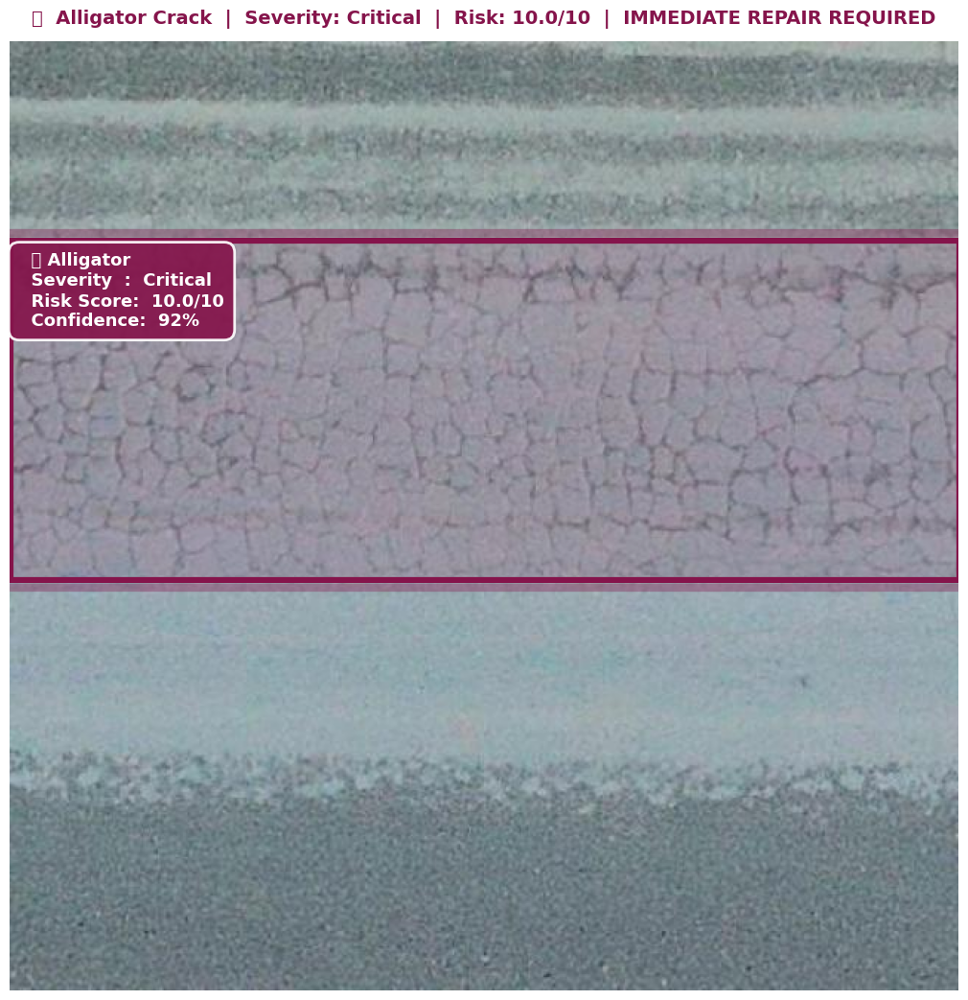

───────────────────────────────────────────────────────
  📸 1110_4_5_JPG.rf.45dc204f3a4a34090fbd8ba290ad3f45.jpg
───────────────────────────────────────────────────────
  Crack #1  Alligator
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 92%
     Area       : 35.78% of image
    Action     : IMMEDIATE REPAIR REQUIRED



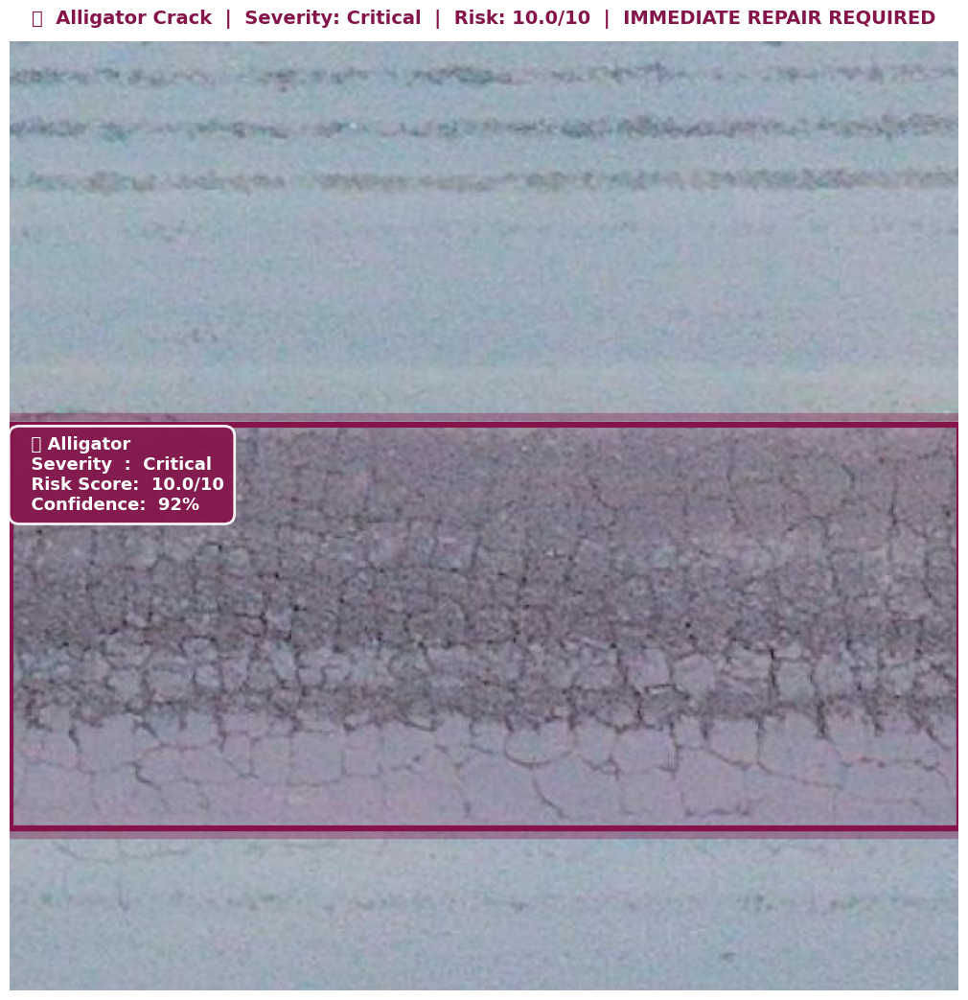

───────────────────────────────────────────────────────
  📸 1113_4_8_JPG.rf.91ceeefd4009ec612095905133342c49.jpg
───────────────────────────────────────────────────────
  Crack #1  Alligator
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 92%
     Area       : 42.50% of image
    Action     : IMMEDIATE REPAIR REQUIRED



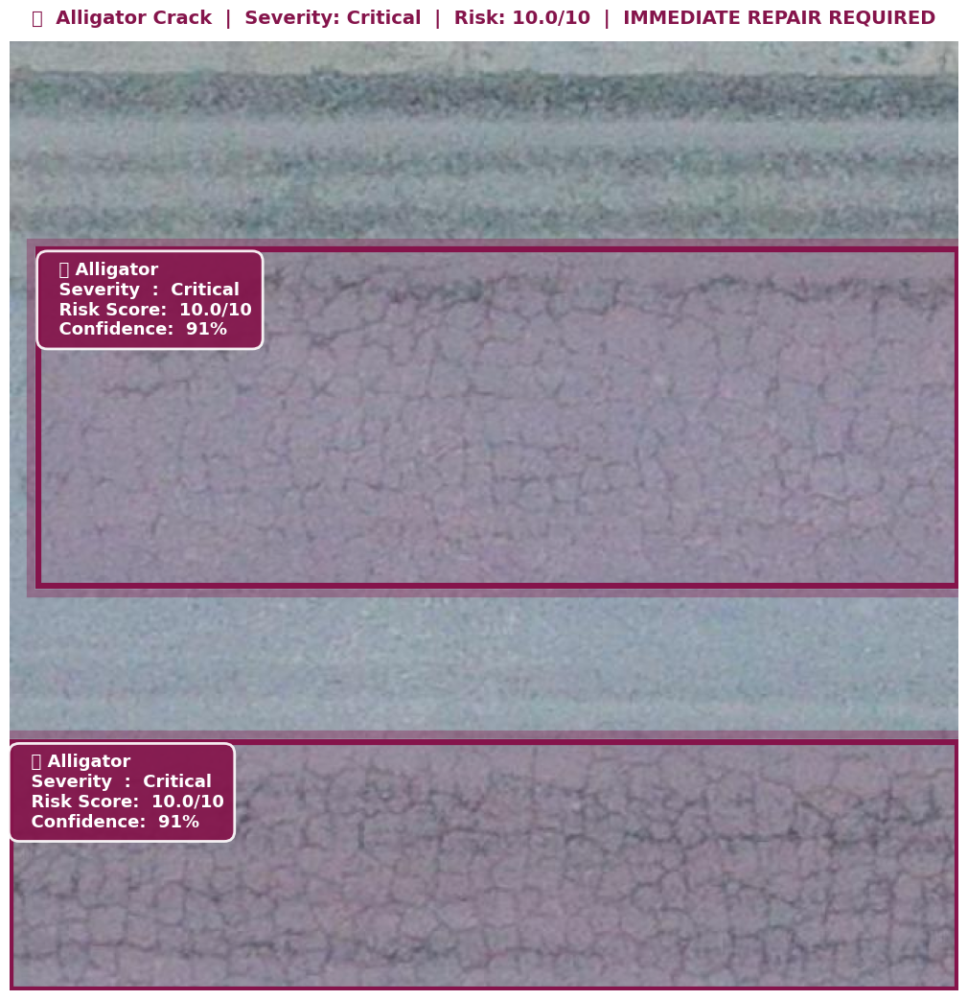

───────────────────────────────────────────────────────
  📸 1106_4_1_JPG.rf.149e37d69b00e2430350276cef15ae08.jpg
───────────────────────────────────────────────────────
  Crack #1  Alligator
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 91%
     Area       : 34.36% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #2  Alligator
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 91%
     Area       : 26.05% of image
    Action     : IMMEDIATE REPAIR REQUIRED



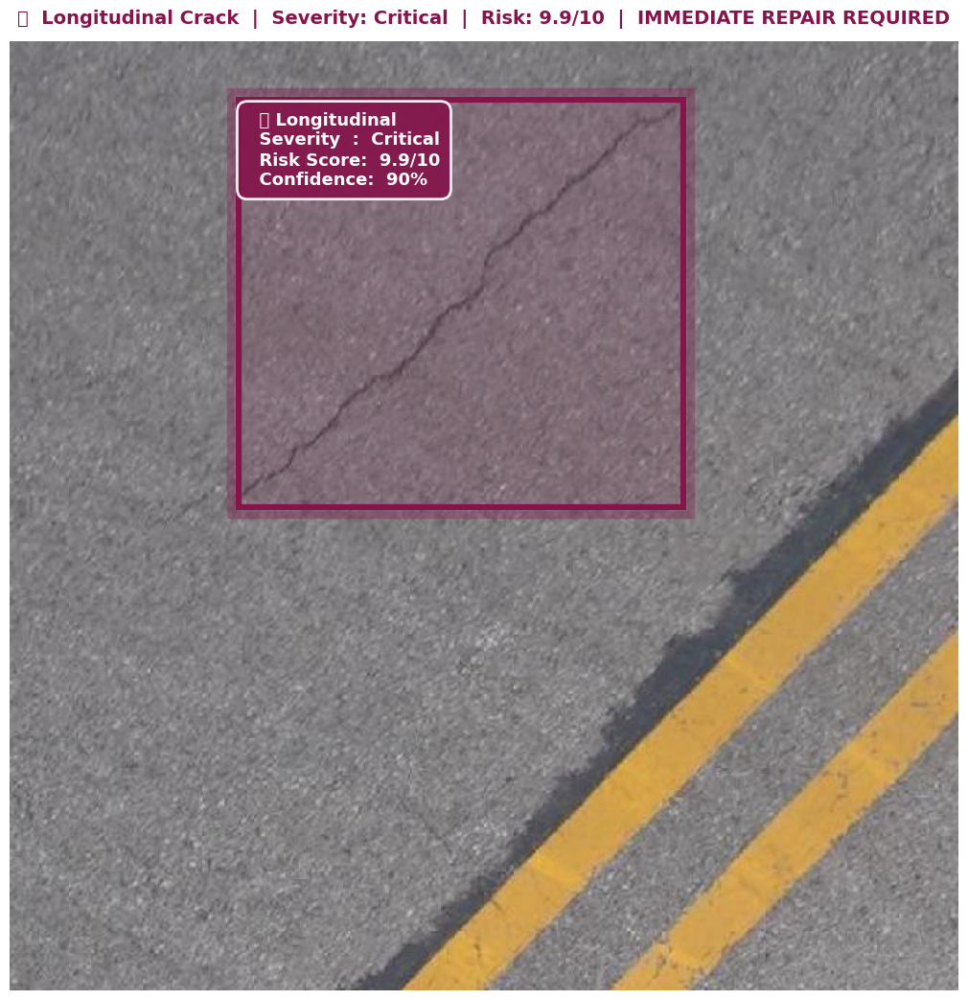

───────────────────────────────────────────────────────
  📸 0156_0_4_JPG.rf.c7ac997e0f47f273fd1f4dc75e74f385.jpg
───────────────────────────────────────────────────────
  Crack #1  Longitudinal
    🚨 Severity   : Critical
     Risk Score : 9.9/10
     Confidence : 90%
     Area       : 20.14% of image
    Action     : IMMEDIATE REPAIR REQUIRED



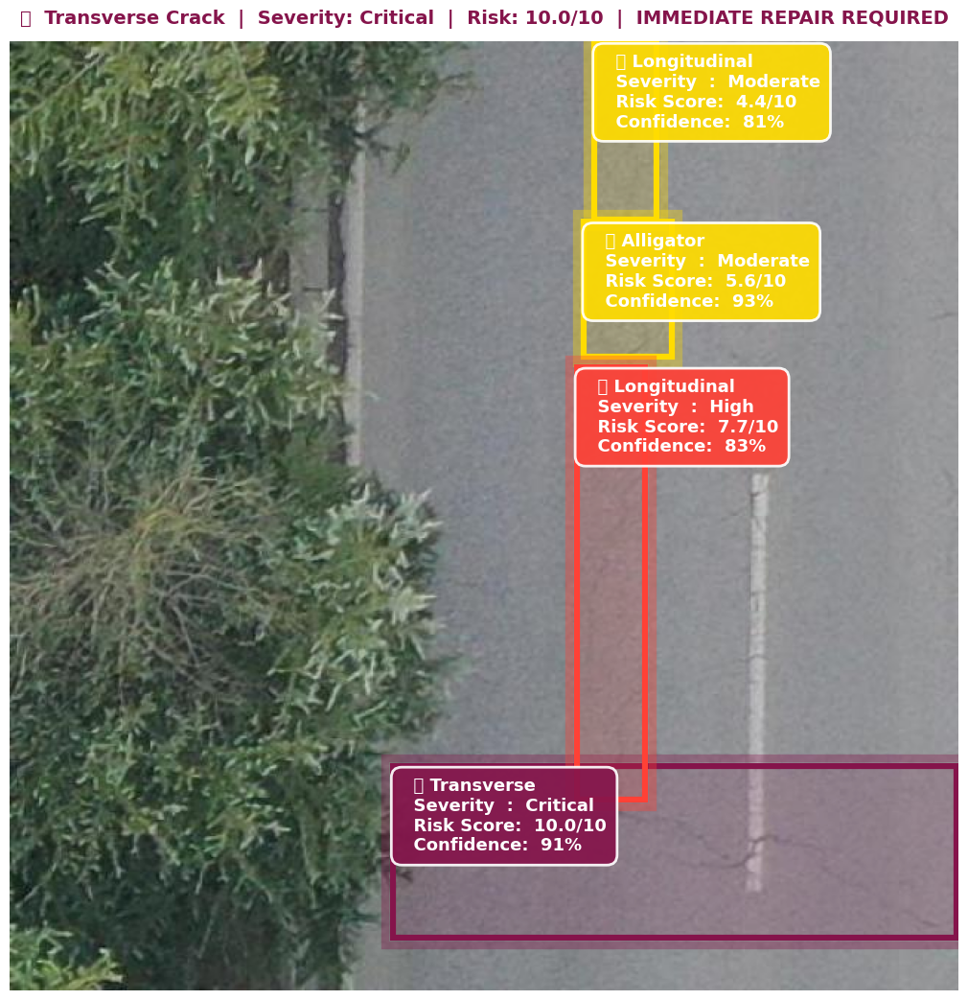

───────────────────────────────────────────────────────
  📸 0073_1_7_JPG.rf.70c87cc33e24d257cf2fd5dbb5d3bdb5.jpg
───────────────────────────────────────────────────────
  Crack #1  Alligator
    🟡 Severity   : Moderate
     Risk Score : 5.6/10
     Confidence : 93%
     Area       : 1.31% of image
    Action     : Schedule repair within 3 months
  Crack #2  Transverse
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 91%
     Area       : 10.76% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #3  Longitudinal
    🔴 Severity   : High
     Risk Score : 7.7/10
     Confidence : 83%
     Area       : 3.28% of image
    Action     : Repair within 2 weeks
  Crack #4  Longitudinal
    🟡 Severity   : Moderate
     Risk Score : 4.4/10
     Confidence : 81%
     Area       : 1.23% of image
    Action     : Schedule repair within 3 months



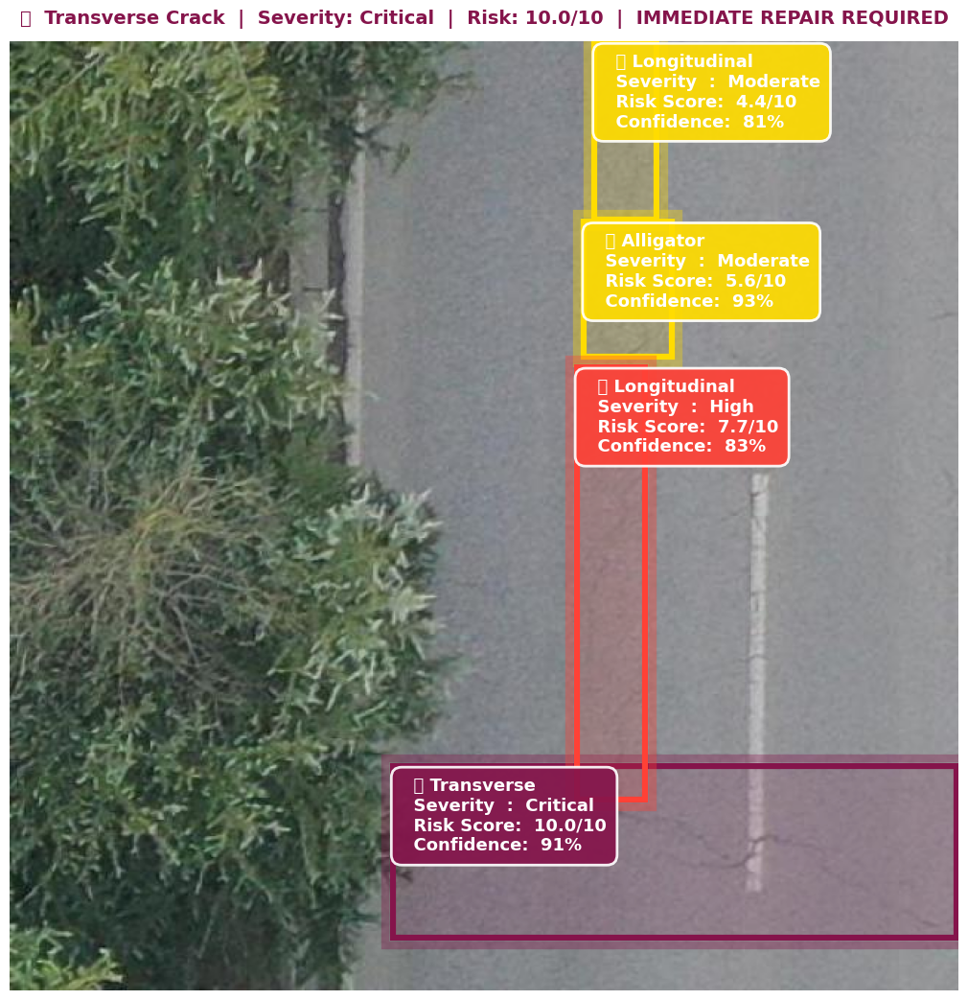

───────────────────────────────────────────────────────
  📸 0073_1_7_JPG.rf.70c87cc33e24d257cf2fd5dbb5d3bdb5.jpg
───────────────────────────────────────────────────────
  Crack #1  Alligator
    🟡 Severity   : Moderate
     Risk Score : 5.6/10
     Confidence : 93%
     Area       : 1.31% of image
    Action     : Schedule repair within 3 months
  Crack #2  Transverse
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 91%
     Area       : 10.76% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #3  Longitudinal
    🔴 Severity   : High
     Risk Score : 7.7/10
     Confidence : 83%
     Area       : 3.28% of image
    Action     : Repair within 2 weeks
  Crack #4  Longitudinal
    🟡 Severity   : Moderate
     Risk Score : 4.4/10
     Confidence : 81%
     Area       : 1.23% of image
    Action     : Schedule repair within 3 months



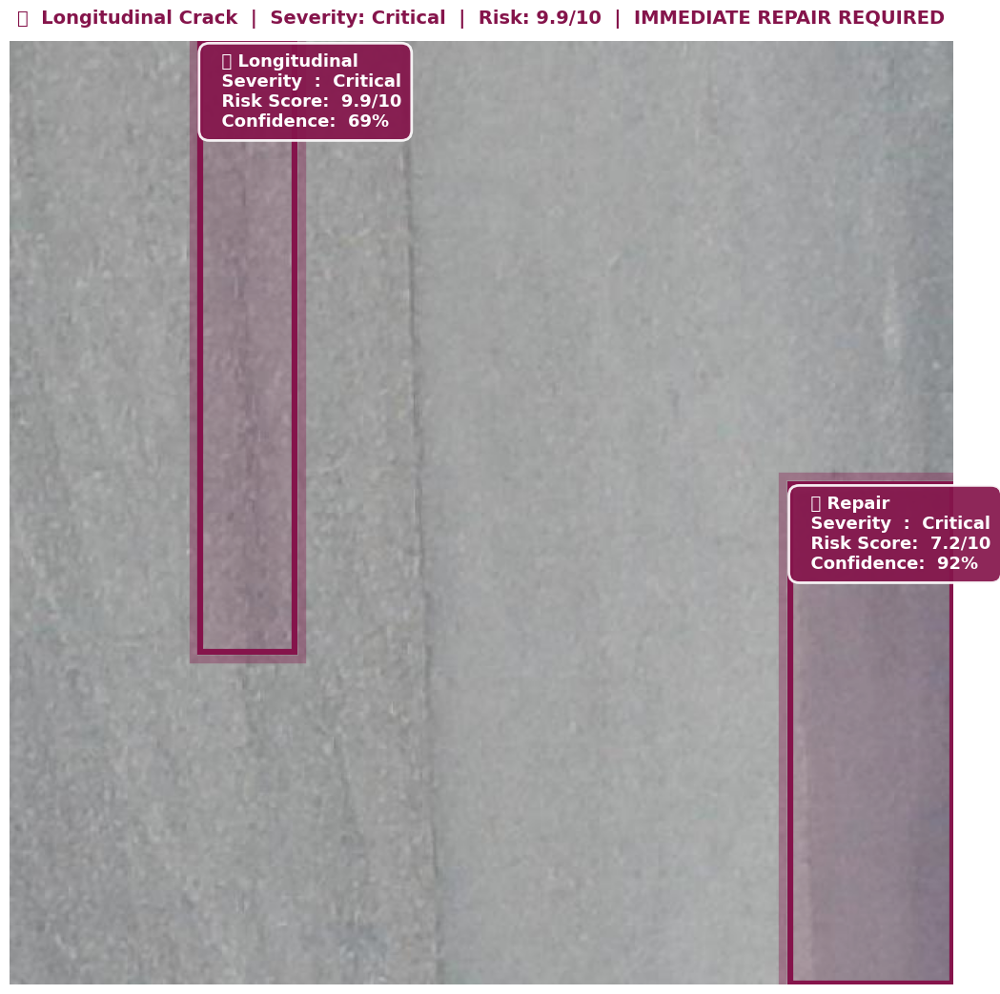

───────────────────────────────────────────────────────
  📸 0101_0_6_JPG.rf.30460d7bb0287e22eb5bc88c884a1d55.jpg
───────────────────────────────────────────────────────
  Crack #1  Repair
    🚨 Severity   : Critical
     Risk Score : 7.2/10
     Confidence : 92%
     Area       : 9.10% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #2  Longitudinal
    🚨 Severity   : Critical
     Risk Score : 9.9/10
     Confidence : 69%
     Area       : 6.47% of image
    Action     : IMMEDIATE REPAIR REQUIRED



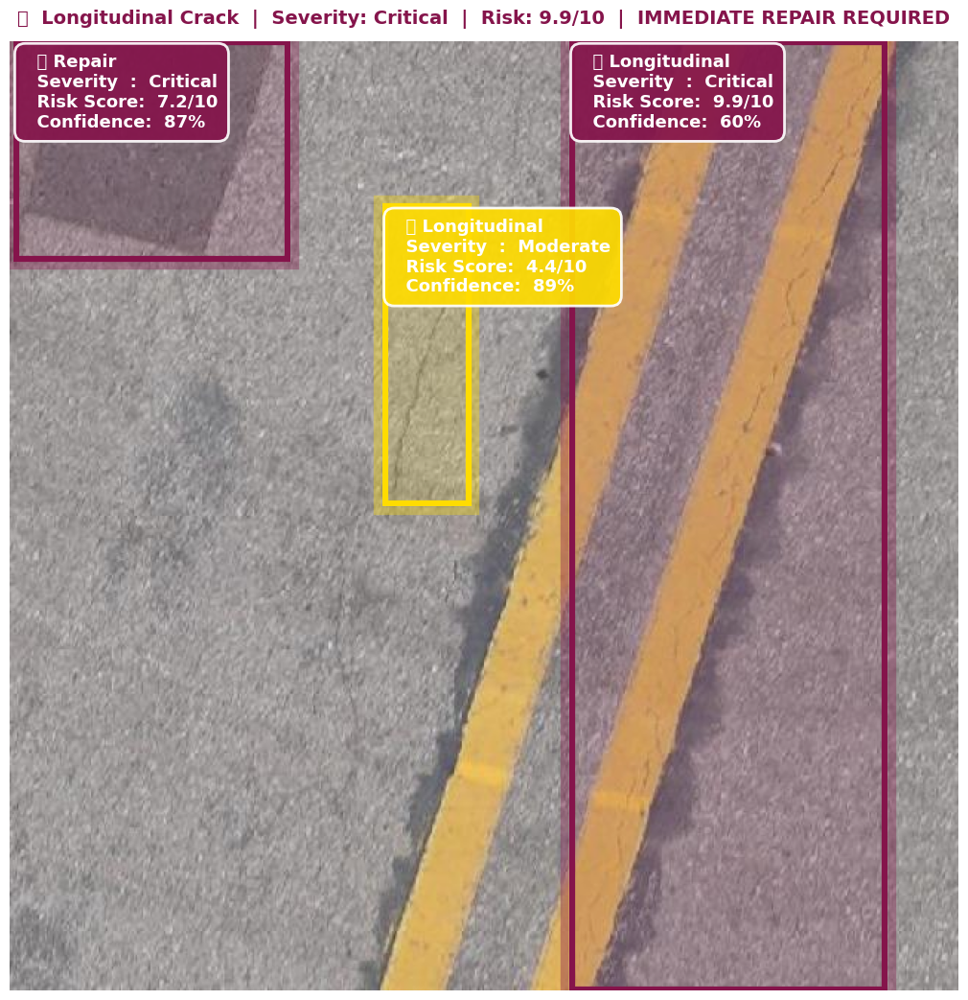

───────────────────────────────────────────────────────
  📸 0141_2_4_JPG.rf.4e03a5754e023117dc0d924a0da829b8.jpg
───────────────────────────────────────────────────────
  Crack #1  Longitudinal
    🟡 Severity   : Moderate
     Risk Score : 4.4/10
     Confidence : 89%
     Area       : 2.73% of image
    Action     : Schedule repair within 3 months
  Crack #2  Repair
    🚨 Severity   : Critical
     Risk Score : 7.2/10
     Confidence : 87%
     Area       : 6.52% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #3  Longitudinal
    🚨 Severity   : Critical
     Risk Score : 9.9/10
     Confidence : 60%
     Area       : 32.92% of image
    Action     : IMMEDIATE REPAIR REQUIRED



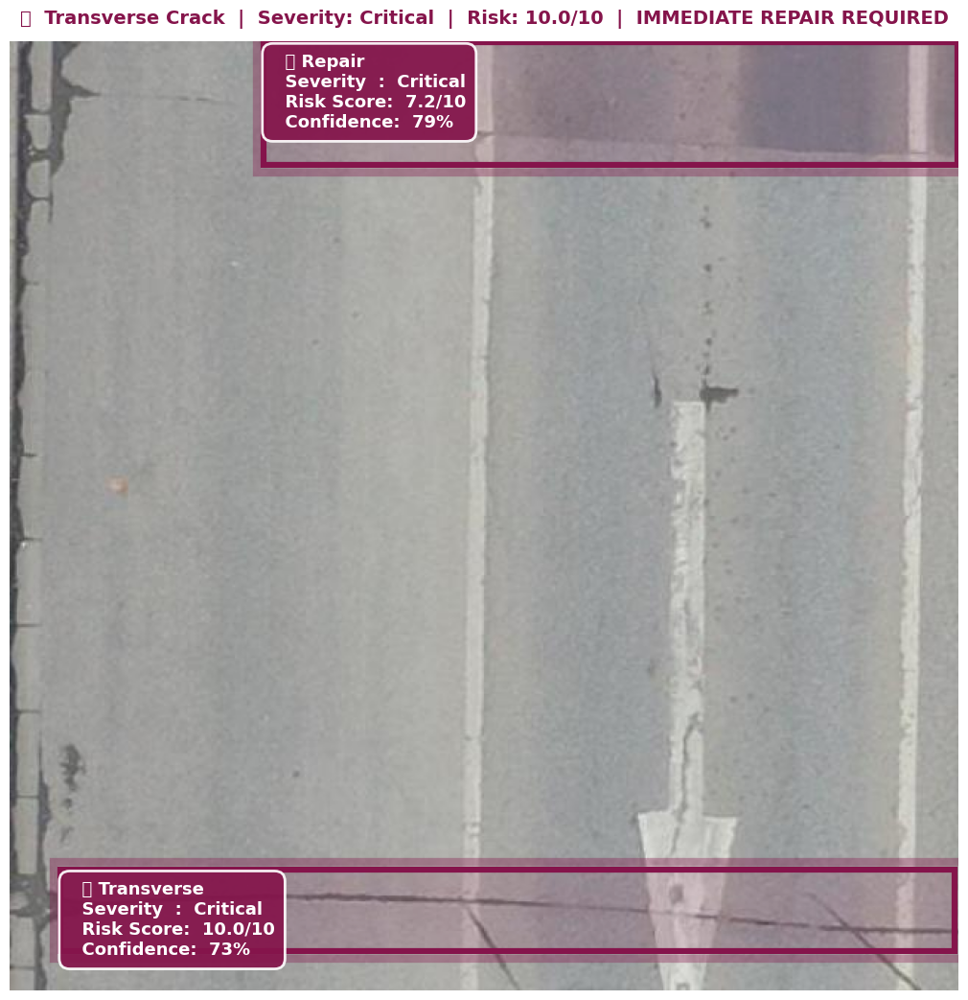

───────────────────────────────────────────────────────
  📸 0020_3_4_JPG.rf.78c77e5e892300500a10d14eb237da5a.jpg
───────────────────────────────────────────────────────
  Crack #1  Repair
    🚨 Severity   : Critical
     Risk Score : 7.2/10
     Confidence : 79%
     Area       : 9.48% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #2  Transverse
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 73%
     Area       : 8.10% of image
    Action     : IMMEDIATE REPAIR REQUIRED



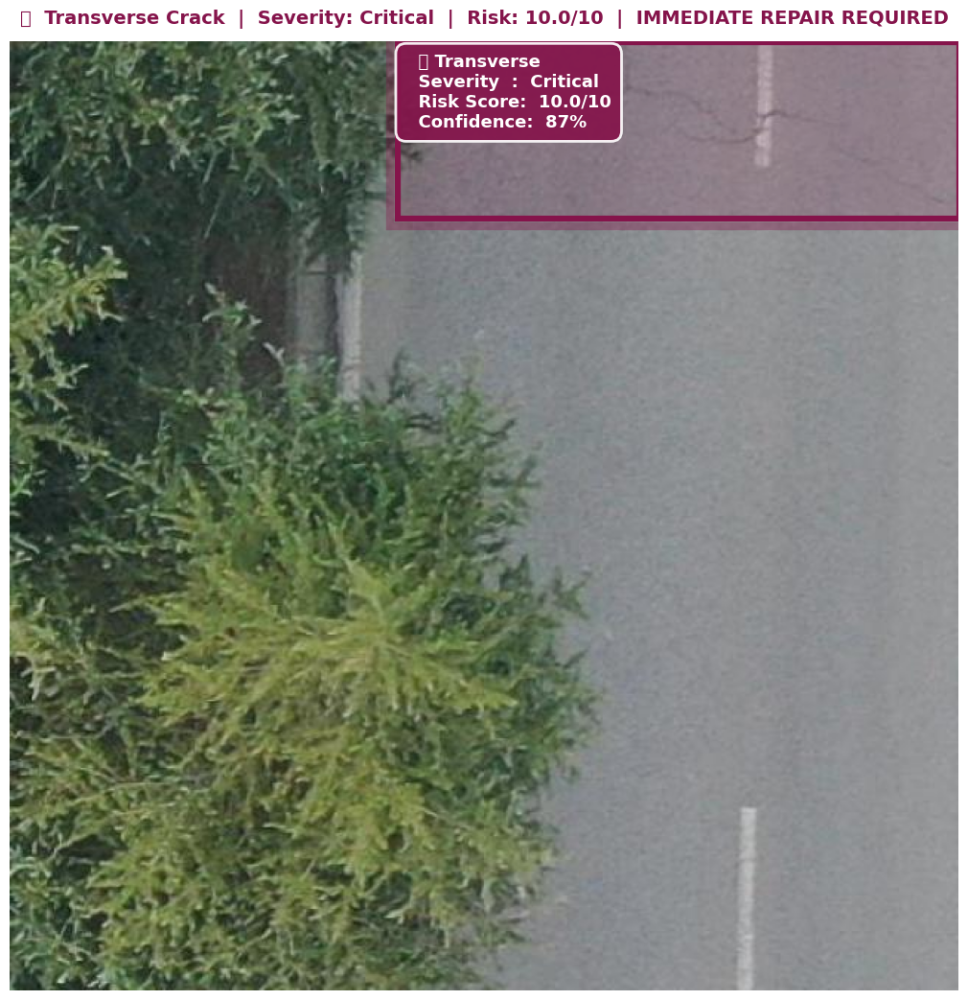

───────────────────────────────────────────────────────
  📸 0067_2_7_JPG.rf.13a466087e4336b60d471dc93f36b2ef.jpg
───────────────────────────────────────────────────────
  Crack #1  Transverse
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 87%
     Area       : 11.01% of image
    Action     : IMMEDIATE REPAIR REQUIRED



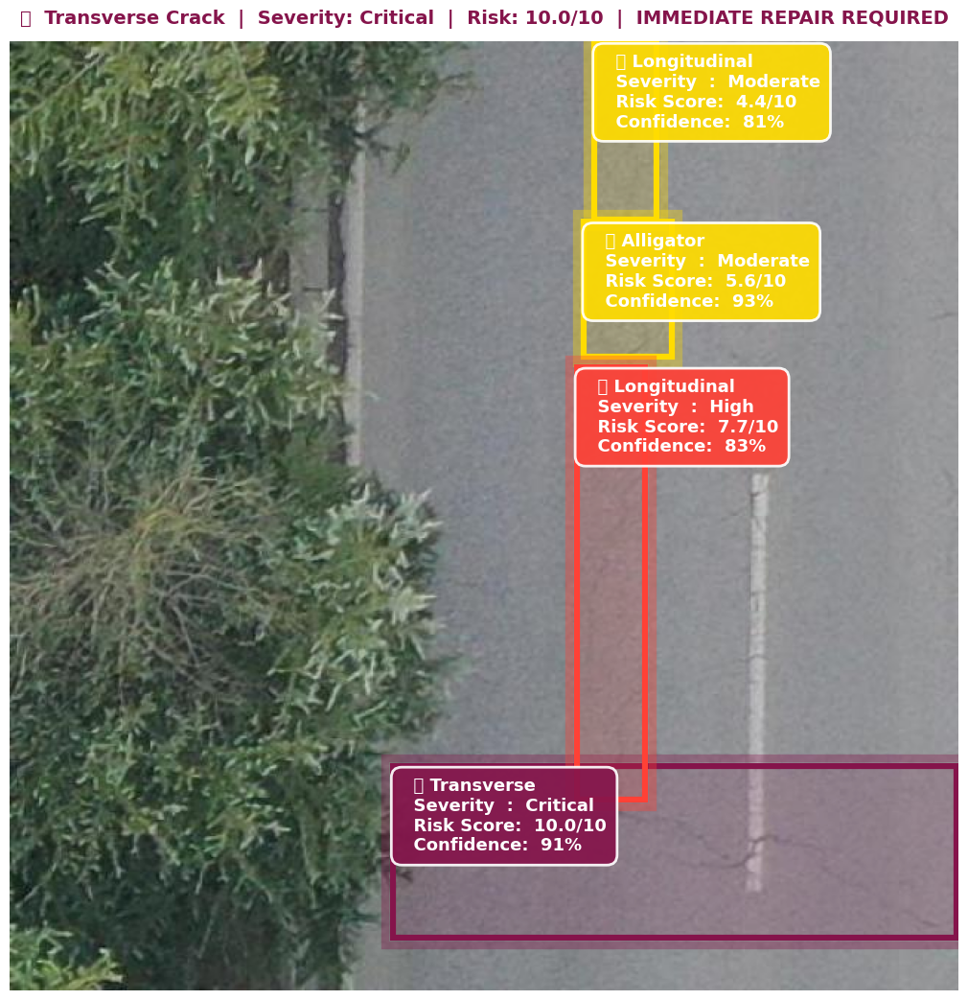

───────────────────────────────────────────────────────
  📸 0073_1_7_JPG.rf.70c87cc33e24d257cf2fd5dbb5d3bdb5.jpg
───────────────────────────────────────────────────────
  Crack #1  Alligator
    🟡 Severity   : Moderate
     Risk Score : 5.6/10
     Confidence : 93%
     Area       : 1.31% of image
    Action     : Schedule repair within 3 months
  Crack #2  Transverse
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 91%
     Area       : 10.76% of image
    Action     : IMMEDIATE REPAIR REQUIRED
  Crack #3  Longitudinal
    🔴 Severity   : High
     Risk Score : 7.7/10
     Confidence : 83%
     Area       : 3.28% of image
    Action     : Repair within 2 weeks
  Crack #4  Longitudinal
    🟡 Severity   : Moderate
     Risk Score : 4.4/10
     Confidence : 81%
     Area       : 1.23% of image
    Action     : Schedule repair within 3 months



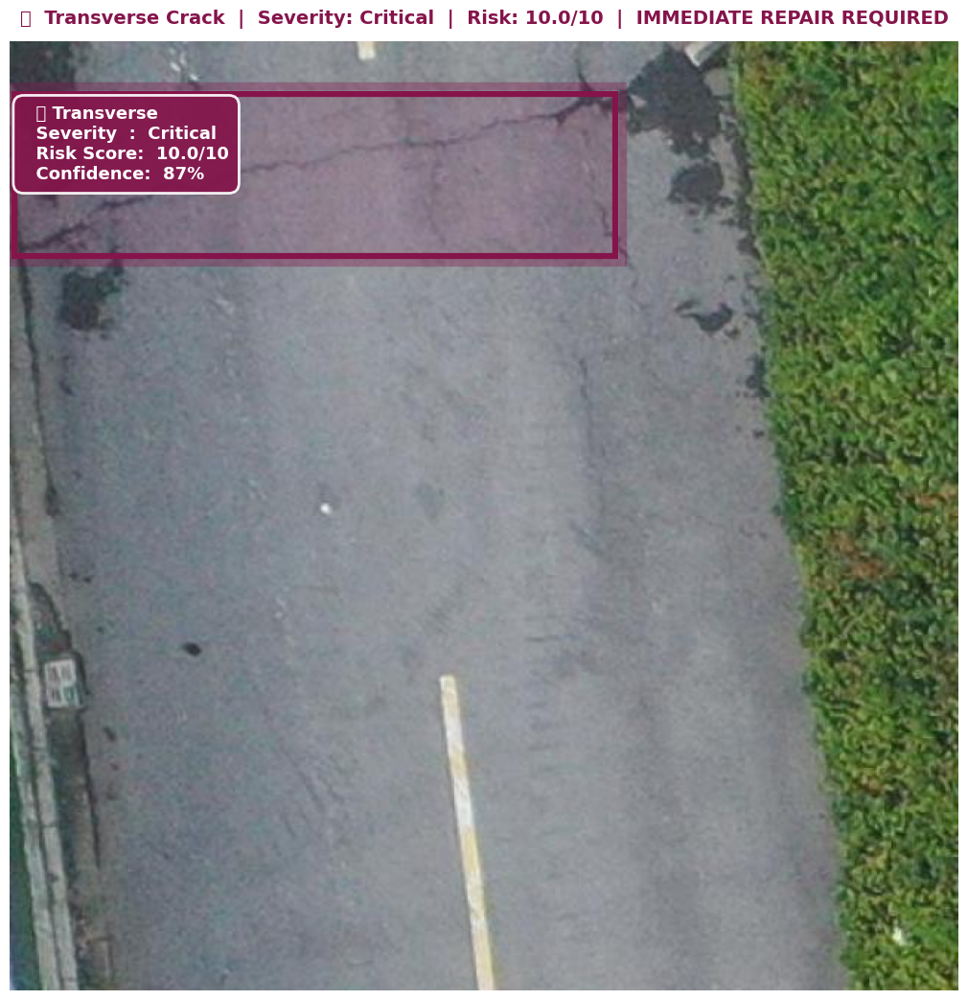

───────────────────────────────────────────────────────
  📸 0045_0_2_JPG.rf.b5b0817baf66c1824303c92125b1d034.jpg
───────────────────────────────────────────────────────
  Crack #1  Transverse
    🚨 Severity   : Critical
     Risk Score : 10.0/10
     Confidence : 87%
     Area       : 10.78% of image
    Action     : IMMEDIATE REPAIR REQUIRED



In [47]:


for idx, item in enumerate(presentation_images):
    img_path   = item['path']
    img_rgb    = item['img_rgb']
    detections = item['detections']

    # ── Big figure ───────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(16, 11))
    plt.subplots_adjust(left=0.01, right=0.99, top=0.91, bottom=0.01)

    ax.imshow(img_rgb)

    for d in detections:
        x1, y1, x2, y2 = d['bbox']
        color = d['color']
        emoji = SEVERITY_EMOJI[d['severity']]

        # Outer glow ring
        ax.add_patch(patches.Rectangle(
            (x1-5, y1-5), (x2-x1)+10, (y2-y1)+10,
            linewidth=6, edgecolor=color,
            facecolor='none', alpha=0.35
        ))
        # Transparent fill
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=0, facecolor=color, alpha=0.15
        ))
        # Solid border
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            linewidth=4.5, edgecolor=color, facecolor='none'
        ))

        # Big readable label
        label = (
            f"  {emoji} {d['crack_type']}\n"
            f"  Severity  :  {d['severity']}\n"
            f"  Risk Score:  {d['risk_score']}/10\n"
            f"  Confidence:  {d['confidence']:.0%}"
        )
        ax.text(
            x1 + 6, y1 + 8,
            label,
            fontsize=13,
            color='white',
            fontweight='bold',
            verticalalignment='top',
            bbox=dict(
                boxstyle='round,pad=0.6',
                facecolor=color,
                alpha=0.92,
                edgecolor='white',
                linewidth=2
            )
        )

    # ── Title bar ────────────────────────────────────────────
    worst     = max(detections, key=lambda x: x['risk_score'])
    max_risk  = worst['risk_score']
    t_color   = SEVERITY_COLORS[worst['severity']]
    emoji     = SEVERITY_EMOJI[worst['severity']]

    title = (
        f"{emoji}  {worst['crack_type']} Crack  |  "
        f"Severity: {worst['severity']}  |  "
        f"Risk: {max_risk}/10  |  "
        f"{worst['action']}"
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight='bold',
        color=t_color,
        pad=13,
        loc='center'
    )

    # Colored frame = severity level
    for spine in ax.spines.values():
        spine.set_edgecolor(t_color)
        spine.set_linewidth(7)

    ax.axis('off')

    save_path = f'/kaggle/working/presentation_{idx+1}_{worst["crack_type"]}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    # ── Clean console summary ────────────────────────────────
    print(f"{'─'*55}")
    print(f"  📸 {img_path.name}")
    print(f"{'─'*55}")
    for i, d in enumerate(detections, 1):
        emoji = SEVERITY_EMOJI[d['severity']]
        print(f"  Crack #{i}  {d['crack_type']}")
        print(f"    {emoji} Severity   : {d['severity']}")
        print(f"     Risk Score : {d['risk_score']}/10")
        print(f"     Confidence : {d['confidence']:.0%}")
        print(f"     Area       : {d['area_pct']:.2f}% of image")
        print(f"    Action     : {d['action']}")
    print()

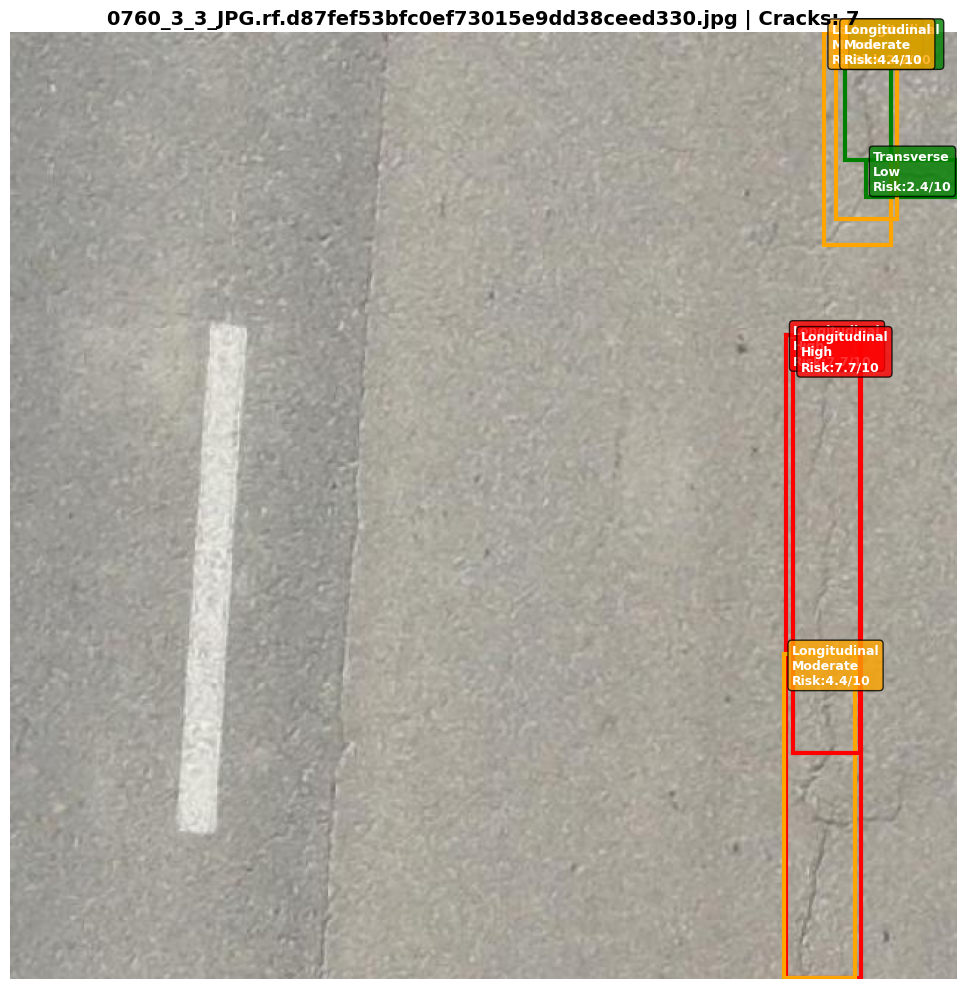


0760_3_3_JPG.rf.d87fef53bfc0ef73015e9dd38ceed330.jpg
1. Longitudinal | Conf:64% | Area:1.57% | Moderate | Risk:4.4/10
2. Longitudinal | Conf:63% | Area:5.42% | High | Risk:7.7/10
3. Transverse | Conf:57% | Area:0.37% | Low | Risk:2.4/10
4. Longitudinal | Conf:45% | Area:0.65% | Low | Risk:2.2/10
5. Longitudinal | Conf:34% | Area:2.57% | Moderate | Risk:4.4/10
6. Longitudinal | Conf:27% | Area:1.26% | Moderate | Risk:4.4/10
7. Longitudinal | Conf:23% | Area:3.07% | High | Risk:7.7/10


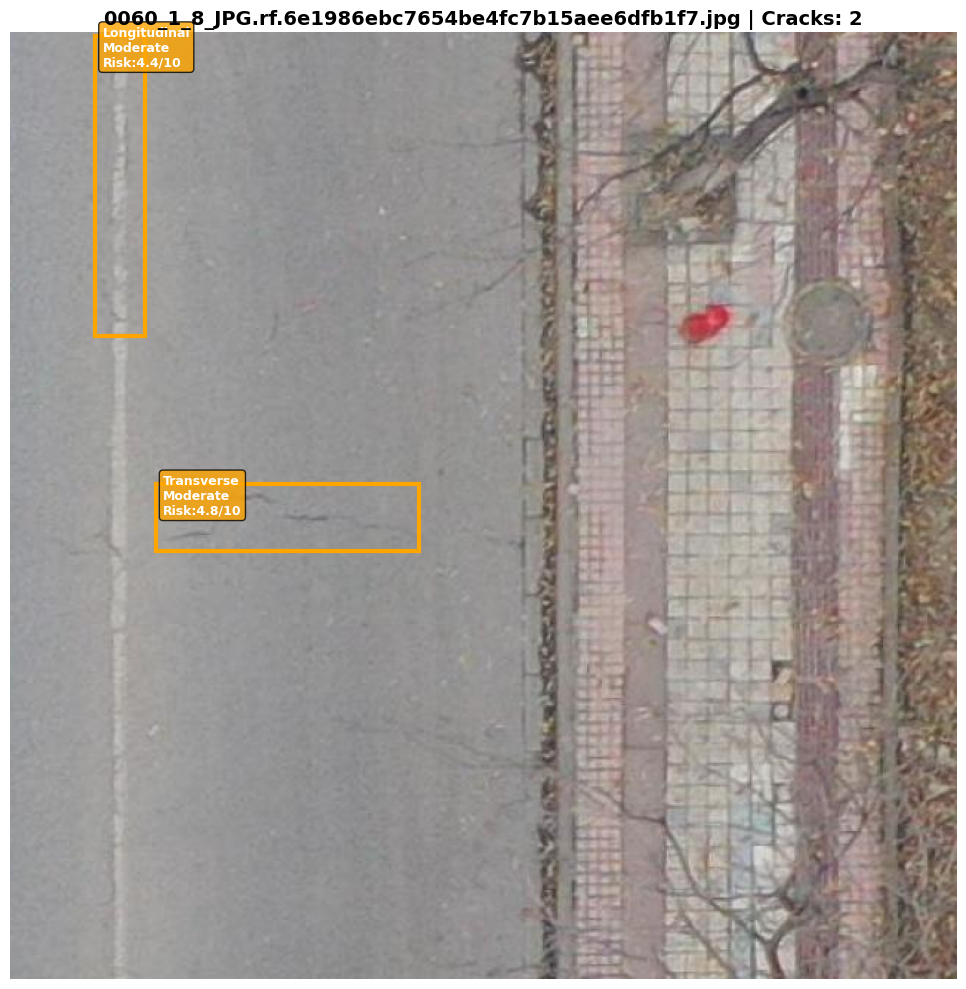


0060_1_8_JPG.rf.6e1986ebc7654be4fc7b15aee6dfb1f7.jpg
1. Transverse | Conf:71% | Area:1.96% | Moderate | Risk:4.8/10
2. Longitudinal | Conf:51% | Area:1.69% | Moderate | Risk:4.4/10


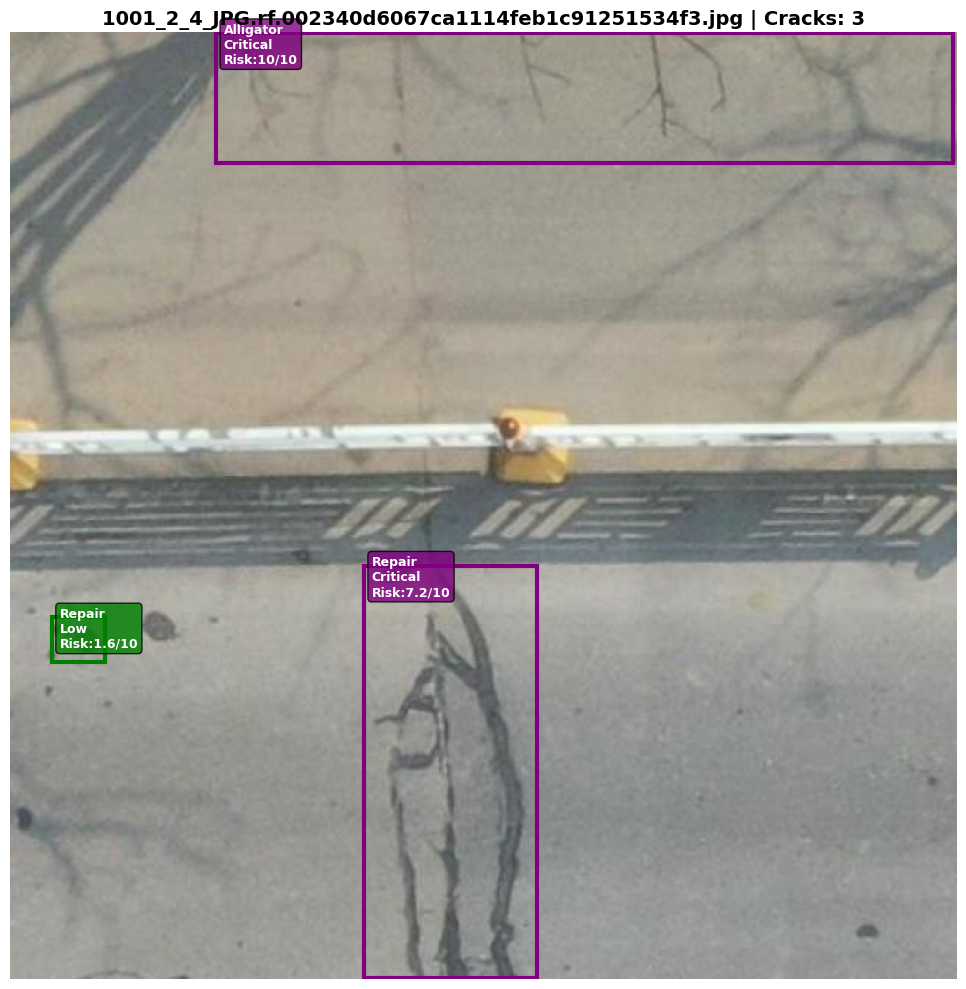


1001_2_4_JPG.rf.002340d6067ca1114feb1c91251534f3.jpg
1. Repair | Conf:88% | Area:7.97% | Critical | Risk:7.2/10
2. Alligator | Conf:45% | Area:10.7% | Critical | Risk:10/10
3. Repair | Conf:18% | Area:0.26% | Low | Risk:1.6/10


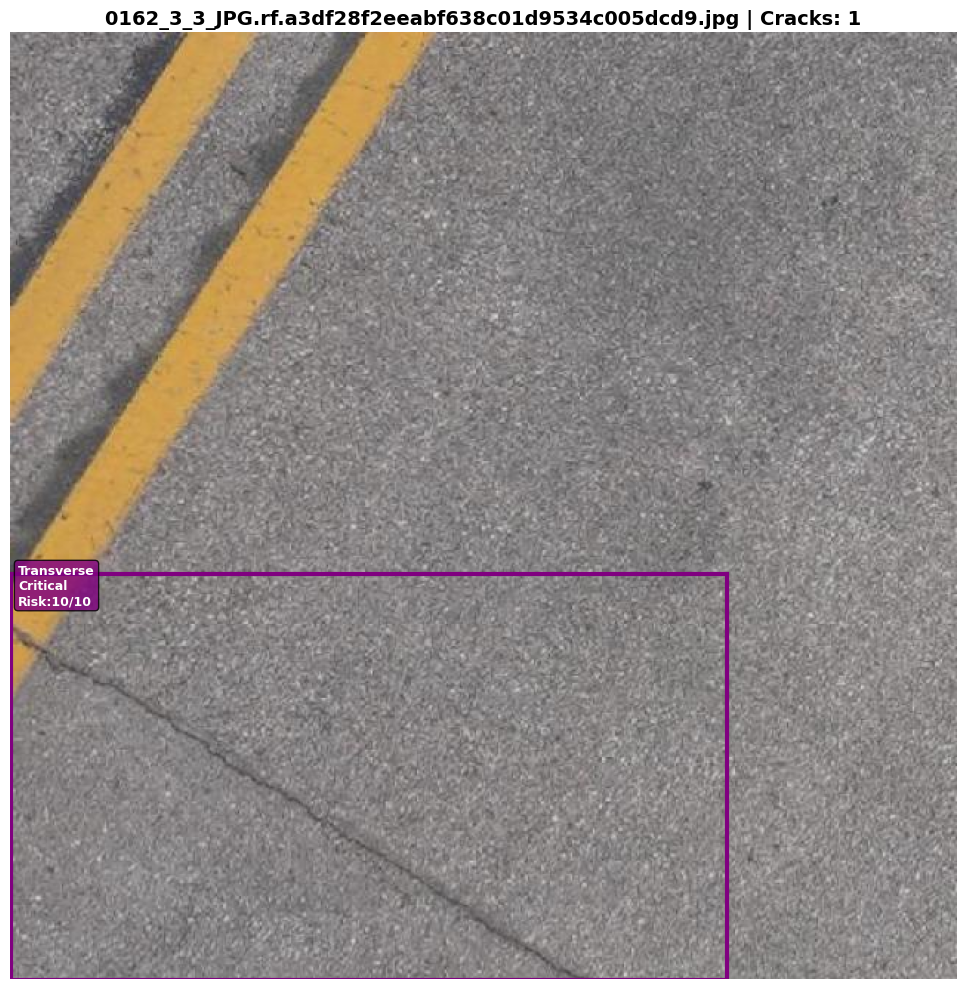


0162_3_3_JPG.rf.a3df28f2eeabf638c01d9534c005dcd9.jpg
1. Transverse | Conf:74% | Area:32.38% | Critical | Risk:10/10


In [116]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

# Load model
model = YOLO('/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt')
CLASS_NAMES = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']

# Severity function
def get_severity(area_pct, crack_type):
    if area_pct < 1.0: severity, risk = 'Low', 2
    elif area_pct < 3.0: severity, risk = 'Moderate', 4
    elif area_pct < 6.0: severity, risk = 'High', 7
    else: severity, risk = 'Critical', 9
    
    weights = {'Alligator': 1.4, 'Transverse': 1.2, 'Longitudinal': 1.1, 'Repair': 0.8}
    risk = min(10, round(risk * weights.get(crack_type, 1.0), 1))
    
    colors = {'Low': 'green', 'Moderate': 'orange', 'High': 'red', 'Critical': 'purple'}
    return severity, colors[severity], risk

# Process single image
def process_image(image_path, conf=0.18):
    img = cv2.imread(str(image_path))
    if img is None: return
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    results = model(image_path, conf=conf, verbose=False)
    
    # Create plot
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(img_rgb)
    
    detections = []
    if results[0].boxes:
        for box in results[0].boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            class_id = int(box.cls[0])
            conf_score = float(box.conf[0])
            crack_type = CLASS_NAMES[class_id]
            area_pct = round(((x2-x1)*(y2-y1)) / (h*w) * 100, 2)
            
            severity, color, risk = get_severity(area_pct, crack_type)
            
            # Draw box
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=3, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            
            # Label
            ax.text(x1+5, y1+20, f"{crack_type}\n{severity}\nRisk:{risk}/10", 
                   fontsize=9, color='white', weight='bold',
                   bbox=dict(boxstyle='round', facecolor=color, alpha=0.8))
            
            detections.append([crack_type, conf_score, area_pct, severity, risk])
    
    ax.set_title(f"{Path(image_path).name} | Cracks: {len(detections)}", fontsize=14, weight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Print results
    print(f"\n{'='*50}\n{Path(image_path).name}\n{'='*50}")
    for i, d in enumerate(detections, 1):
        print(f"{i}. {d[0]} | Conf:{d[1]:.0%} | Area:{d[2]}% | {d[3]} | Risk:{d[4]}/10")
    if not detections: print("✅ No cracks detected")
    
    return detections

# Test on 4 random images
test_images = list(Path('/kaggle/working/crack_4class/valid/images').glob('*.jpg'))
import random
random.seed(42)

for img in random.sample(test_images, 4):
    process_image(img, conf=0.18)

In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
import random

# Load model
model = YOLO('/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt')
CLASS_NAMES = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']

def get_risk(area_pct, crack_type):
    """Calculate risk score (1-10)"""
    if area_pct < 1.0: base = 2
    elif area_pct < 3.0: base = 4
    elif area_pct < 6.0: base = 7
    else: base = 9
    
    weights = {'Alligator': 1.5, 'Transverse': 1.3, 'Longitudinal': 1.1, 'Repair': 0.7}
    risk = min(10, round(base * weights.get(crack_type, 1.0), 1))
    
    if risk >= 7: severity, color = 'HIGH', 'red'
    elif risk >= 4: severity, color = 'MEDIUM', 'orange'
    else: severity, color = 'LOW', 'green'
    
    return risk, severity, color

def show_cracks(image_path, conf=0.18):
    """Display image with crack detection and risk scores"""
    img = cv2.imread(str(image_path))
    if img is None: return
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    results = model(image_path, conf=conf, verbose=False)
    
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(img_rgb)
    
    detections = []
    if results[0].boxes:
        for box in results[0].boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            class_id = int(box.cls[0])
            crack_type = CLASS_NAMES[class_id]
            area_pct = round(((x2-x1)*(y2-y1)) / (h*w) * 100, 2)
            
            risk, severity, color = get_risk(area_pct, crack_type)
            
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=3, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            ax.text(x1+5, y1+20, f"{crack_type}\n{severity}\nRisk:{risk}/10", 
                   fontsize=9, color='white', weight='bold',
                   bbox=dict(boxstyle='round', facecolor=color, alpha=0.8))
            
            detections.append([crack_type, area_pct, risk, severity])
    
    ax.set_title(f"{image_path.name} | High Risk Cracks: {len([d for d in detections if d[2]>=7])}", fontsize=12)
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Print high risk only
    for d in detections:
        if d[2] >= 7:
            print(f" {d[0]} | Area: {d[1]}% | Risk: {d[2]}/10 | {d[3]} RISK")

# Test on validation images
test_images = list(Path('/kaggle/working/crack_4class/valid/images').glob('*.jpg'))
for img in random.sample(test_images, 6):
    show_cracks(img, conf=0.18)

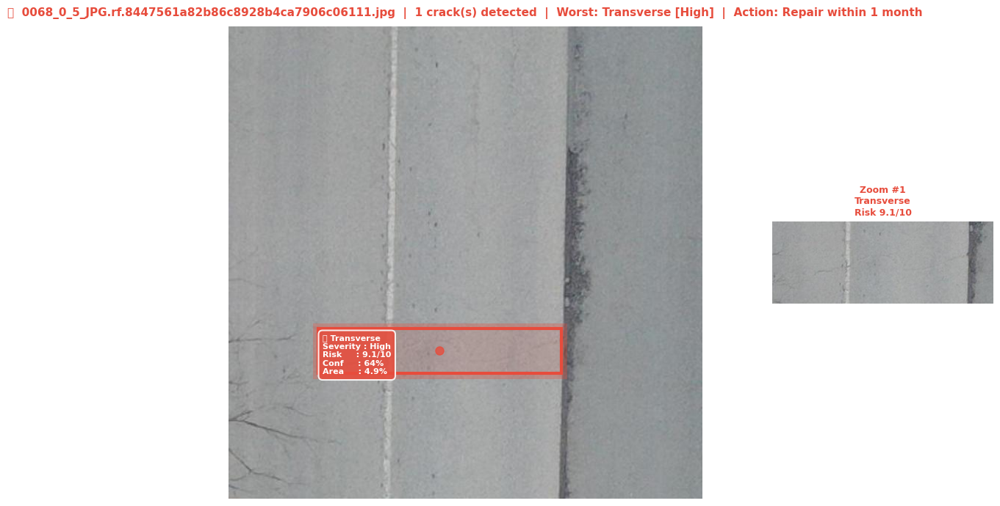


═══════════════════════════════════════════════════════
  📸 0068_0_5_JPG.rf.8447561a82b86c8928b4ca7906c06111.jpg  |  1 crack(s) found
═══════════════════════════════════════════════════════
  1. 🔴 Transverse    | Conf: 64% | Area:   4.9% | Risk:  9.1/10 | High
     → Repair within 1 month



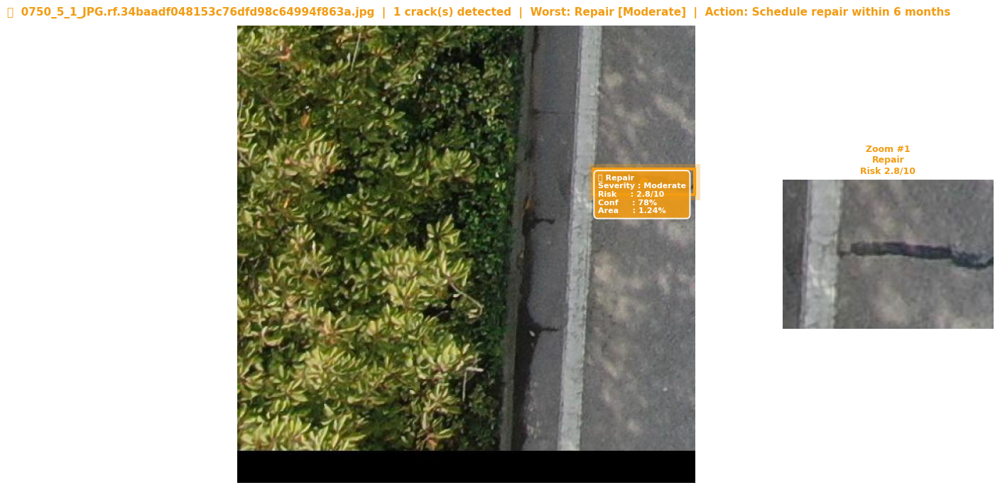


═══════════════════════════════════════════════════════
  📸 0750_5_1_JPG.rf.34baadf048153c76dfd98c64994f863a.jpg  |  1 crack(s) found
═══════════════════════════════════════════════════════
  1. 🟡 Repair        | Conf: 78% | Area:  1.24% | Risk:  2.8/10 | Moderate
     → Schedule repair within 6 months



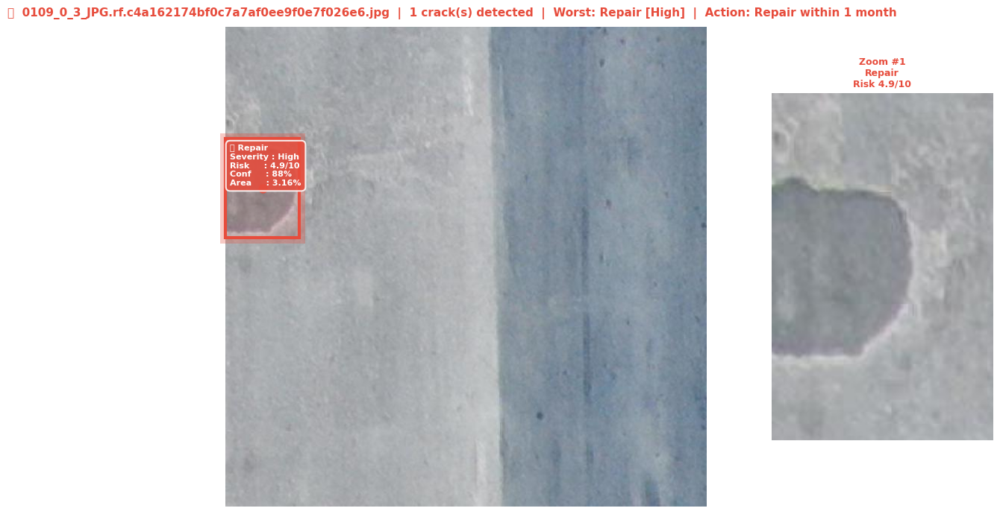


═══════════════════════════════════════════════════════
  📸 0109_0_3_JPG.rf.c4a162174bf0c7a7af0ee9f0e7f026e6.jpg  |  1 crack(s) found
═══════════════════════════════════════════════════════
  1. 🔴 Repair        | Conf: 88% | Area:  3.16% | Risk:  4.9/10 | High
     → Repair within 1 month



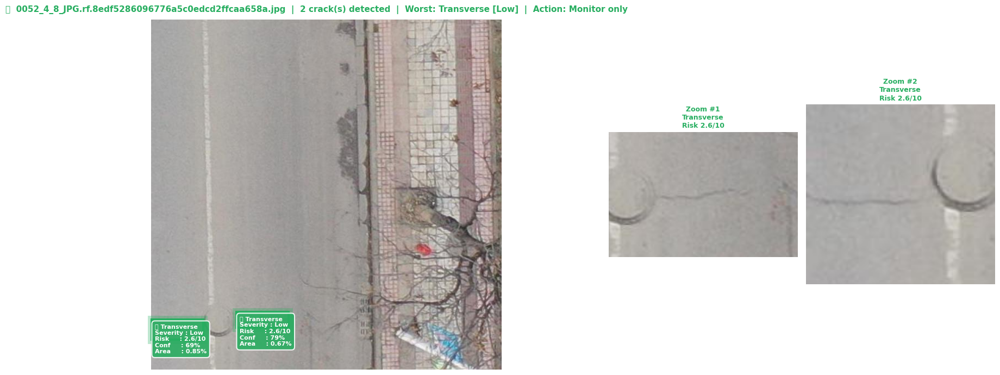


═══════════════════════════════════════════════════════
  📸 0052_4_8_JPG.rf.8edf5286096776a5c0edcd2ffcaa658a.jpg  |  2 crack(s) found
═══════════════════════════════════════════════════════
  1. 🟢 Transverse    | Conf: 79% | Area:  0.67% | Risk:  2.6/10 | Low
     → Monitor only
  2. 🟢 Transverse    | Conf: 69% | Area:  0.85% | Risk:  2.6/10 | Low
     → Monitor only



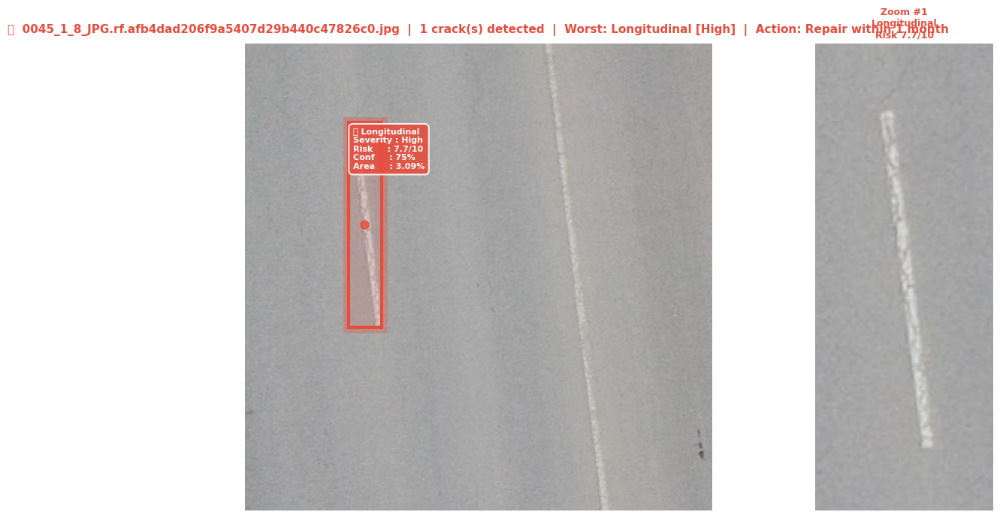


═══════════════════════════════════════════════════════
  📸 0045_1_8_JPG.rf.afb4dad206f9a5407d29b440c47826c0.jpg  |  1 crack(s) found
═══════════════════════════════════════════════════════
  1. 🔴 Longitudinal  | Conf: 75% | Area:  3.09% | Risk:  7.7/10 | High
     → Repair within 1 month



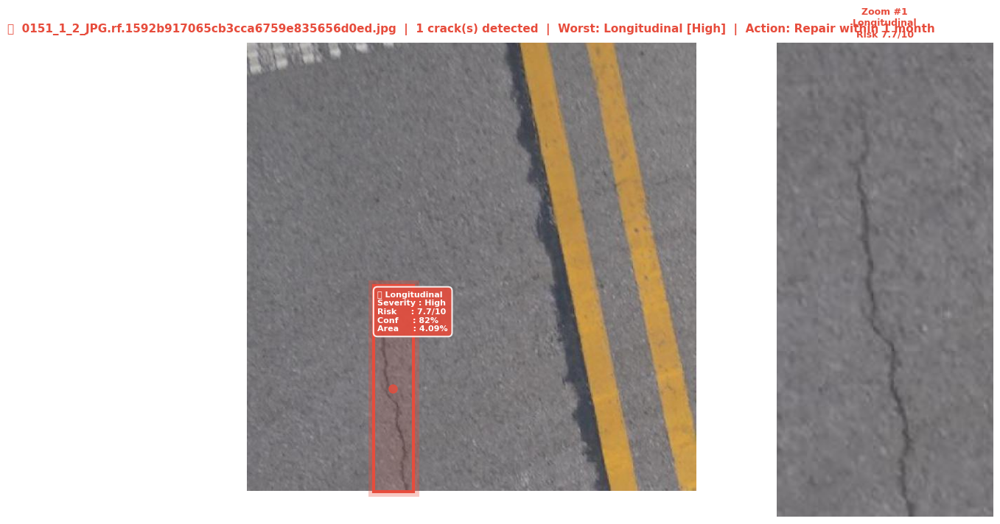


═══════════════════════════════════════════════════════
  📸 0151_1_2_JPG.rf.1592b917065cb3cca6759e835656d0ed.jpg  |  1 crack(s) found
═══════════════════════════════════════════════════════
  1. 🔴 Longitudinal  | Conf: 82% | Area:  4.09% | Risk:  7.7/10 | High
     → Repair within 1 month



In [12]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
import random

# ── Config ───────────────────────────────────────────────────────────────────
MODEL_PATH  = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
TEST_DIR    = '/kaggle/working/crack_4class/test/images'
CLASS_NAMES = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']
CONF        = 0.18
N_IMAGES    = 6          # how many test images to show

# Severity config
SEVERITY_MAP = {
    'Low':      {'threshold': 1.0,  'color': '#27ae60', 'emoji': '🟢', 'risk_base': 2},
    'Moderate': {'threshold': 3.0,  'color': '#f39c12', 'emoji': '🟡', 'risk_base': 4},
    'High':     {'threshold': 6.0,  'color': '#e74c3c', 'emoji': '🔴', 'risk_base': 7},
    'Critical': {'threshold': 999,  'color': '#8e44ad', 'emoji': '🟣', 'risk_base': 9},
}
TYPE_WEIGHTS = {'Alligator': 1.5, 'Transverse': 1.3, 'Longitudinal': 1.1, 'Repair': 0.7}
ACTIONS = {
    'Low':      'Monitor only',
    'Moderate': 'Schedule repair within 6 months',
    'High':     'Repair within 1 month',
    'Critical': 'Immediate repair required',
}

# ── Helper functions ─────────────────────────────────────────────────────────
def get_severity(area_pct, crack_type):
    for level, cfg in SEVERITY_MAP.items():
        if area_pct < cfg['threshold']:
            risk = min(10, round(cfg['risk_base'] * TYPE_WEIGHTS.get(crack_type, 1.0), 1))
            return level, cfg['color'], cfg['emoji'], risk
    cfg = list(SEVERITY_MAP.values())[-1]
    return 'Critical', cfg['color'], cfg['emoji'], 9.0

def zoom_crack(img_rgb, x1, y1, x2, y2, pad=40):
    """Return a padded crop around a detected crack."""
    h, w = img_rgb.shape[:2]
    x1c = max(0, x1 - pad);  y1c = max(0, y1 - pad)
    x2c = min(w, x2 + pad);  y2c = min(h, y2 + pad)
    return img_rgb[y1c:y2c, x1c:x2c]

# ── Model load ───────────────────────────────────────────────────────────────
model = YOLO(MODEL_PATH)
test_images = list(Path(TEST_DIR).glob('*.jpg'))
random.seed(42)
samples = random.sample(test_images, min(N_IMAGES, len(test_images)))

# ── Main prediction loop ─────────────────────────────────────────────────────
for img_path in samples:
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w    = img_rgb.shape[:2]

    results    = model(img_path, conf=CONF, verbose=False)
    boxes_data = results[0].boxes
    detections = []

    if boxes_data:
        for box in boxes_data:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            crack_type      = CLASS_NAMES[int(box.cls[0])]
            conf_score      = float(box.conf[0])
            area_pct        = round(((x2 - x1) * (y2 - y1)) / (h * w) * 100, 2)
            severity, color, emoji, risk = get_severity(area_pct, crack_type)
            detections.append(dict(x1=x1, y1=y1, x2=x2, y2=y2,
                                   crack_type=crack_type, conf=conf_score,
                                   area_pct=area_pct, severity=severity,
                                   color=color, emoji=emoji, risk=risk))

    n_cracks = len(detections)
    n_zooms  = min(n_cracks, 3)          # zoom up to 3 crops per image

    # ── Layout: full image | up to 3 zoomed crops ────────────────────────────
    n_cols = 1 + n_zooms
    fig, axes = plt.subplots(1, n_cols, figsize=(6 * n_cols, 7),
                             gridspec_kw={'width_ratios': [3] + [1] * n_zooms})
    if n_cols == 1:
        axes = [axes]

    # ── Left panel: full image with all detections ────────────────────────────
    ax = axes[0]
    ax.imshow(img_rgb)

    for d in detections:
        x1, y1, x2, y2 = d['x1'], d['y1'], d['x2'], d['y2']
        color = d['color']

        # Glow ring
        ax.add_patch(patches.Rectangle(
            (x1 - 4, y1 - 4), (x2 - x1) + 8, (y2 - y1) + 8,
            linewidth=5, edgecolor=color, facecolor='none', alpha=0.3))
        # Fill
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=0, facecolor=color, alpha=0.12))
        # Border
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=3, edgecolor=color, facecolor='none'))

        # Risk area indicator (center dot)
        cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
        ax.plot(cx, cy, 'o', color=color, markersize=8, alpha=0.8)

        # Label box
        label = (f"{d['emoji']} {d['crack_type']}\n"
                 f"Severity : {d['severity']}\n"
                 f"Risk     : {d['risk']}/10\n"
                 f"Conf     : {d['conf']:.0%}\n"
                 f"Area     : {d['area_pct']}%")
        ax.text(x1 + 6, y1 + 8, label,
                fontsize=8, color='white', fontweight='bold',
                verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.5', facecolor=color,
                          alpha=0.88, edgecolor='white', linewidth=1.5))

    # Title with worst crack
    if detections:
        worst = max(detections, key=lambda d: d['risk'])
        title = (f"{worst['emoji']}  {img_path.name}  |  "
                 f"{n_cracks} crack(s) detected  |  "
                 f"Worst: {worst['crack_type']} [{worst['severity']}]  |  "
                 f"Action: {ACTIONS[worst['severity']]}")
        title_color = worst['color']
    else:
        title = f"  {img_path.name}  |  No cracks detected"
        title_color = 'green'

    ax.set_title(title, fontsize=11, fontweight='bold', color=title_color, pad=10)
    for spine in ax.spines.values():
        spine.set_edgecolor(title_color); spine.set_linewidth(5)
    ax.axis('off')

    # ── Right panels: zoomed crops for each crack ─────────────────────────────
    for i, d in enumerate(detections[:n_zooms]):
        crop = zoom_crack(img_rgb, d['x1'], d['y1'], d['x2'], d['y2'], pad=50)
        axes[i + 1].imshow(crop)
        axes[i + 1].set_title(f"Zoom #{i+1}\n{d['crack_type']}\nRisk {d['risk']}/10",
                               fontsize=9, fontweight='bold', color=d['color'])
        for spine in axes[i + 1].spines.values():
            spine.set_edgecolor(d['color']); spine.set_linewidth(3)
        axes[i + 1].axis('off')

    plt.tight_layout()
    plt.savefig(f'/kaggle/working/result_{img_path.stem}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    # ── Console summary ───────────────────────────────────────────────────────
    print(f"\n{'═'*55}")
    print(f"  {img_path.name}  |  {n_cracks} crack(s) found")
    print(f"{'═'*55}")
    for i, d in enumerate(detections, 1):
        print(f"  {i}. {d['emoji']} {d['crack_type']:<13} | "
              f"Conf: {d['conf']:.0%} | Area: {d['area_pct']:>5}% | "
              f"Risk: {d['risk']:>4}/10 | {d['severity']}")
        print(f"     → {ACTIONS[d['severity']]}")
    if not detections:
        print("   No cracks detected")
    print()

▶  Simulating live feed on 20 frames...



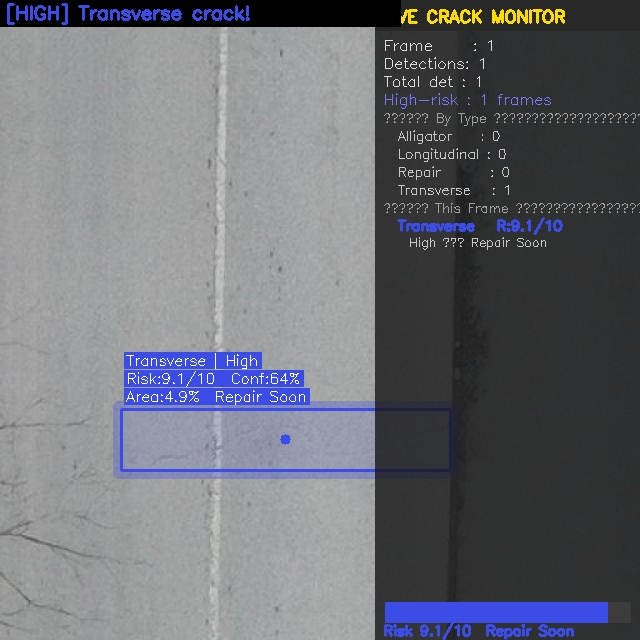

Frame 001 | 1 crack(s)  → Transverse [High] R:9.1/10


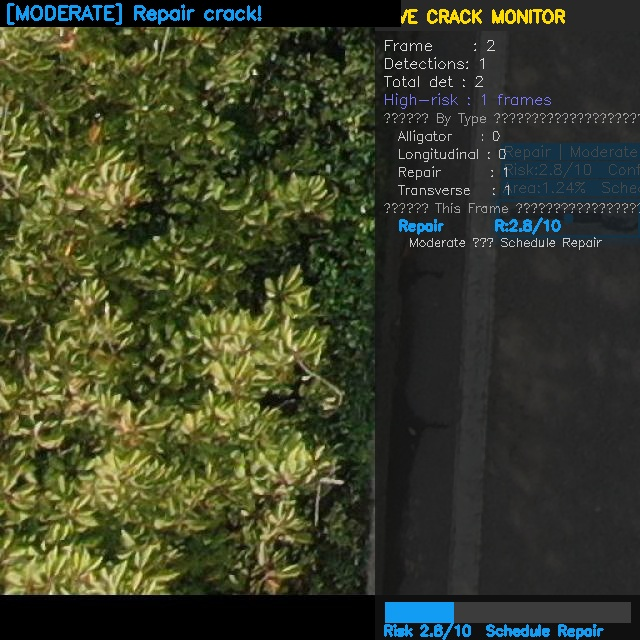

Frame 002 | 1 crack(s)  → Repair [Moderate] R:2.8/10


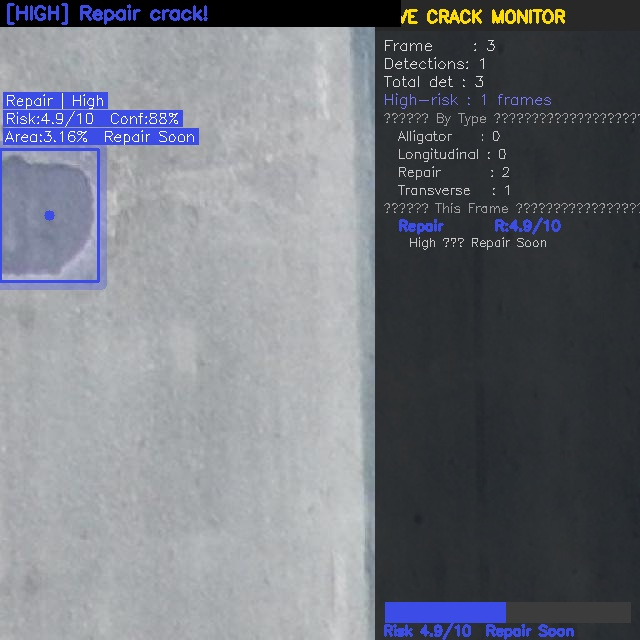

Frame 003 | 1 crack(s)  → Repair [High] R:4.9/10


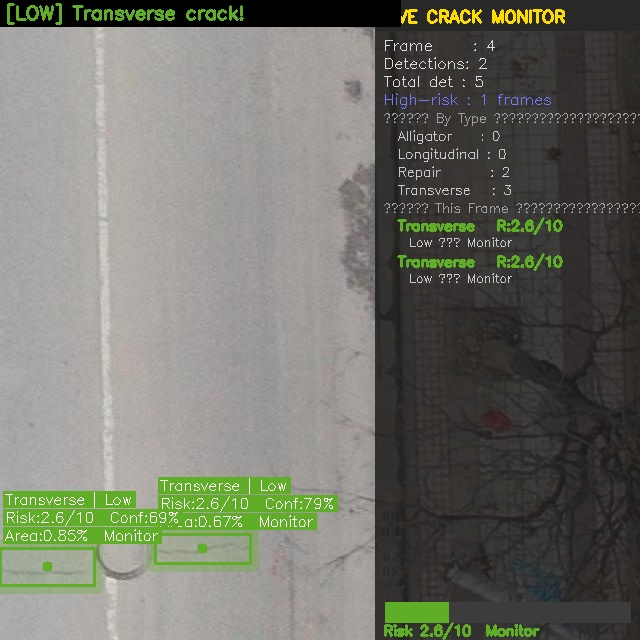

Frame 004 | 2 crack(s)  → Transverse [Low] R:2.6/10  → Transverse [Low] R:2.6/10


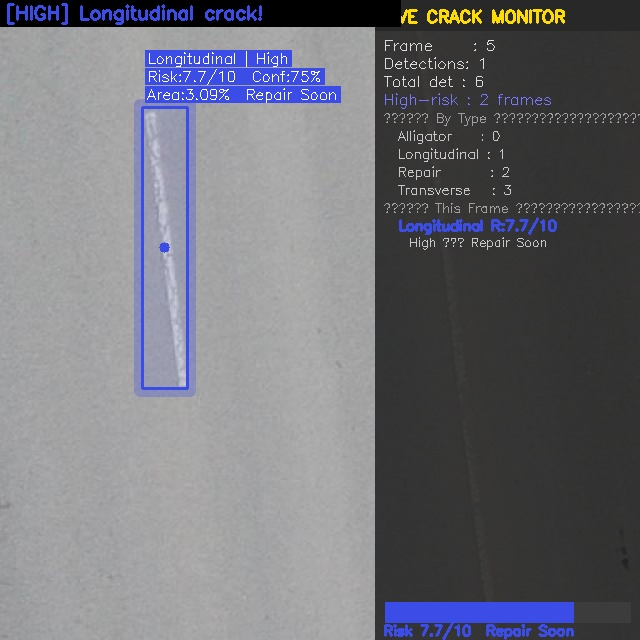

Frame 005 | 1 crack(s)  → Longitudinal [High] R:7.7/10


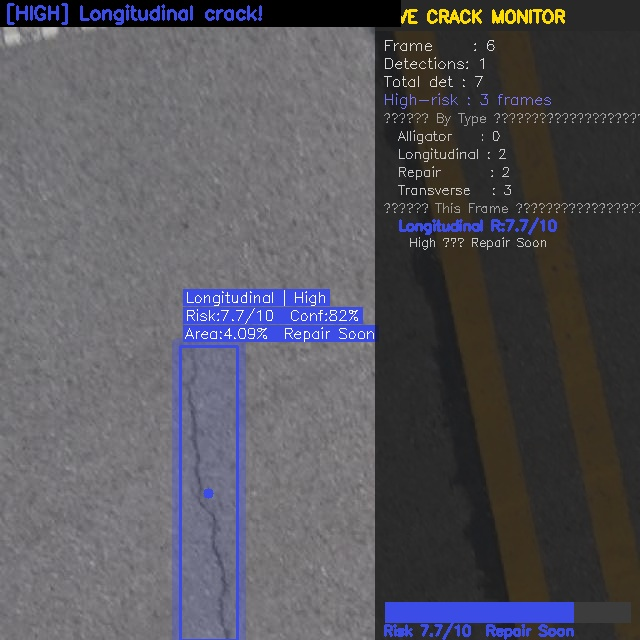

Frame 006 | 1 crack(s)  → Longitudinal [High] R:7.7/10


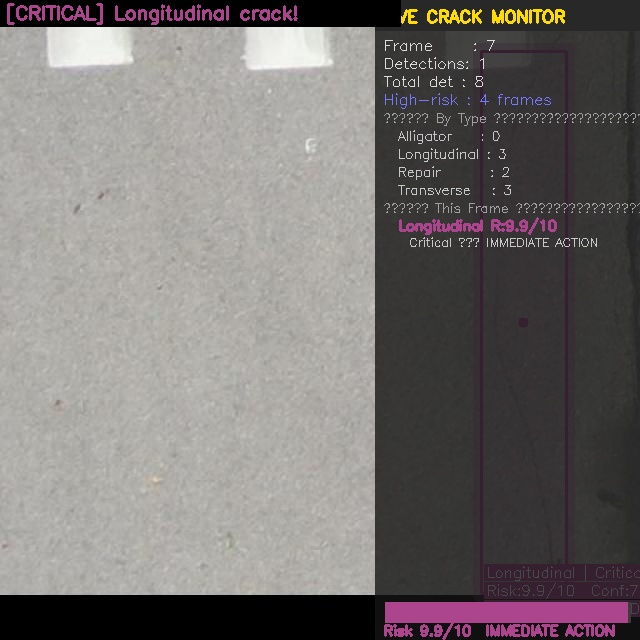

Frame 007 | 1 crack(s)  → Longitudinal [Critical] R:9.9/10


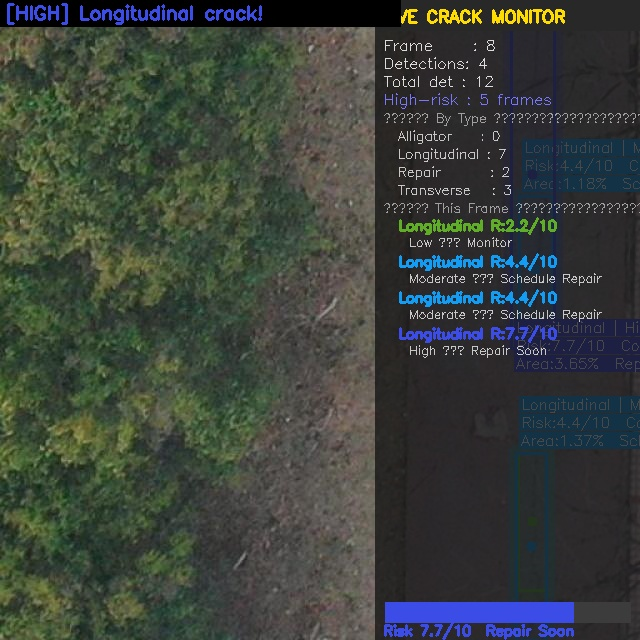

Frame 008 | 4 crack(s)  → Longitudinal [Low] R:2.2/10  → Longitudinal [Moderate] R:4.4/10  → Longitudinal [Moderate] R:4.4/10  → Longitudinal [High] R:7.7/10


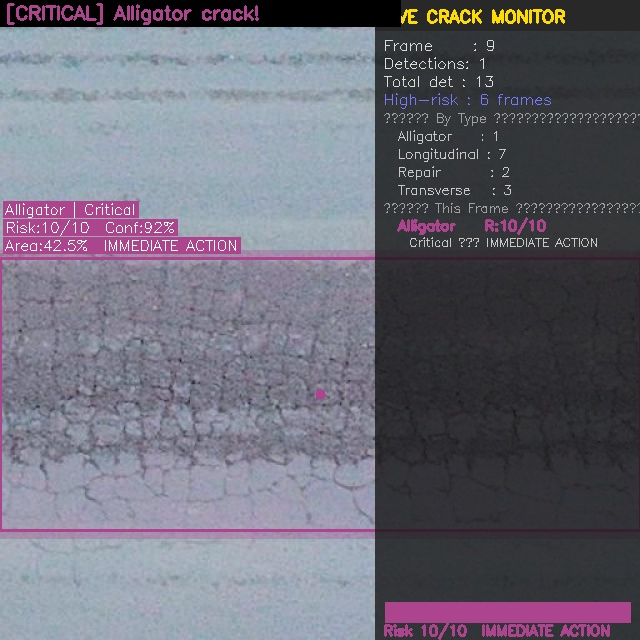

Frame 009 | 1 crack(s)  → Alligator [Critical] R:10/10


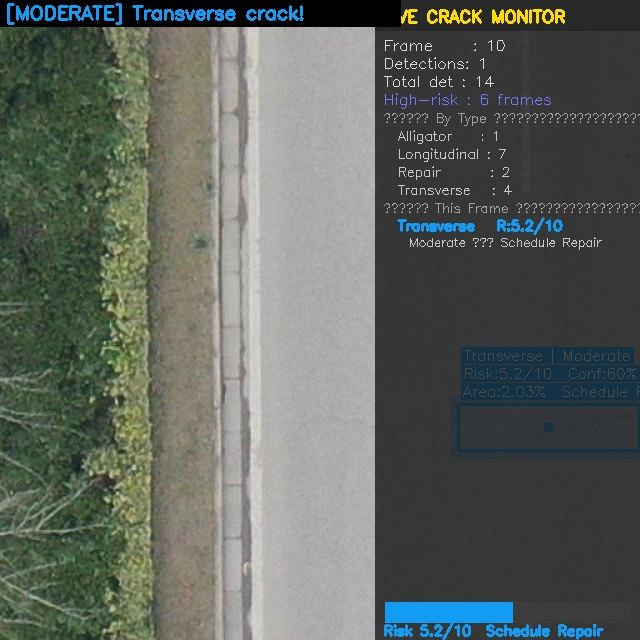

Frame 010 | 1 crack(s)  → Transverse [Moderate] R:5.2/10


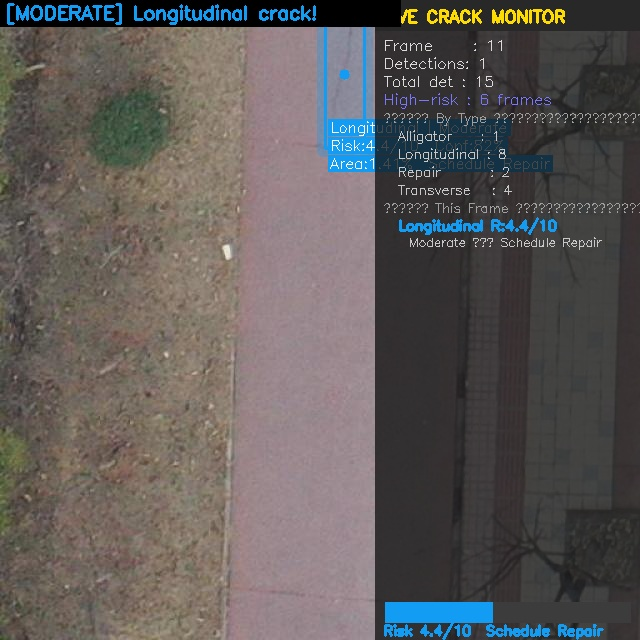

Frame 011 | 1 crack(s)  → Longitudinal [Moderate] R:4.4/10


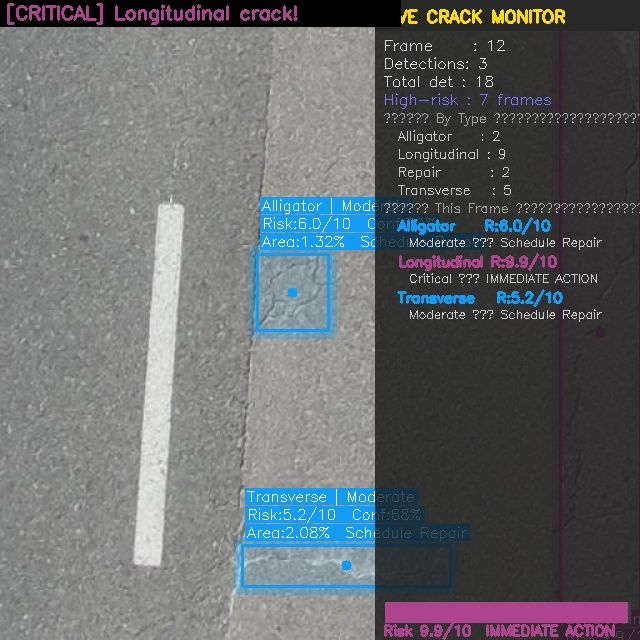

Frame 012 | 3 crack(s)  → Alligator [Moderate] R:6.0/10  → Longitudinal [Critical] R:9.9/10  → Transverse [Moderate] R:5.2/10


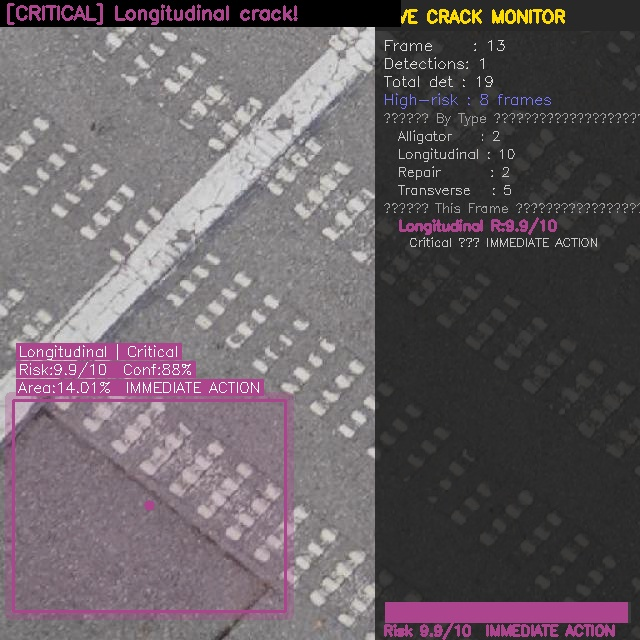

Frame 013 | 1 crack(s)  → Longitudinal [Critical] R:9.9/10


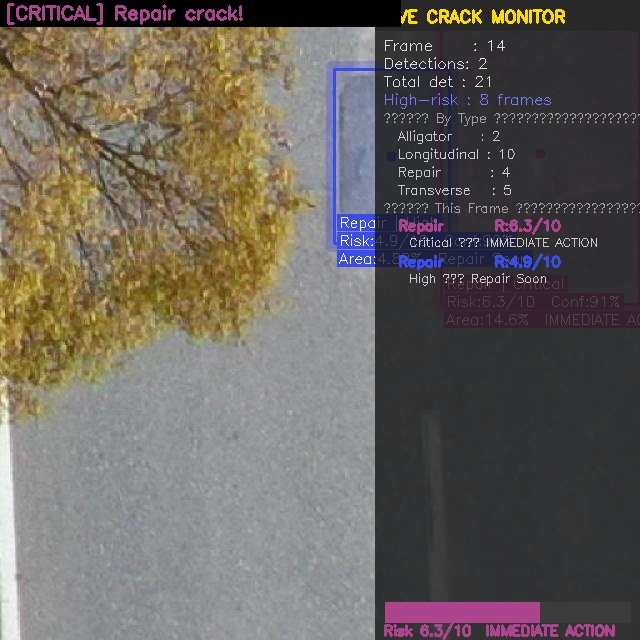

Frame 014 | 2 crack(s)  → Repair [Critical] R:6.3/10  → Repair [High] R:4.9/10


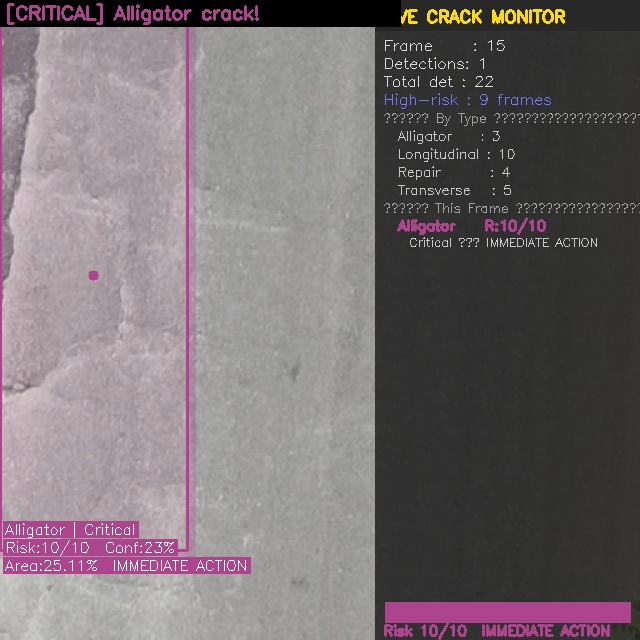

Frame 015 | 1 crack(s)  → Alligator [Critical] R:10/10


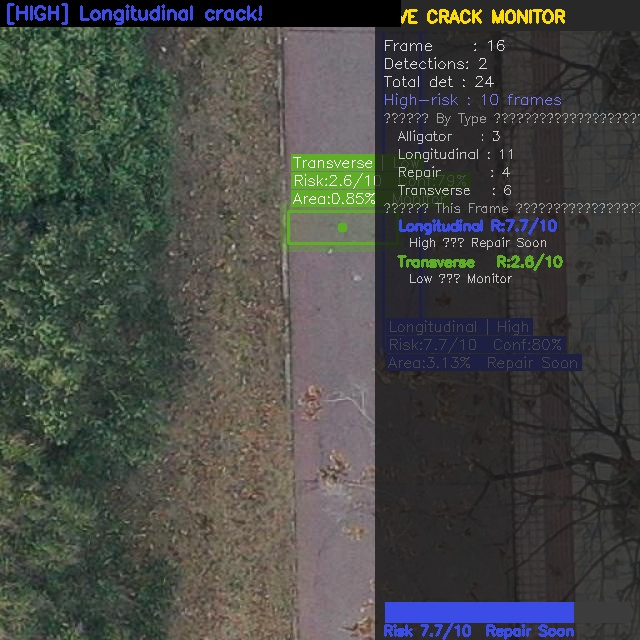

Frame 016 | 2 crack(s)  → Longitudinal [High] R:7.7/10  → Transverse [Low] R:2.6/10


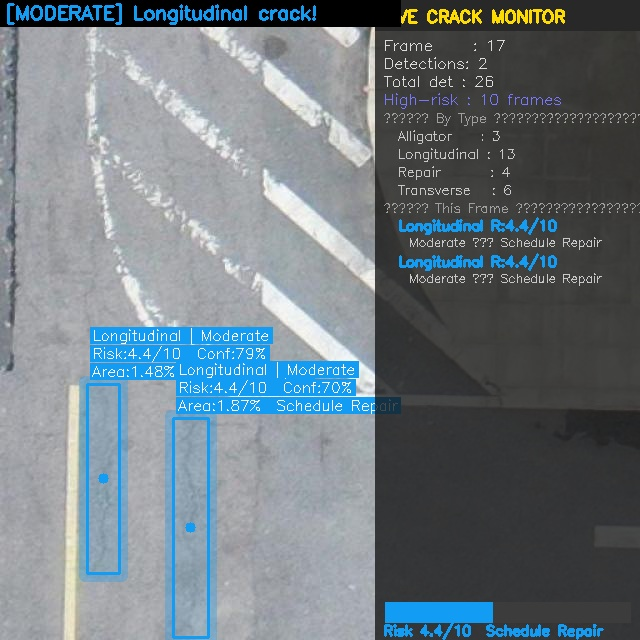

Frame 017 | 2 crack(s)  → Longitudinal [Moderate] R:4.4/10  → Longitudinal [Moderate] R:4.4/10


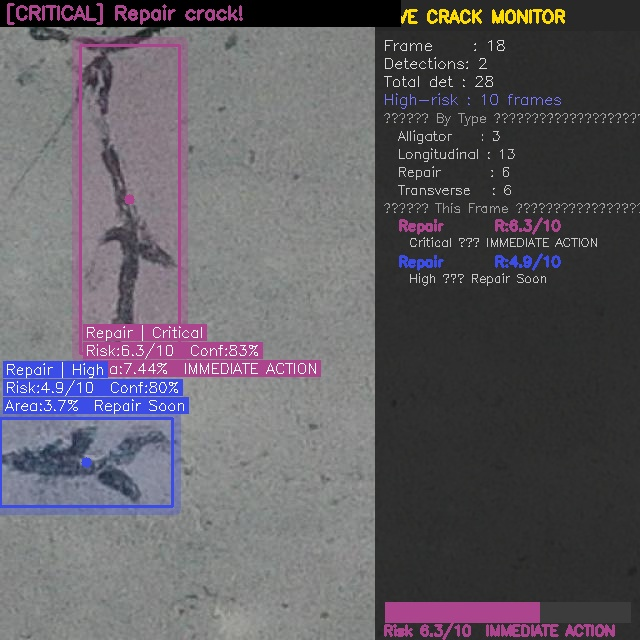

Frame 018 | 2 crack(s)  → Repair [Critical] R:6.3/10  → Repair [High] R:4.9/10


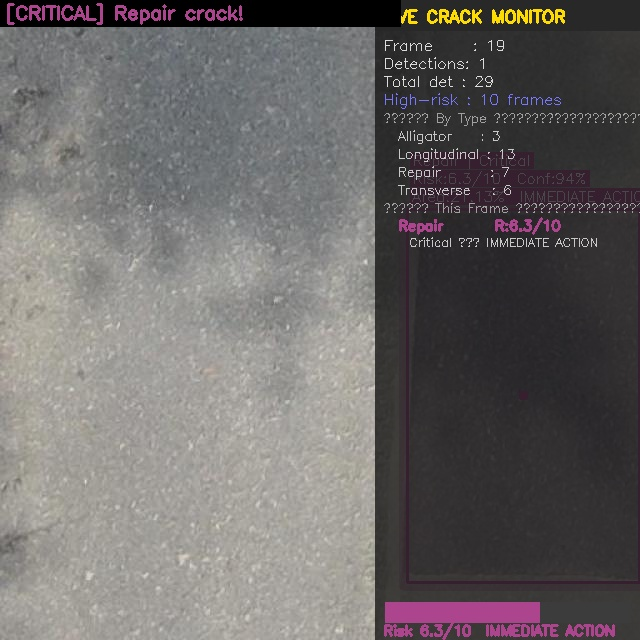

Frame 019 | 1 crack(s)  → Repair [Critical] R:6.3/10


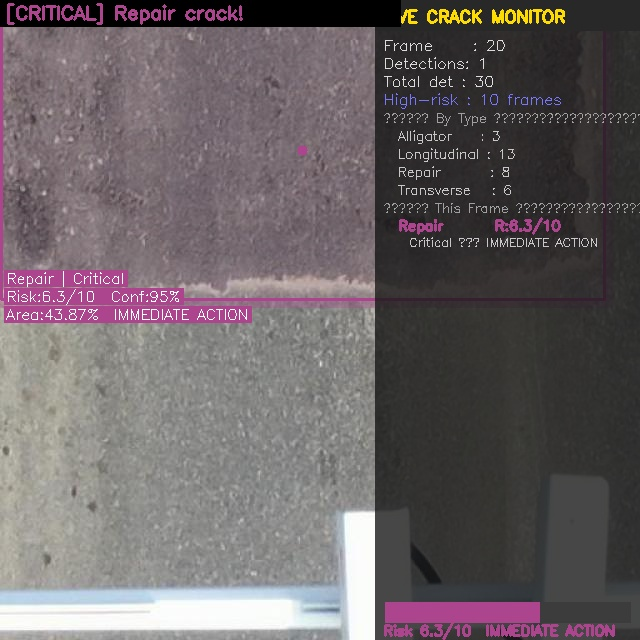

Frame 020 | 1 crack(s)  → Repair [Critical] R:6.3/10

✅  Video saved → /kaggle/working/simulated_drive.mp4

══════════════════════════════════════════════════
  SESSION SUMMARY
══════════════════════════════════════════════════
  Frames processed : 20
  Total detections : 30
  High-risk frames : 10

  Detections by type:
    Alligator      :   3  ███
    Longitudinal   :  13  █████████████
    Repair         :   8  ████████
    Transverse     :   6  ██████

  Avg risk score   : 6.0/10
  Max risk score   : 10.0/10


In [14]:
from ultralytics import YOLO
import cv2
import numpy as np
import time
from pathlib import Path
from collections import deque
from IPython.display import display, Image as IPImage
import io

# ── Config ────────────────────────────────────────────────────────────────────
MODEL_PATH  = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
CLASS_NAMES = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']
CONF        = 0.18

# ▼ Pick ONE source:
# Option A – test images (works always on Kaggle)
SOURCE_IMAGES = list(Path('/kaggle/working/crack_4class/test/images').glob('*.jpg'))

# Option B – uploaded road video (upload a .mp4 to Kaggle first)
# SOURCE_VIDEO = '/kaggle/input/your-dataset/road_video.mp4'

USE_VIDEO = False   # set True if you have a video file

TYPE_WEIGHTS = {'Alligator': 1.5, 'Transverse': 1.3, 'Longitudinal': 1.1, 'Repair': 0.7}
COLORS = {
    'Low':      (39, 174, 96),
    'Moderate': (243, 156, 18),
    'High':     (231, 76, 60),
    'Critical': (142, 68, 173),
}
ACTIONS = {
    'Low':      'Monitor',
    'Moderate': 'Schedule Repair',
    'High':     'Repair Soon',
    'Critical': 'IMMEDIATE ACTION',
}

# ── Severity ──────────────────────────────────────────────────────────────────
def get_severity(area_pct, crack_type):
    if   area_pct < 1.0: base, level = 2, 'Low'
    elif area_pct < 3.0: base, level = 4, 'Moderate'
    elif area_pct < 6.0: base, level = 7, 'High'
    else:                base, level = 9, 'Critical'
    risk = min(10, round(base * TYPE_WEIGHTS.get(crack_type, 1.0), 1))
    return level, COLORS[level], risk

# ── Stats tracker ─────────────────────────────────────────────────────────────
class CrackTracker:
    def __init__(self):
        self.total_det        = 0
        self.frame_no         = 0
        self.high_risk_frames = 0
        self.per_type         = {c: 0 for c in CLASS_NAMES}
        self.risk_log         = []          # (frame, risk) for every detection

    def update(self, detections, frame_no):
        self.frame_no = frame_no
        self.total_det += len(detections)
        for d in detections:
            self.per_type[d['crack_type']] += 1
            self.risk_log.append((frame_no, d['risk']))
        if any(d['risk'] >= 7 for d in detections):
            self.high_risk_frames += 1

# ── Draw helpers ──────────────────────────────────────────────────────────────
def draw_box(frame, d):
    x1,y1,x2,y2 = d['x1'],d['y1'],d['x2'],d['y2']
    color = d['color']
    # Glow
    ov = frame.copy()
    cv2.rectangle(ov, (x1-4,y1-4),(x2+4,y2+4), color, 7)
    cv2.addWeighted(ov, 0.3, frame, 0.7, 0, frame)
    # Box + fill
    ov2 = frame.copy()
    cv2.rectangle(ov2,(x1,y1),(x2,y2),color,-1)
    cv2.addWeighted(ov2, 0.12, frame, 0.88, 0, frame)
    cv2.rectangle(frame,(x1,y1),(x2,y2),color,2)
    # Center dot
    cv2.circle(frame,((x1+x2)//2,(y1+y2)//2),5,color,-1)
    # Label
    lines = [f"{d['crack_type']} | {d['severity']}",
             f"Risk:{d['risk']}/10  Conf:{d['conf']:.0%}",
             f"Area:{d['area_pct']}%  {ACTIONS[d['severity']]}"]
    lx = x1+5
    ly = y1-8 if y1 > 70 else y2+20
    for i, txt in enumerate(lines):
        (tw,th),_ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.48, 1)
        yy = ly - (len(lines)-1-i)*18
        cv2.rectangle(frame,(lx-2,yy-th-2),(lx+tw+2,yy+3),color,-1)
        cv2.putText(frame,txt,(lx,yy),cv2.FONT_HERSHEY_SIMPLEX,0.48,(255,255,255),1)

def draw_dashboard(frame, tracker, detections, frame_no):
    H,W = frame.shape[:2]
    pw = 265
    # Panel background
    ov = frame.copy()
    cv2.rectangle(ov,(W-pw,0),(W,H),(20,20,20),-1)
    cv2.addWeighted(ov,0.78,frame,0.22,0,frame)
    cv2.rectangle(frame,(W-pw,0),(W,30),(40,40,40),-1)

    def put(txt, y, col=(220,220,220), sc=0.50, bold=1):
        cv2.putText(frame,txt,(W-pw+8,y),cv2.FONT_HERSHEY_SIMPLEX,sc,col,bold)

    put("LIVE CRACK MONITOR", 22,(0,220,255),0.55,2)
    put(f"Frame     : {frame_no}", 50)
    put(f"Detections: {len(detections)}", 68)
    put(f"Total det : {tracker.total_det}", 86)
    put(f"High-risk : {tracker.high_risk_frames} frames",104,(255,120,120))
    put("── By Type ──────────",122,(160,160,160),0.42)
    for i,(ct,cnt) in enumerate(tracker.per_type.items()):
        put(f"  {ct:<13}: {cnt}",140+i*18,(200,200,200),0.44)
    put("── This Frame ───────",212,(160,160,160),0.42)

    if detections:
        for i,d in enumerate(detections[:4]):
            put(f"  {d['crack_type']:<12} R:{d['risk']}/10",
                230+i*36, d['color'],0.46,2)
            put(f"    {d['severity']} → {ACTIONS[d['severity']]}",
                230+i*36+16,(200,200,200),0.40)
        # Risk bar
        worst = max(detections, key=lambda d: d['risk'])
        fill  = int(worst['risk']/10*(pw-20))
        cv2.rectangle(frame,(W-pw+10,H-38),(W-10,H-18),(60,60,60),-1)
        cv2.rectangle(frame,(W-pw+10,H-38),(W-pw+10+fill,H-18),worst['color'],-1)
        put(f"Risk {worst['risk']}/10  {ACTIONS[worst['severity']]}",H-5,worst['color'],0.46,2)
        # Top-left alert
        alert_col = worst['color']
        alert_txt = f"[{worst['severity'].upper()}] {worst['crack_type']} crack!"
    else:
        put("  Road clear",230,(100,255,100),0.5)
        alert_col = (100,255,100)
        alert_txt = "[CLEAR] No cracks"

    cv2.rectangle(frame,(0,0),(400,26),(0,0,0),-1)
    cv2.putText(frame,alert_txt,(6,19),cv2.FONT_HERSHEY_SIMPLEX,0.62,alert_col,2)

# ── Simulate real-time from images ────────────────────────────────────────────
def run_on_images(image_paths, delay_ms=400):
    """Simulates a driving feed frame-by-frame from test images."""
    model   = YOLO(MODEL_PATH)
    tracker = CrackTracker()

    out_dir = Path('/kaggle/working/live_frames'); out_dir.mkdir(exist_ok=True)
    saved   = []

    print(f"▶  Simulating live feed on {len(image_paths)} frames...\n")

    for frame_no, img_path in enumerate(image_paths, 1):
        frame = cv2.imread(str(img_path))
        if frame is None: continue

        h, w    = frame.shape[:2]
        results = model(frame, conf=CONF, verbose=False)
        detections = []

        if results[0].boxes:
            for box in results[0].boxes:
                x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
                crack_type   = CLASS_NAMES[int(box.cls[0])]
                conf_score   = float(box.conf[0])
                area_pct     = round(((x2-x1)*(y2-y1))/(h*w)*100, 2)
                severity,color,risk = get_severity(area_pct, crack_type)
                det = dict(x1=x1,y1=y1,x2=x2,y2=y2,
                           crack_type=crack_type,conf=conf_score,
                           area_pct=area_pct,severity=severity,color=color,risk=risk)
                detections.append(det)
                draw_box(frame, det)

        tracker.update(detections, frame_no)
        draw_dashboard(frame, tracker, detections, frame_no)

        # Save frame
        out_path = out_dir / f"frame_{frame_no:04d}.jpg"
        cv2.imwrite(str(out_path), frame)
        saved.append(out_path)

        # Show inline in Kaggle notebook
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        _, buf = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
        display(IPImage(data=buf.tobytes()))

        # Console log
        print(f"Frame {frame_no:03d} | {len(detections)} crack(s)", end="")
        for d in detections:
            print(f"  → {d['crack_type']} [{d['severity']}] R:{d['risk']}/10", end="")
        print()

        time.sleep(delay_ms / 1000)   # simulate frame rate

    return tracker, saved

# ── Run from images → then compile video ─────────────────────────────────────
import random; random.seed(42)
frames_to_use = random.sample(SOURCE_IMAGES, min(20, len(SOURCE_IMAGES)))  # 20 frames

tracker, saved_frames = run_on_images(frames_to_use, delay_ms=300)

# Compile all annotated frames into one video
if saved_frames:
    sample = cv2.imread(str(saved_frames[0]))
    H, W   = sample.shape[:2]
    writer = cv2.VideoWriter('/kaggle/working/simulated_drive.mp4',
                              cv2.VideoWriter_fourcc(*'mp4v'), 5, (W, H))
    for fp in saved_frames:
        writer.write(cv2.imread(str(fp)))
    writer.release()
    print("  Video saved → /kaggle/working/simulated_drive.mp4")

# ── Final stats ───────────────────────────────────────────────────────────────
print(f"\n{'═'*50}")
print(f"  SESSION SUMMARY")
print(f"{'═'*50}")
print(f"  Frames processed : {tracker.frame_no}")
print(f"  Total detections : {tracker.total_det}")
print(f"  High-risk frames : {tracker.high_risk_frames}")
print(f"\n  Detections by type:")
for ct, cnt in tracker.per_type.items():
    bar = '' * cnt
    print(f"    {ct:<15}: {cnt:3d}  {bar}")
if tracker.risk_log:
    risks = [r for _, r in tracker.risk_log]
    print(f"\n  Avg risk score   : {np.mean(risks):.1f}/10")
    print(f"  Max risk score   : {max(risks):.1f}/10")

# Real asphalt/road crack images (public domain


  ❌  alligator_asphalt.jpg — HTTP 400, skipping
  ❌  longitudinal_road.jpg — HTTP 400, skipping
  ❌  pothole_road.jpg — HTTP 400, skipping
  ❌  cracked_surface.jpg — HTTP 400, skipping
  ❌  unsplash_crack1.jpg — HTTP 404, skipping
  ✅  unsplash_road.jpg

⚠️  Too few web images downloaded — falling back to your test set
  Using 6 test images instead

✅  6 images ready for prediction
═══════════════════════════════════════════════════════


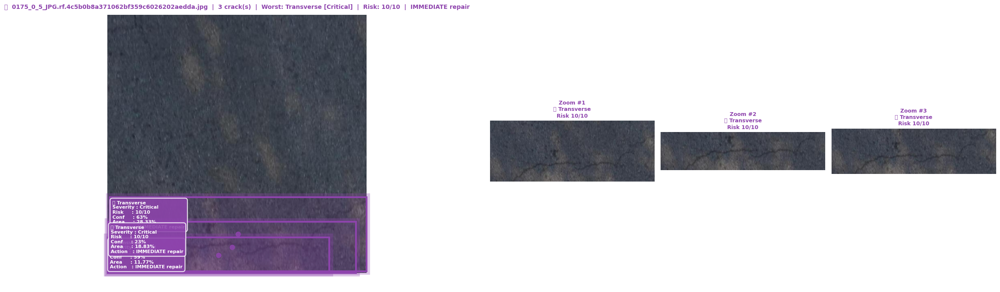


═══════════════════════════════════════════════════════
  📸 0175_0_5_JPG.rf.4c5b0b8a371062bf359c6026202aedda.jpg  |  3 crack(s)
───────────────────────────────────────────────────────
  1. 🟣 Transverse    | Conf:63% | Area:28.33% | Risk:  10/10 | Critical
     → IMMEDIATE repair
  2. 🟣 Transverse    | Conf:59% | Area:11.77% | Risk:  10/10 | Critical
     → IMMEDIATE repair
  3. 🟣 Transverse    | Conf:23% | Area:18.83% | Risk:  10/10 | Critical
     → IMMEDIATE repair


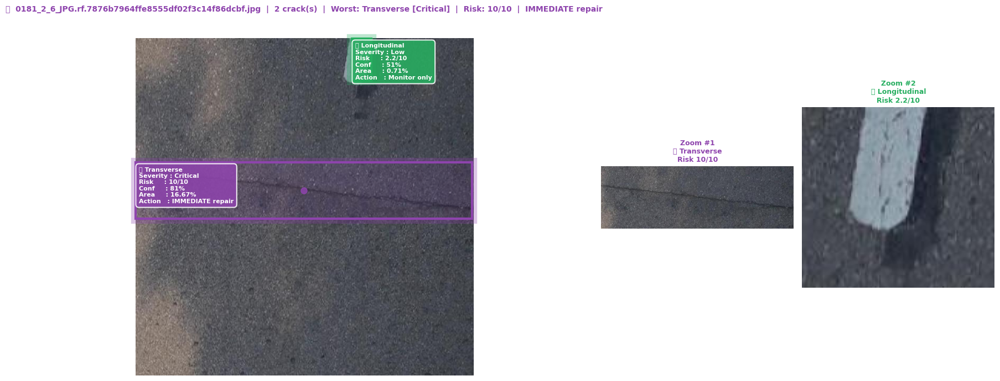


═══════════════════════════════════════════════════════
  📸 0181_2_6_JPG.rf.7876b7964ffe8555df02f3c14f86dcbf.jpg  |  2 crack(s)
───────────────────────────────────────────────────────
  1. 🟣 Transverse    | Conf:81% | Area:16.67% | Risk:  10/10 | Critical
     → IMMEDIATE repair
  2. 🟢 Longitudinal  | Conf:51% | Area: 0.71% | Risk: 2.2/10 | Low
     → Monitor only


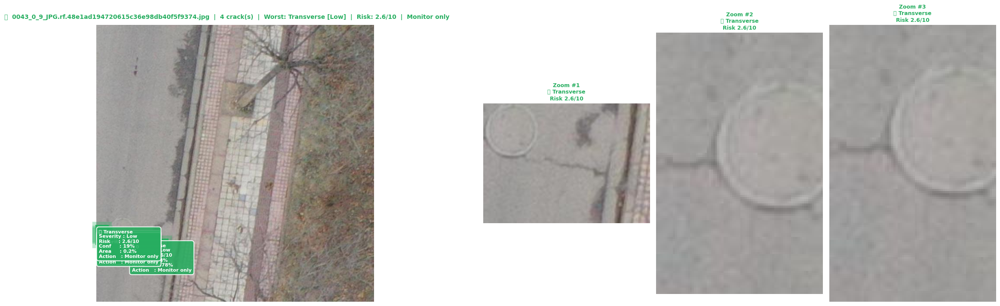


═══════════════════════════════════════════════════════
  📸 0043_0_9_JPG.rf.48e1ad194720615c36e98db40f5f9374.jpg  |  4 crack(s)
───────────────────────────────────────────────────────
  1. 🟢 Transverse    | Conf:68% | Area: 0.78% | Risk: 2.6/10 | Low
     → Monitor only
  2. 🟢 Transverse    | Conf:36% | Area: 0.17% | Risk: 2.6/10 | Low
     → Monitor only
  3. 🟢 Transverse    | Conf:27% | Area: 0.21% | Risk: 2.6/10 | Low
     → Monitor only
  4. 🟢 Transverse    | Conf:19% | Area:  0.2% | Risk: 2.6/10 | Low
     → Monitor only


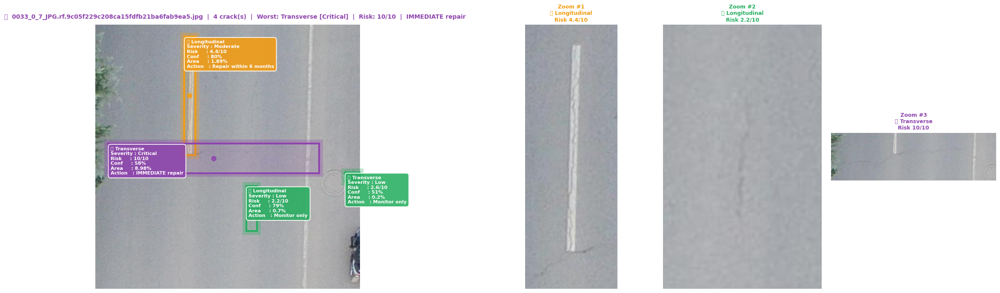


═══════════════════════════════════════════════════════
  📸 0033_0_7_JPG.rf.9c05f229c208ca15fdfb21ba6fab9ea5.jpg  |  4 crack(s)
───────────────────────────────────────────────────────
  1. 🟡 Longitudinal  | Conf:80% | Area: 1.89% | Risk: 4.4/10 | Moderate
     → Repair within 6 months
  2. 🟢 Longitudinal  | Conf:79% | Area:  0.7% | Risk: 2.2/10 | Low
     → Monitor only
  3. 🟣 Transverse    | Conf:58% | Area: 8.98% | Risk:  10/10 | Critical
     → IMMEDIATE repair
  4. 🟢 Transverse    | Conf:51% | Area:  0.2% | Risk: 2.6/10 | Low
     → Monitor only


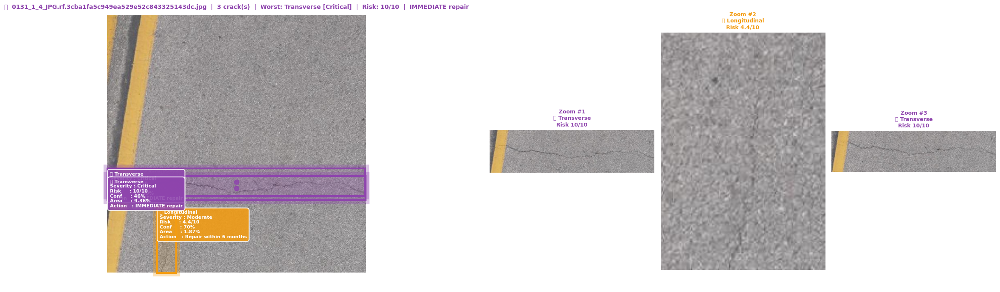


═══════════════════════════════════════════════════════
  📸 0131_1_4_JPG.rf.3cba1fa5c949ea529e52c843325143dc.jpg  |  3 crack(s)
───────────────────────────────────────────────────────
  1. 🟣 Transverse    | Conf:79% | Area:10.59% | Risk:  10/10 | Critical
     → IMMEDIATE repair
  2. 🟡 Longitudinal  | Conf:70% | Area: 1.87% | Risk: 4.4/10 | Moderate
     → Repair within 6 months
  3. 🟣 Transverse    | Conf:46% | Area: 9.36% | Risk:  10/10 | Critical
     → IMMEDIATE repair


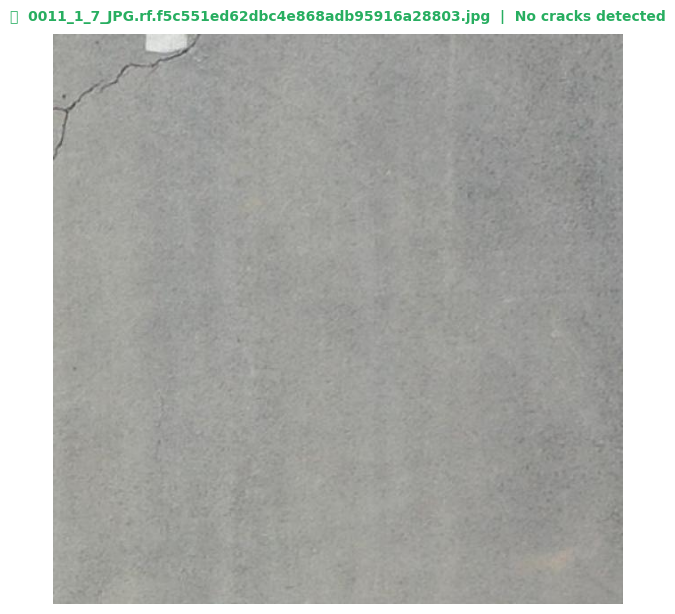


═══════════════════════════════════════════════════════
  📸 0011_1_7_JPG.rf.f5c551ed62dbc4e868adb95916a28803.jpg  |  0 crack(s)
───────────────────────────────────────────────────────
  ✅ No cracks detected

✅  All results saved to /kaggle/working/real_road_results


In [15]:

from ultralytics import YOLO
import cv2
import numpy as np
import requests
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

# ── Config ────────────────────────────────────────────────────────────────────
MODEL_PATH  = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
CLASS_NAMES = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']
CONF        = 0.18
SAVE_DIR    = Path('/kaggle/working/real_road_results'); SAVE_DIR.mkdir(exist_ok=True)

# ── Real asphalt/road crack images (public domain, no login) ──────────────────
ROAD_IMAGES = [
    ("https://upload.wikimedia.org/wikipedia/commons/thumb/f/f7/Cracked_asphalt.jpg/640px-Cracked_asphalt.jpg",  "alligator_asphalt.jpg"),
    ("https://upload.wikimedia.org/wikipedia/commons/thumb/1/1c/Road_surface_crack.jpg/640px-Road_surface_crack.jpg", "longitudinal_road.jpg"),
    ("https://upload.wikimedia.org/wikipedia/commons/thumb/e/e3/Pothole_road.jpg/640px-Pothole_road.jpg",         "pothole_road.jpg"),
    ("https://upload.wikimedia.org/wikipedia/commons/thumb/5/58/Cracked_road_surface.jpg/640px-Cracked_road_surface.jpg", "cracked_surface.jpg"),
    ("https://images.unsplash.com/photo-1515162305285-0293e4f4b6b6?w=640",                                        "unsplash_crack1.jpg"),
    ("https://images.unsplash.com/photo-1558618666-fcd25c85cd64?w=640",                                           "unsplash_road.jpg"),
]

# ── Download images ───────────────────────────────────────────────────────────
img_dir = Path('/kaggle/working/real_road_images'); img_dir.mkdir(exist_ok=True)
downloaded = []

print("Downloading real road images...\n")
headers = {'User-Agent': 'Mozilla/5.0'}

for url, fname in ROAD_IMAGES:
    save_path = img_dir / fname
    try:
        r = requests.get(url, headers=headers, timeout=15)
        if r.status_code == 200 and len(r.content) > 5000:
            save_path.write_bytes(r.content)
            # Verify it's a valid image
            img_test = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
            if img_test is not None:
                downloaded.append(save_path)
                print(f"  {fname}")
            else:
                print(f"    {fname} — not a valid image, skipping")
        else:
            print(f"    {fname} — HTTP {r.status_code}, skipping")
    except Exception as e:
        print(f"    {fname} — {e}")

# Fallback: if too few downloaded, use test images
if len(downloaded) < 2:
    print("  Too few web images downloaded — falling back to your test set")
    downloaded = list(Path('/kaggle/working/crack_4class/test/images').glob('*.jpg'))[:6]
    print(f"  Using {len(downloaded)} test images instead")

print(f"\n  {len(downloaded)} images ready for prediction\n{'═'*55}")

# ── Severity & risk ───────────────────────────────────────────────────────────
TYPE_WEIGHTS = {'Alligator': 1.5, 'Transverse': 1.3, 'Longitudinal': 1.1, 'Repair': 0.7}
SEVERITY_CFG = {
    'Low':      {'color': '#27ae60', 'emoji': '🟢', 'base': 2, 'action': 'Monitor only'},
    'Moderate': {'color': '#f39c12', 'emoji': '🟡', 'base': 4, 'action': 'Repair within 6 months'},
    'High':     {'color': '#e74c3c', 'emoji': '🔴', 'base': 7, 'action': 'Repair within 1 month'},
    'Critical': {'color': '#8e44ad', 'emoji': '🟣', 'base': 9, 'action': 'IMMEDIATE repair'},
}

def get_severity(area_pct, crack_type):
    if   area_pct < 1.0: level = 'Low'
    elif area_pct < 3.0: level = 'Moderate'
    elif area_pct < 6.0: level = 'High'
    else:                level = 'Critical'
    cfg  = SEVERITY_CFG[level]
    risk = min(10, round(cfg['base'] * TYPE_WEIGHTS.get(crack_type, 1.0), 1))
    return level, cfg['color'], cfg['emoji'], risk, cfg['action']

# ── Prediction & display ──────────────────────────────────────────────────────
model = YOLO(MODEL_PATH)

for img_path in downloaded:
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None: continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w    = img_rgb.shape[:2]

    results    = model(img_path, conf=CONF, verbose=False)
    detections = []

    if results[0].boxes:
        for box in results[0].boxes:
            x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
            crack_type   = CLASS_NAMES[int(box.cls[0])]
            conf_score   = float(box.conf[0])
            area_pct     = round(((x2-x1)*(y2-y1))/(h*w)*100, 2)
            level,color,emoji,risk,action = get_severity(area_pct, crack_type)
            detections.append(dict(x1=x1,y1=y1,x2=x2,y2=y2,
                                   crack_type=crack_type, conf=conf_score,
                                   area_pct=area_pct, severity=level,
                                   color=color, emoji=emoji,
                                   risk=risk, action=action))

    # ── Layout: full image + zoomed crops ─────────────────────────────────────
    n_zooms = min(len(detections), 3)
    n_cols  = 1 + n_zooms
    fig, axes = plt.subplots(1, n_cols,
                              figsize=(6*n_cols, 7),
                              gridspec_kw={'width_ratios': [3]+[1]*n_zooms})
    if n_cols == 1: axes = [axes]

    # Full image
    ax = axes[0]
    ax.imshow(img_rgb)

    for d in detections:
        x1,y1,x2,y2 = d['x1'],d['y1'],d['x2'],d['y2']
        c = d['color']
        # Glow ring
        ax.add_patch(patches.Rectangle((x1-5,y1-5),(x2-x1)+10,(y2-y1)+10,
                     linewidth=6, edgecolor=c, facecolor='none', alpha=0.3))
        # Fill
        ax.add_patch(patches.Rectangle((x1,y1),(x2-x1),(y2-y1),
                     linewidth=0, facecolor=c, alpha=0.13))
        # Border
        ax.add_patch(patches.Rectangle((x1,y1),(x2-x1),(y2-y1),
                     linewidth=3, edgecolor=c, facecolor='none'))
        # Center risk dot
        ax.plot((x1+x2)//2,(y1+y2)//2,'o',color=c,markersize=8,alpha=0.85)
        # Label
        label = (f"{d['emoji']} {d['crack_type']}\n"
                 f"Severity : {d['severity']}\n"
                 f"Risk     : {d['risk']}/10\n"
                 f"Conf     : {d['conf']:.0%}\n"
                 f"Area     : {d['area_pct']}%\n"
                 f"Action   : {d['action']}")
        ax.text(x1+6, y1+8, label,
                fontsize=8, color='white', fontweight='bold',
                verticalalignment='top',
                bbox=dict(boxstyle='round,pad=0.5', facecolor=c,
                          alpha=0.88, edgecolor='white', linewidth=1.5))

    # Title
    if detections:
        worst = max(detections, key=lambda d: d['risk'])
        title = (f"{worst['emoji']}  {img_path.name}  |  {len(detections)} crack(s)  |  "
                 f"Worst: {worst['crack_type']} [{worst['severity']}]  |  "
                 f"Risk: {worst['risk']}/10  |  {worst['action']}")
        t_col = worst['color']
    else:
        title = f"✅  {img_path.name}  |  No cracks detected"
        t_col = '#27ae60'

    ax.set_title(title, fontsize=10, fontweight='bold', color=t_col, pad=10)
    for spine in ax.spines.values():
        spine.set_edgecolor(t_col); spine.set_linewidth(5)
    ax.axis('off')

    # Zoomed crops
    for i, d in enumerate(detections[:n_zooms]):
        pad = 50
        x1c = max(0, d['x1']-pad); y1c = max(0, d['y1']-pad)
        x2c = min(w, d['x2']+pad); y2c = min(h, d['y2']+pad)
        crop = img_rgb[y1c:y2c, x1c:x2c]
        axes[i+1].imshow(crop)
        axes[i+1].set_title(
            f"Zoom #{i+1}\n{d['emoji']} {d['crack_type']}\nRisk {d['risk']}/10",
            fontsize=9, fontweight='bold', color=d['color'])
        for spine in axes[i+1].spines.values():
            spine.set_edgecolor(d['color']); spine.set_linewidth(3)
        axes[i+1].axis('off')

    plt.tight_layout()
    out = SAVE_DIR / f"result_{img_path.stem}.png"
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show(); plt.close()

    # Console summary
    print(f"\n{'═'*55}")
    print(f"  📸 {img_path.name}  |  {len(detections)} crack(s)")
    print(f"{'─'*55}")
    for i,d in enumerate(detections,1):
        print(f"  {i}. {d['emoji']} {d['crack_type']:<13} | Conf:{d['conf']:.0%} | "
              f"Area:{d['area_pct']:>5}% | Risk:{d['risk']:>4}/10 | {d['severity']}")
        print(f"     → {d['action']}")
    if not detections:
        print("  ✅ No cracks detected")

print(f"\n✅  All results saved to {SAVE_DIR}")

✅ 315 test images → visualizing 20


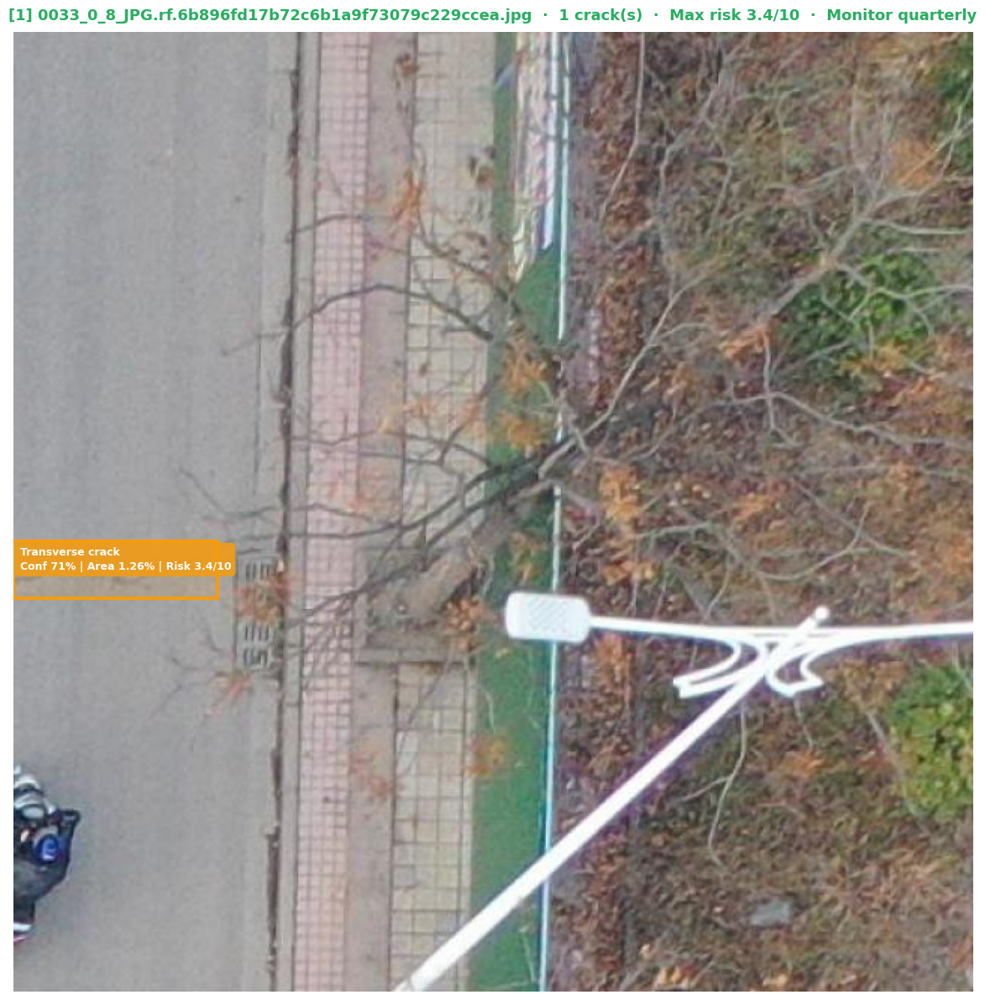

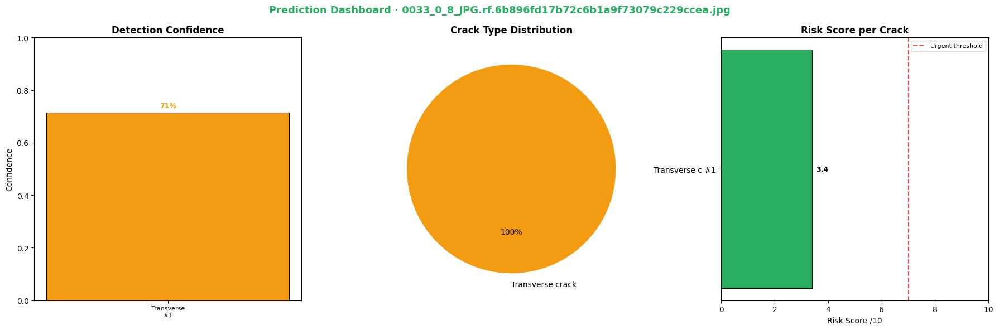

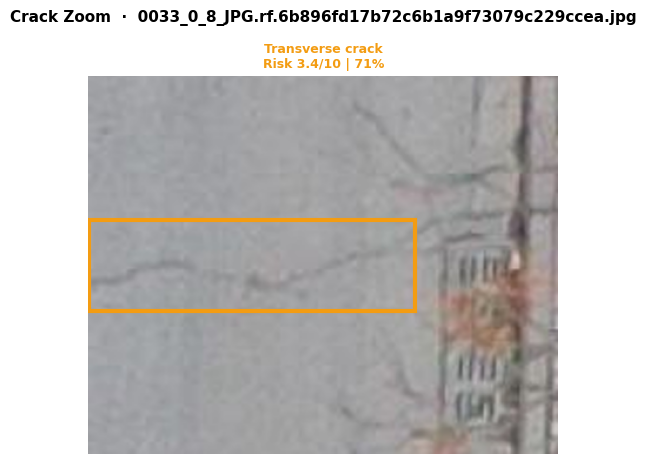

[1] 0033_0_8_JPG.rf.6b896fd17b72c6b1a9f73079c229ccea.jpg  |  1 crack(s)  |  Max risk 3.4/10  |  Monitor quarterly


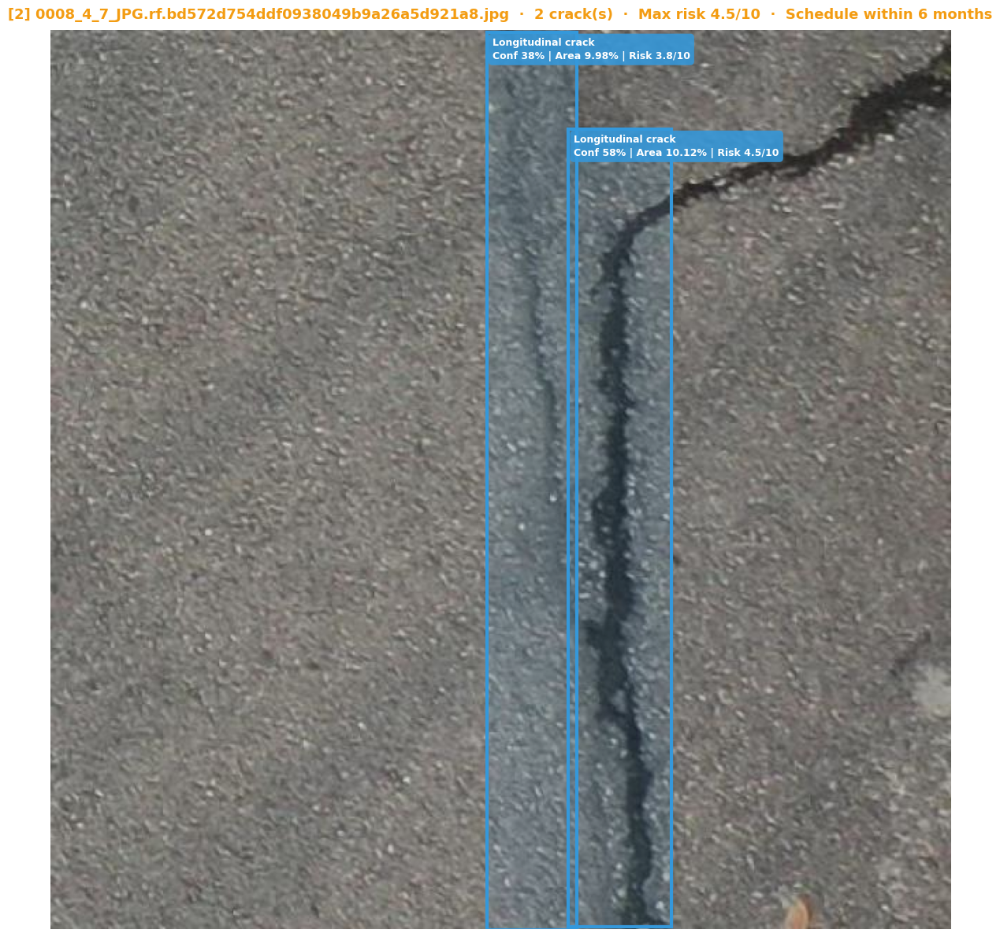

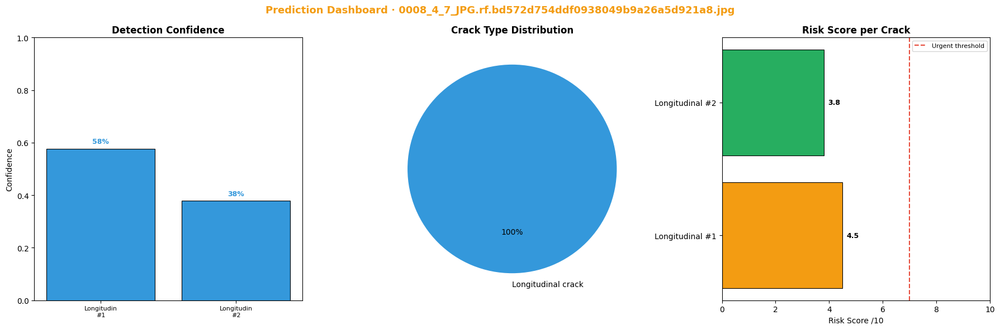

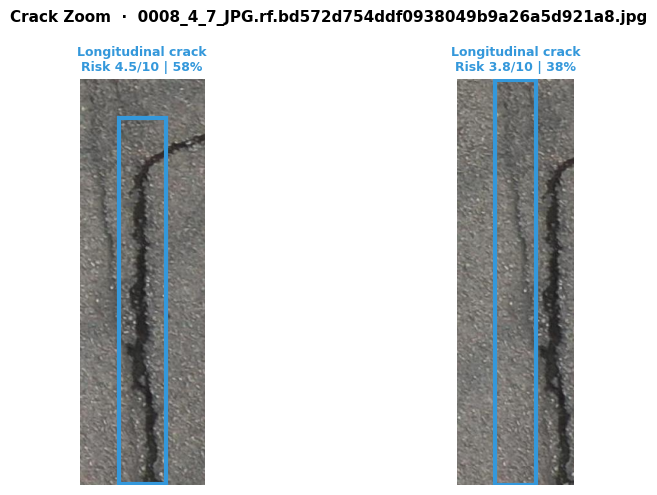

[2] 0008_4_7_JPG.rf.bd572d754ddf0938049b9a26a5d921a8.jpg  |  2 crack(s)  |  Max risk 4.5/10  |  Schedule within 6 months


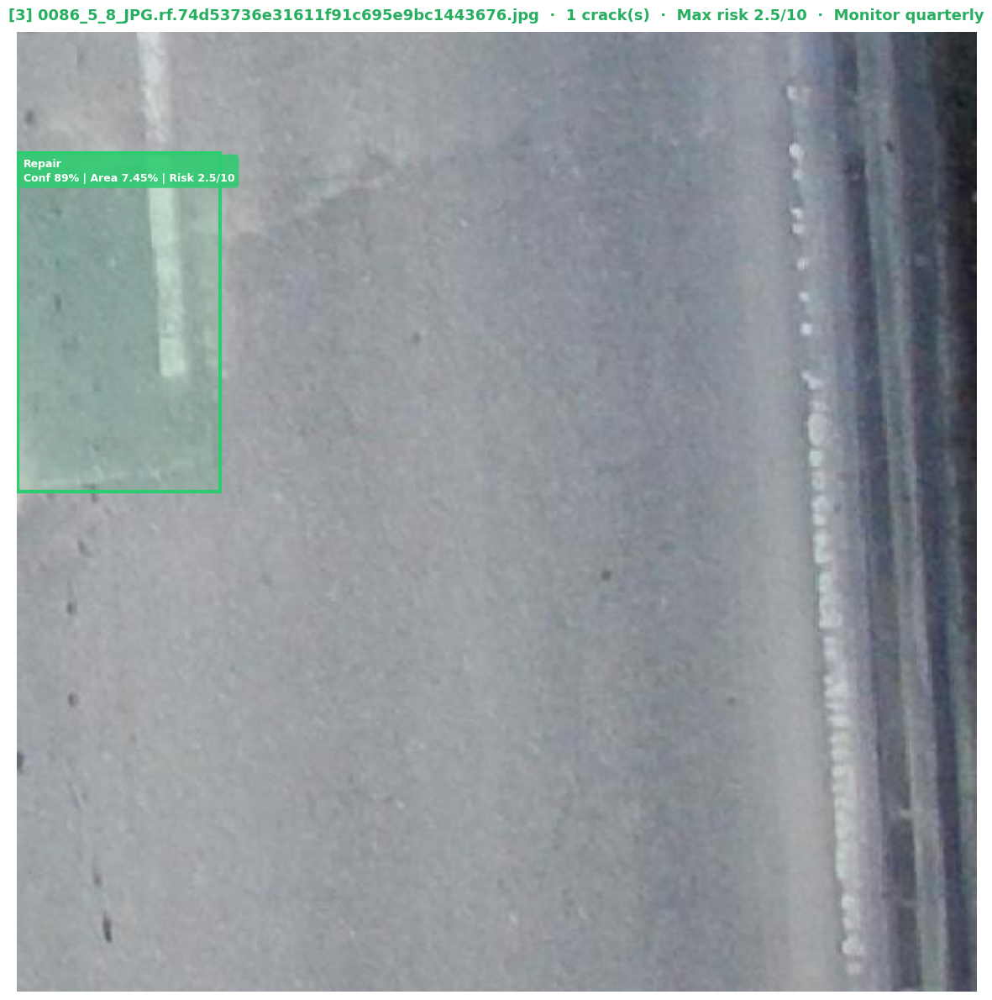

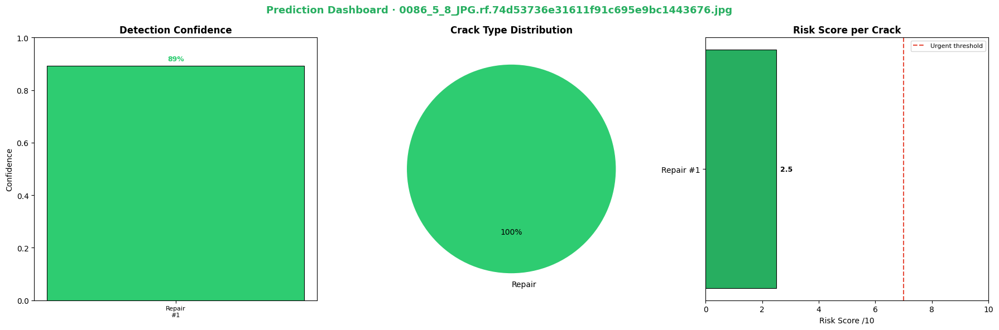

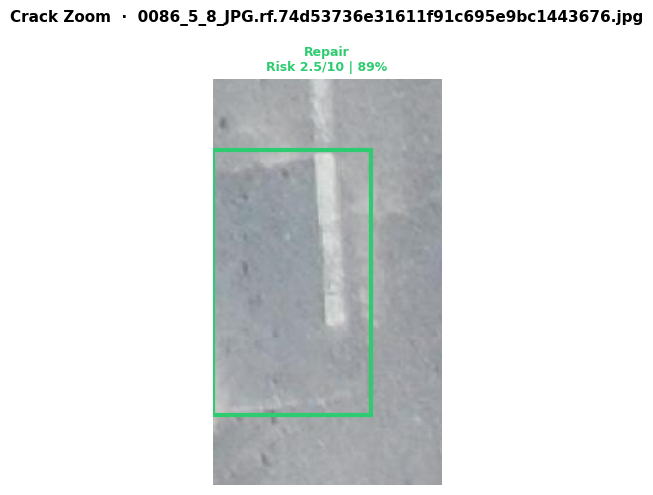

[3] 0086_5_8_JPG.rf.74d53736e31611f91c695e9bc1443676.jpg  |  1 crack(s)  |  Max risk 2.5/10  |  Monitor quarterly


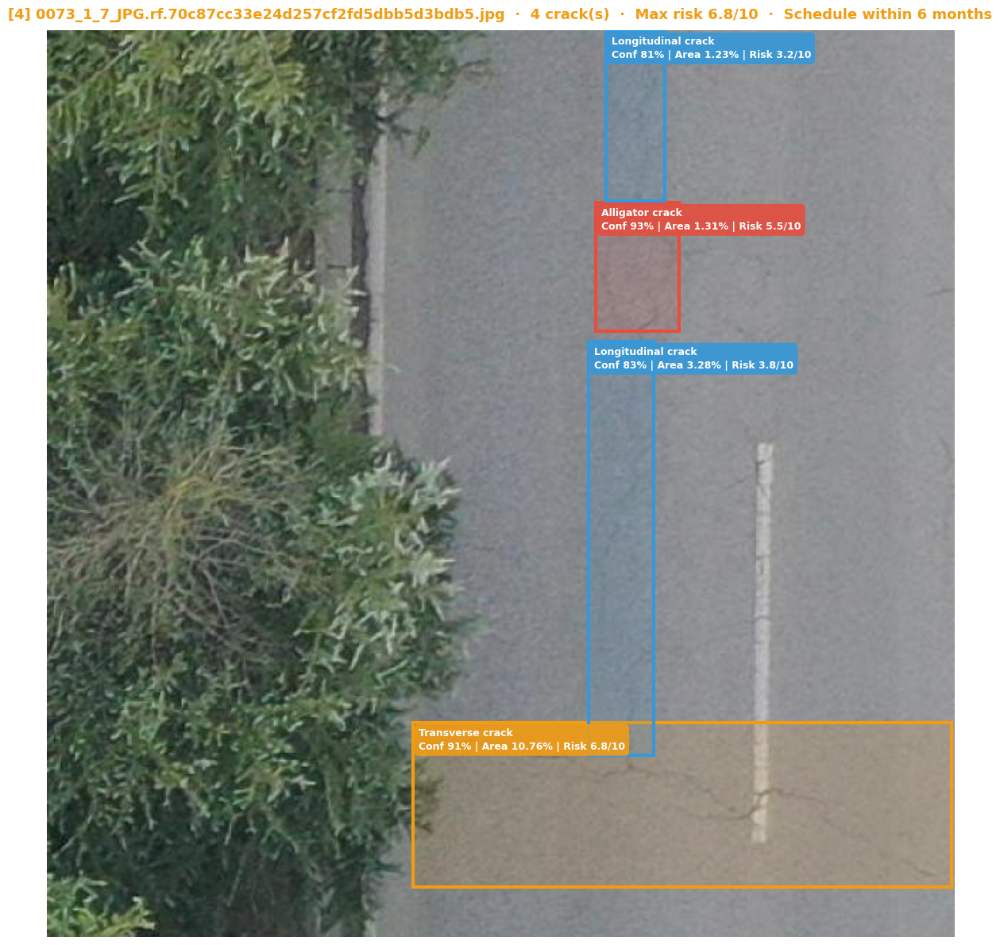

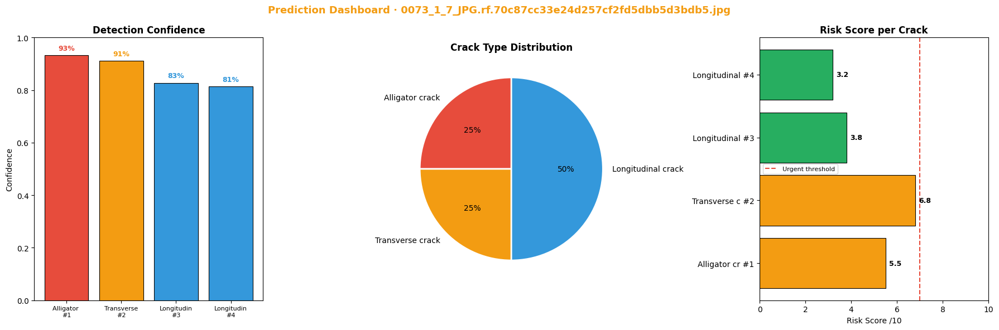

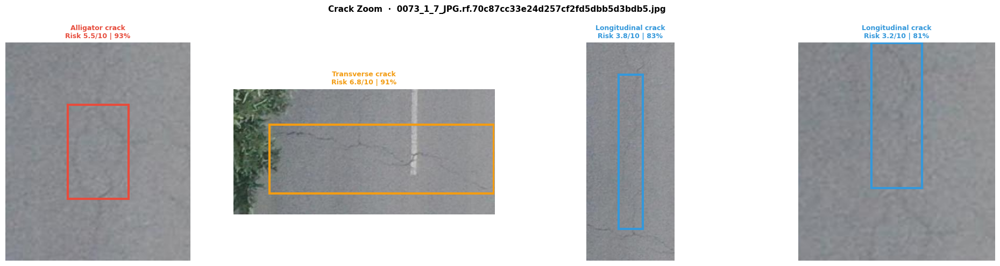

[4] 0073_1_7_JPG.rf.70c87cc33e24d257cf2fd5dbb5d3bdb5.jpg  |  4 crack(s)  |  Max risk 6.8/10  |  Schedule within 6 months


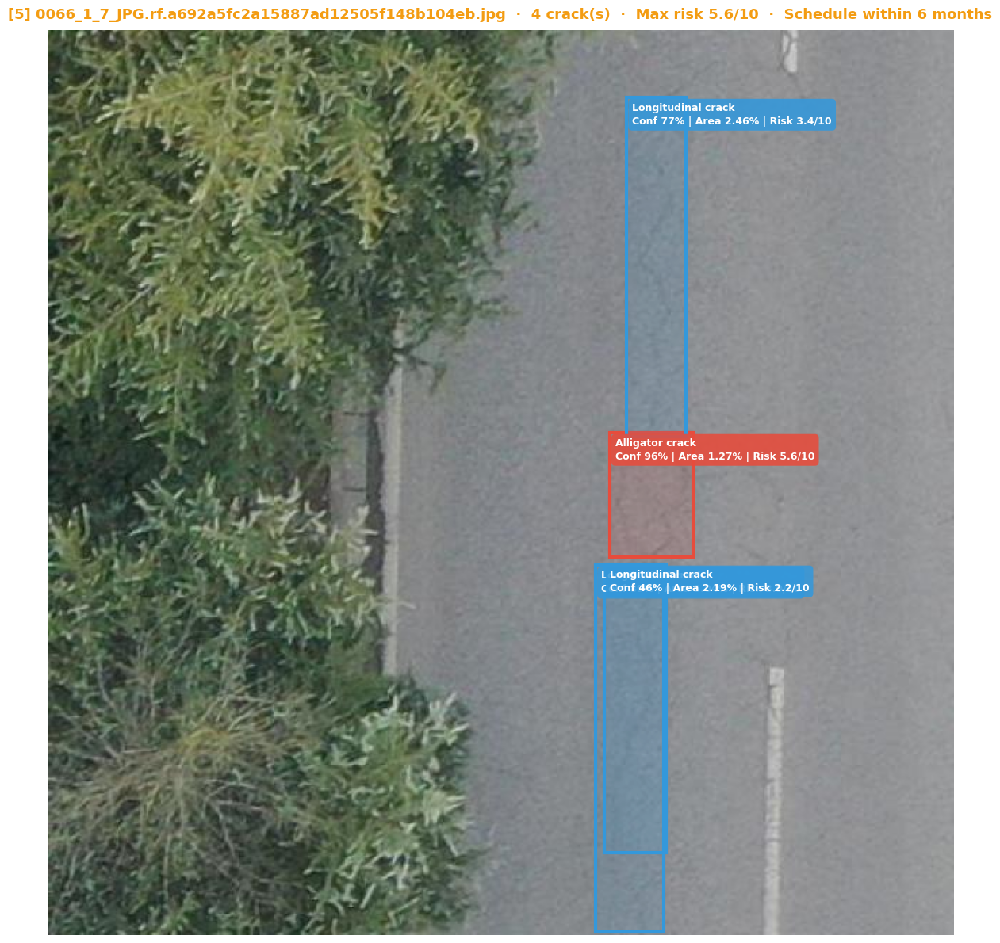

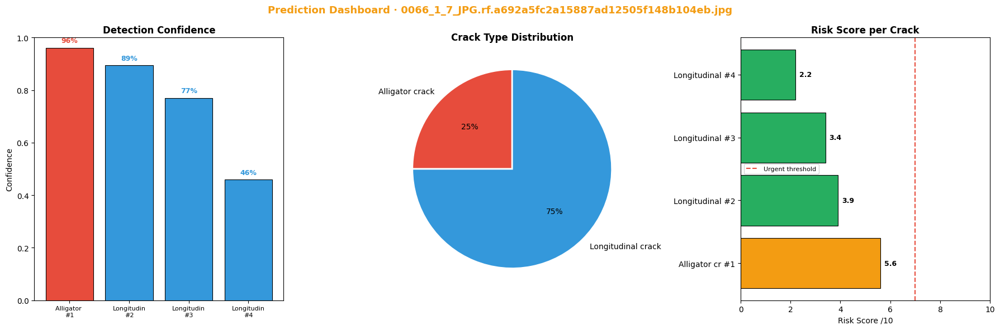

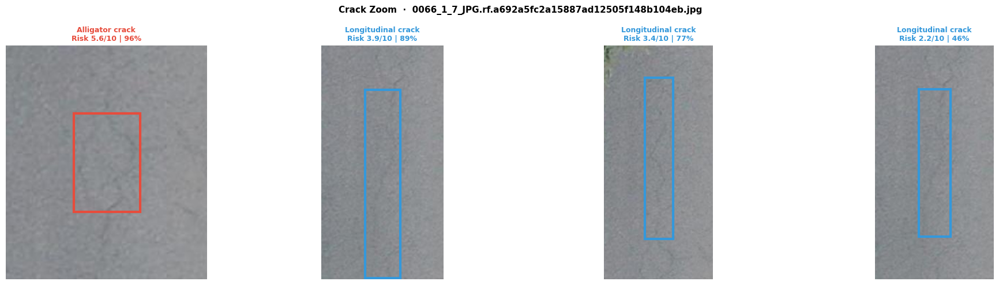

[5] 0066_1_7_JPG.rf.a692a5fc2a15887ad12505f148b104eb.jpg  |  4 crack(s)  |  Max risk 5.6/10  |  Schedule within 6 months


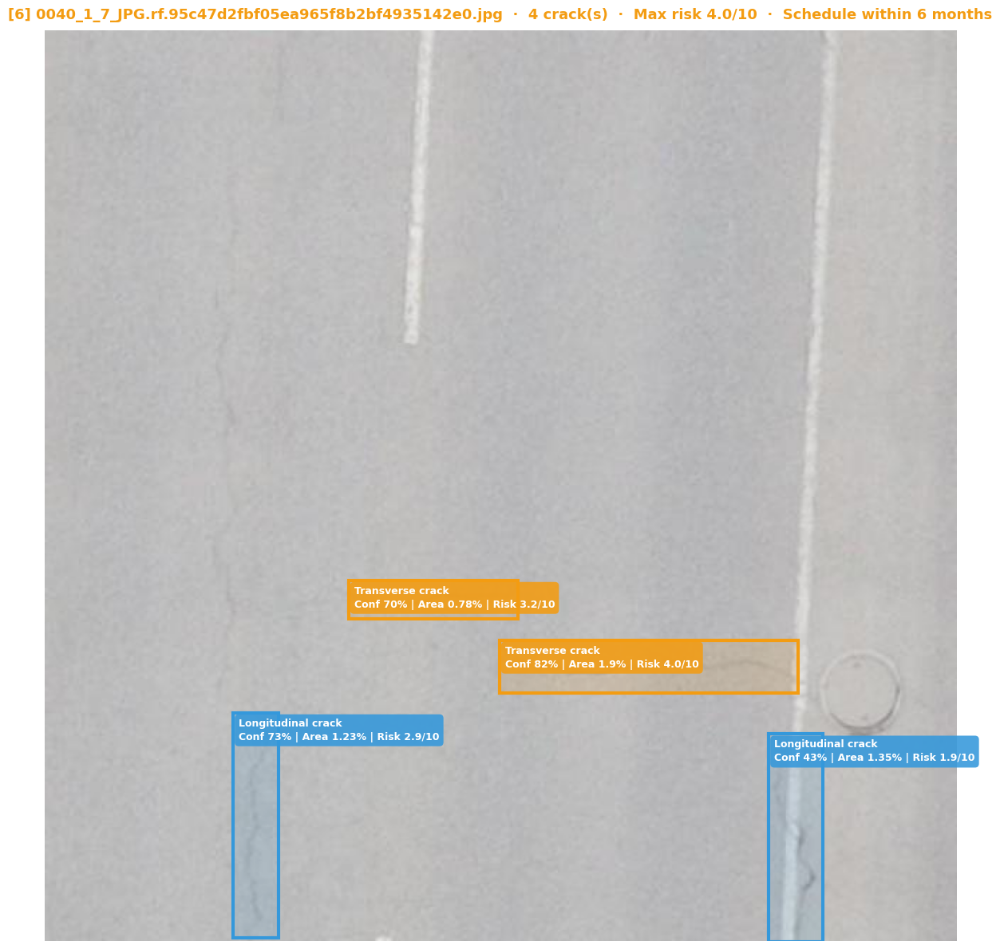

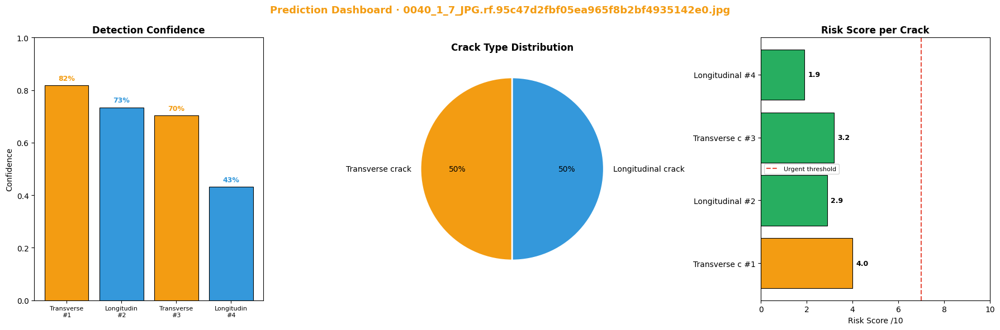

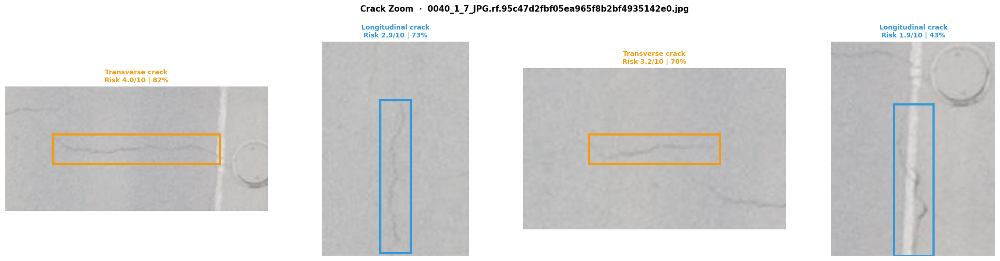

[6] 0040_1_7_JPG.rf.95c47d2fbf05ea965f8b2bf4935142e0.jpg  |  4 crack(s)  |  Max risk 4.0/10  |  Schedule within 6 months
  ⏭  [7] 0031_5_6_JPG.rf.fbd3c9fbdf264888dfcff8674b3f1ca0.jpg — no detections


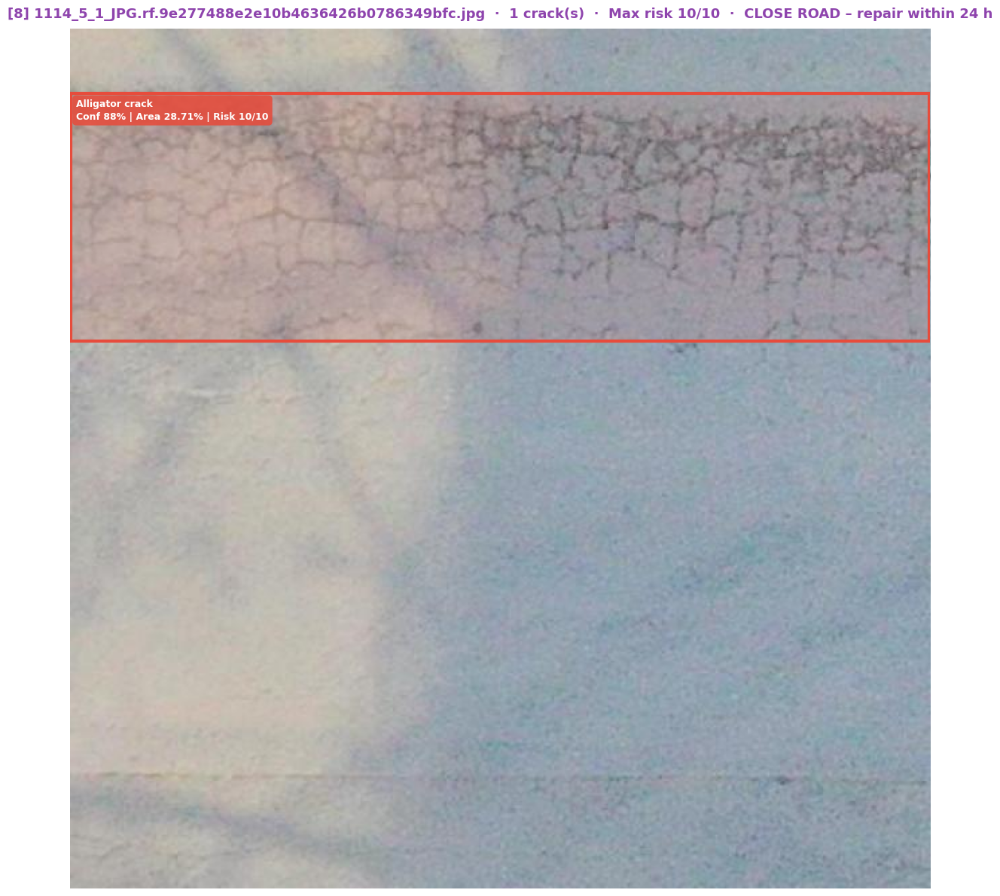

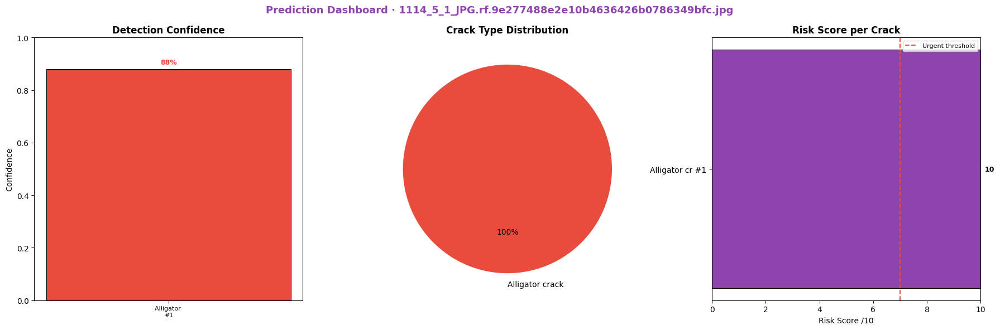

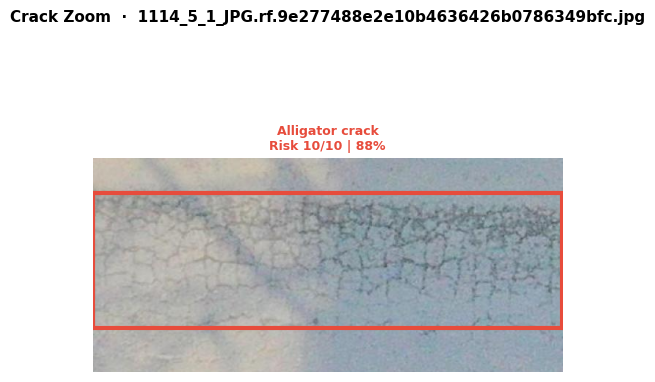

[8] 1114_5_1_JPG.rf.9e277488e2e10b4636426b0786349bfc.jpg  |  1 crack(s)  |  Max risk 10/10  |  CLOSE ROAD – repair within 24 h


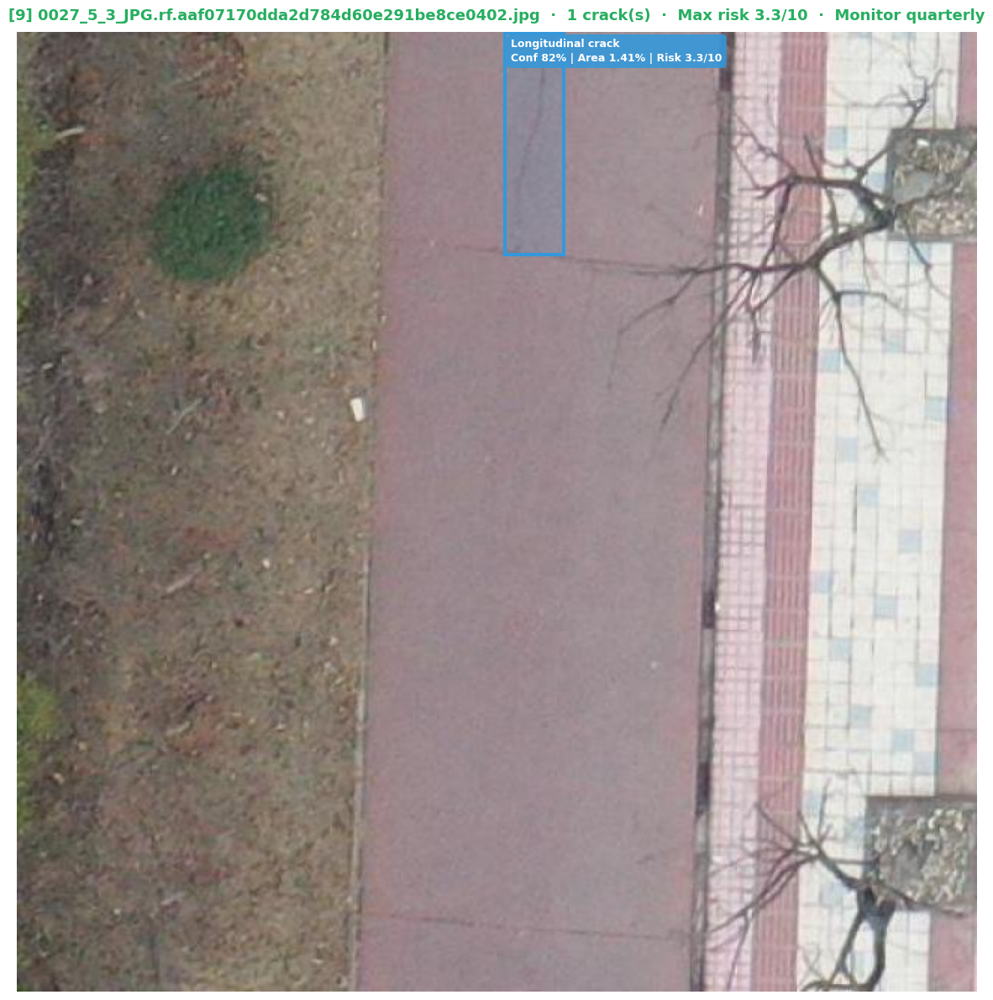

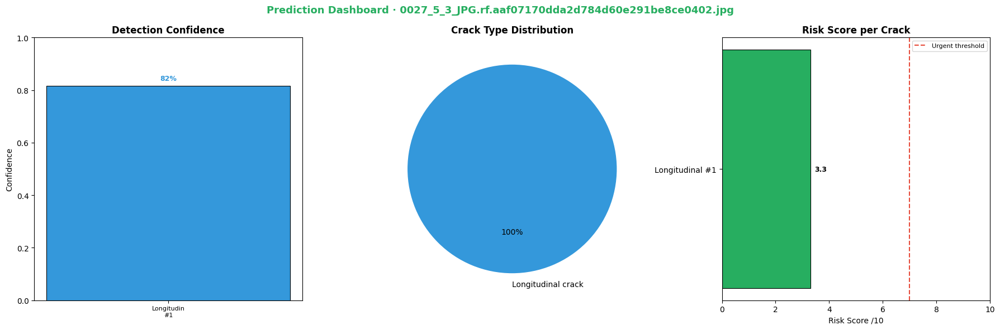

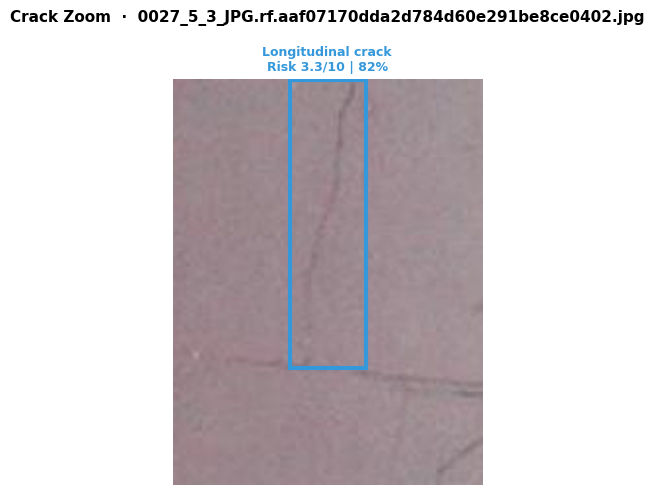

[9] 0027_5_3_JPG.rf.aaf07170dda2d784d60e291be8ce0402.jpg  |  1 crack(s)  |  Max risk 3.3/10  |  Monitor quarterly


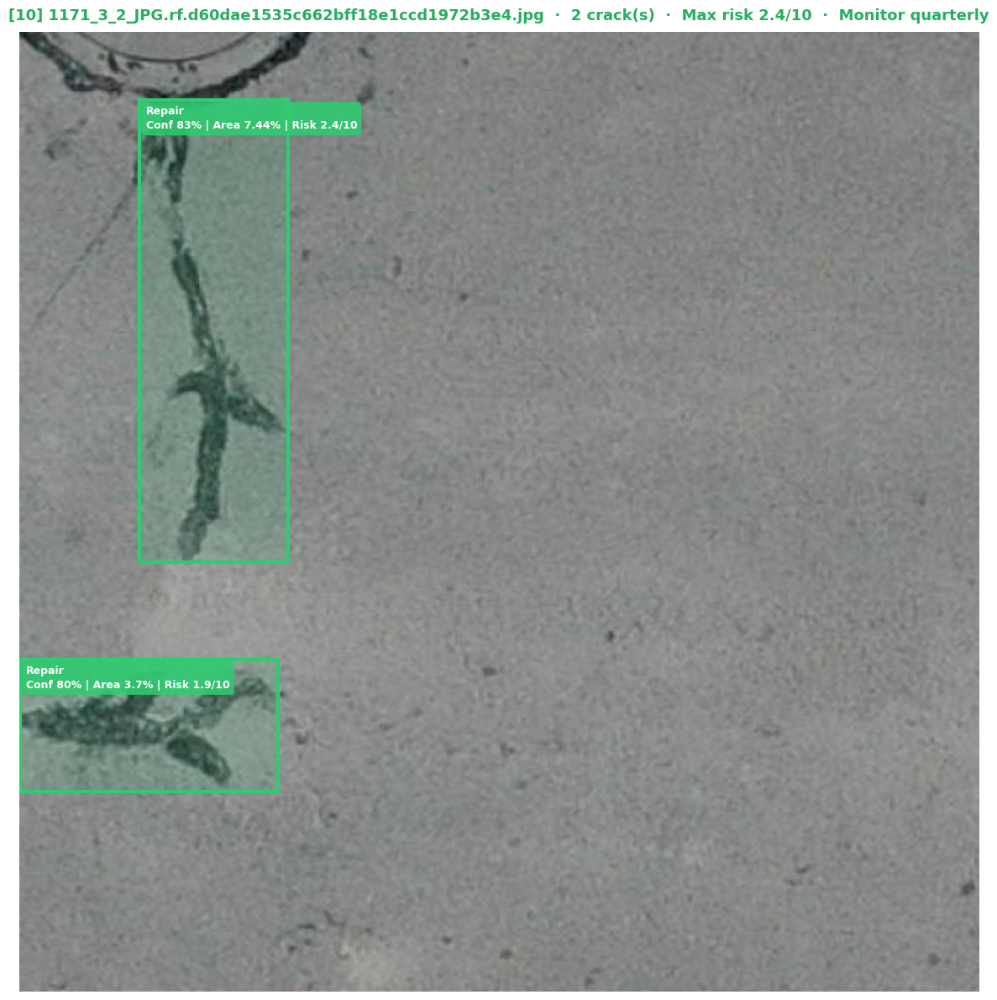

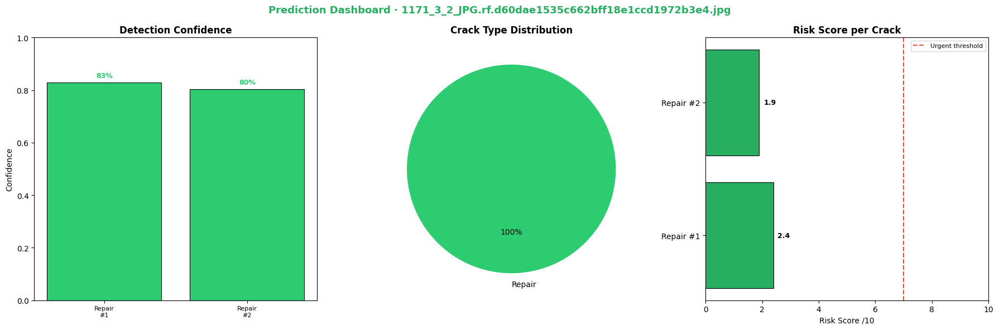

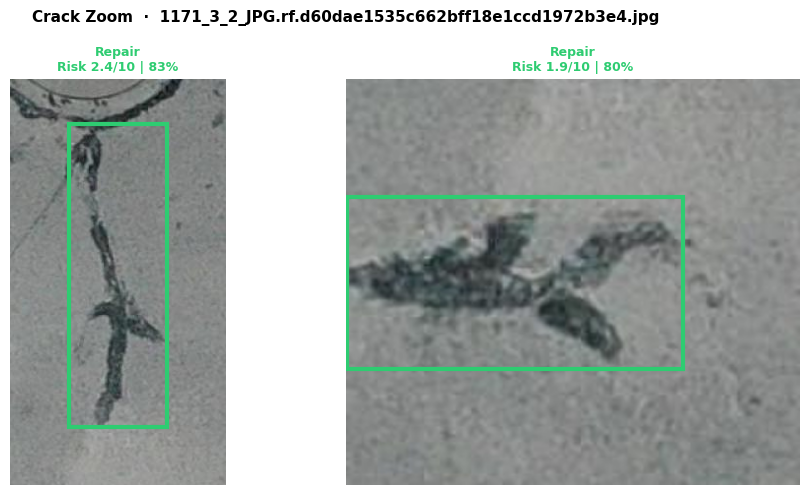

[10] 1171_3_2_JPG.rf.d60dae1535c662bff18e1ccd1972b3e4.jpg  |  2 crack(s)  |  Max risk 2.4/10  |  Monitor quarterly


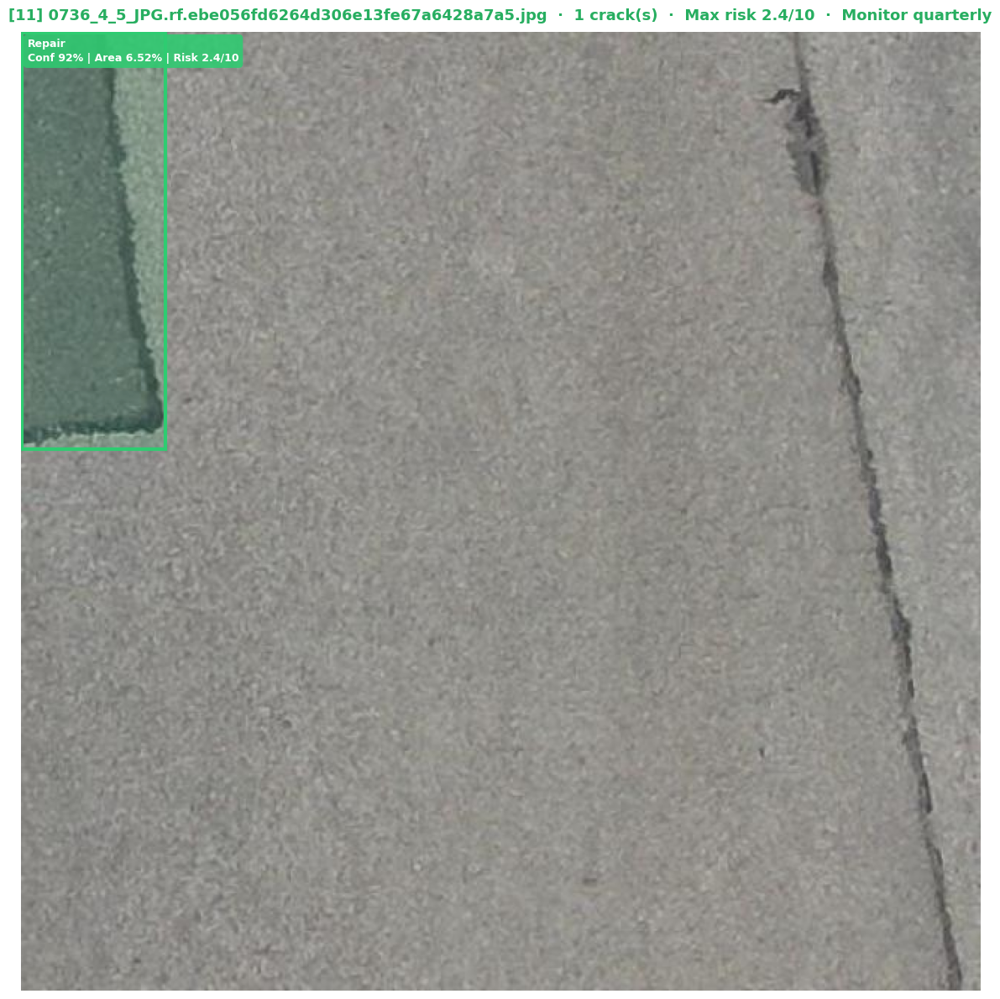

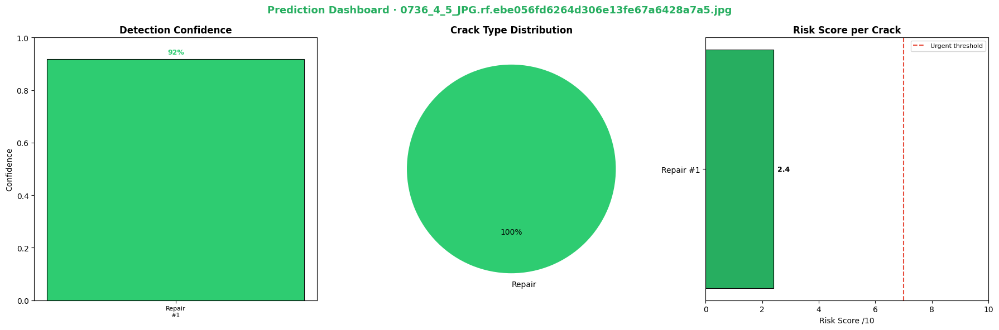

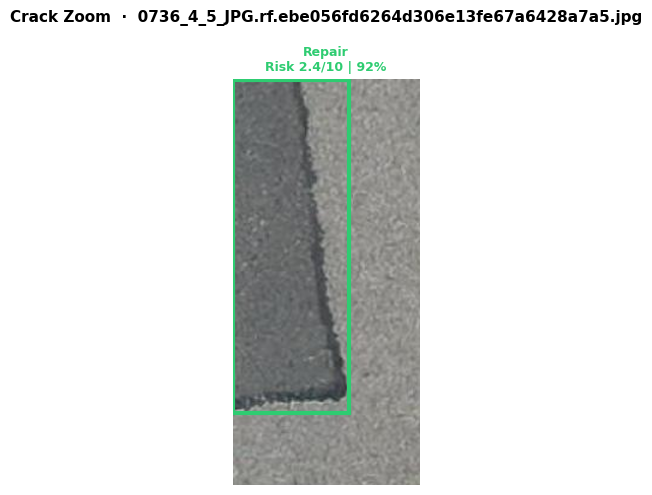

[11] 0736_4_5_JPG.rf.ebe056fd6264d306e13fe67a6428a7a5.jpg  |  1 crack(s)  |  Max risk 2.4/10  |  Monitor quarterly
  ⏭  [12] 0011_1_7_JPG.rf.f5c551ed62dbc4e868adb95916a28803.jpg — no detections


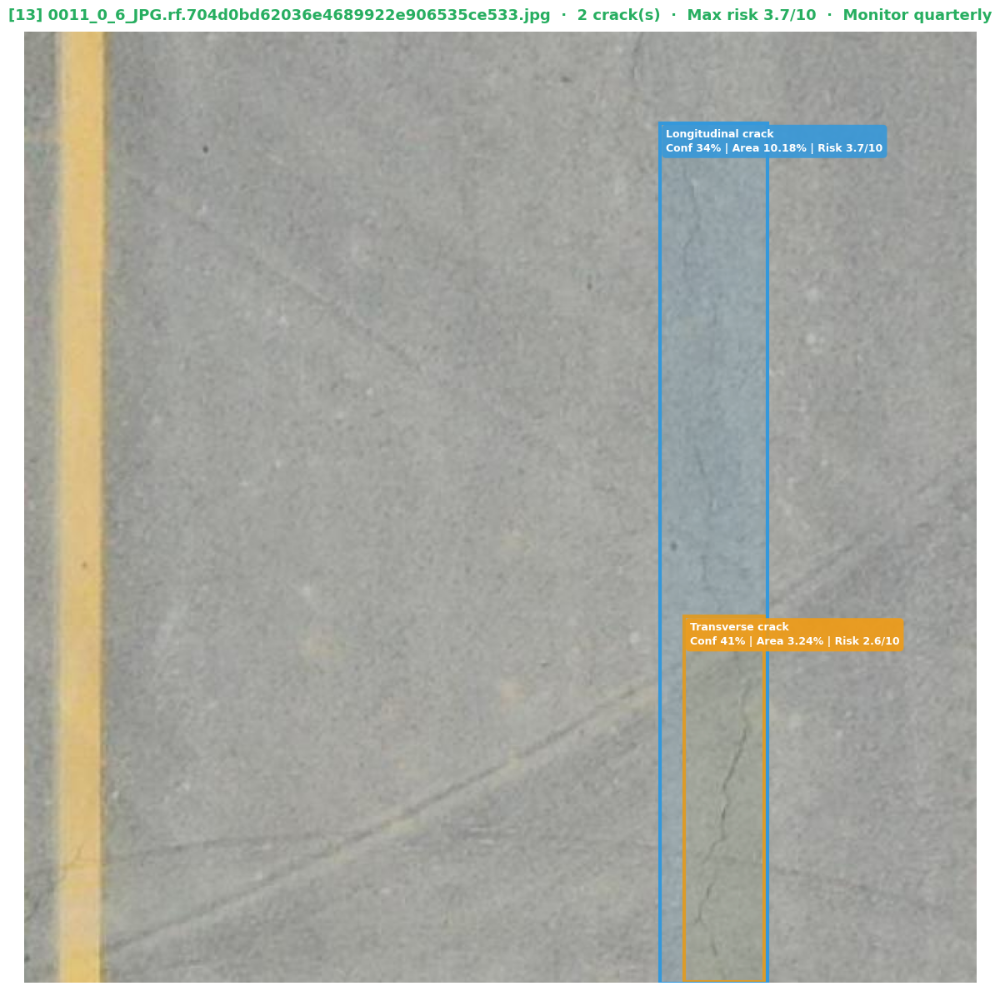

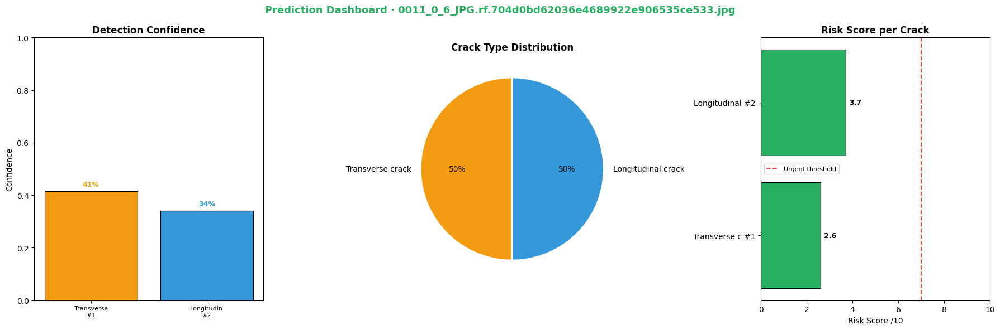

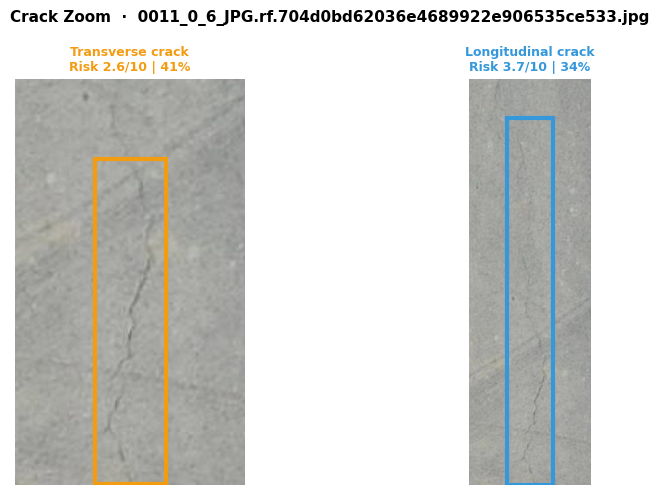

[13] 0011_0_6_JPG.rf.704d0bd62036e4689922e906535ce533.jpg  |  2 crack(s)  |  Max risk 3.7/10  |  Monitor quarterly


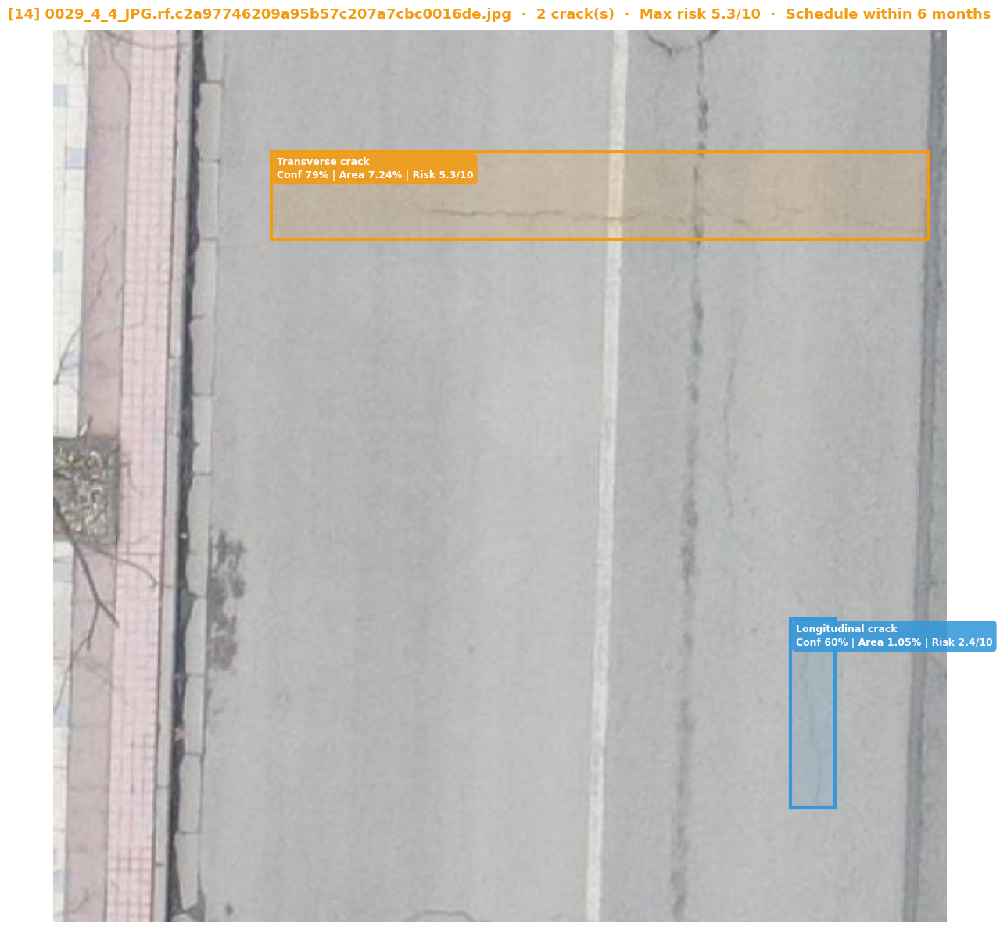

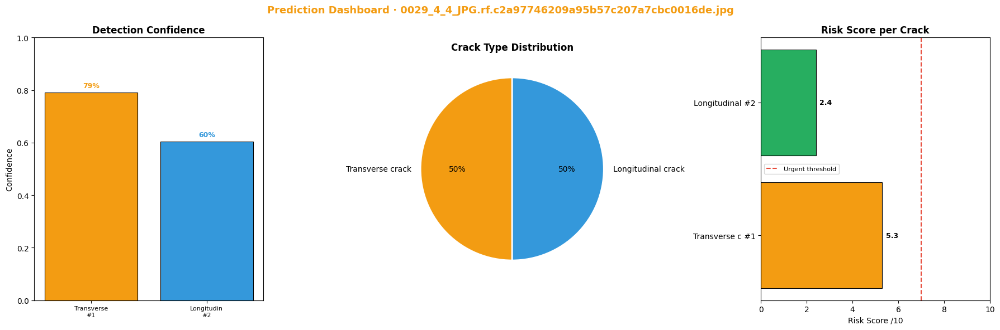

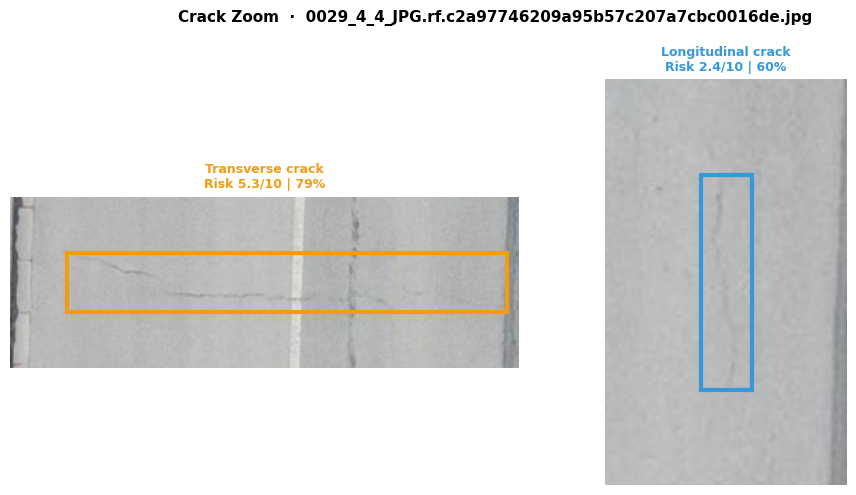

[14] 0029_4_4_JPG.rf.c2a97746209a95b57c207a7cbc0016de.jpg  |  2 crack(s)  |  Max risk 5.3/10  |  Schedule within 6 months


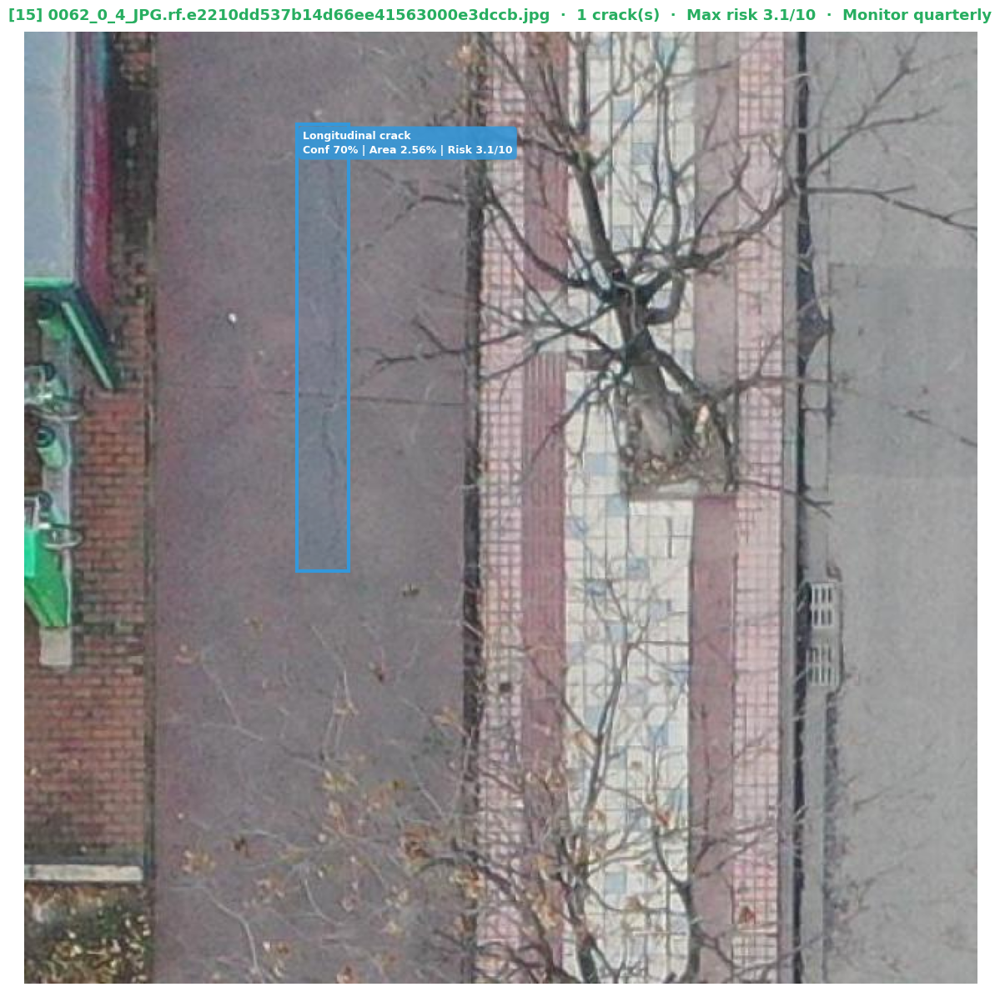

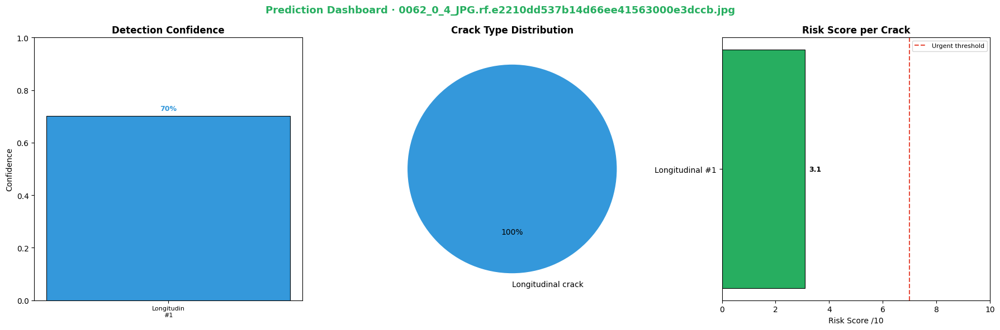

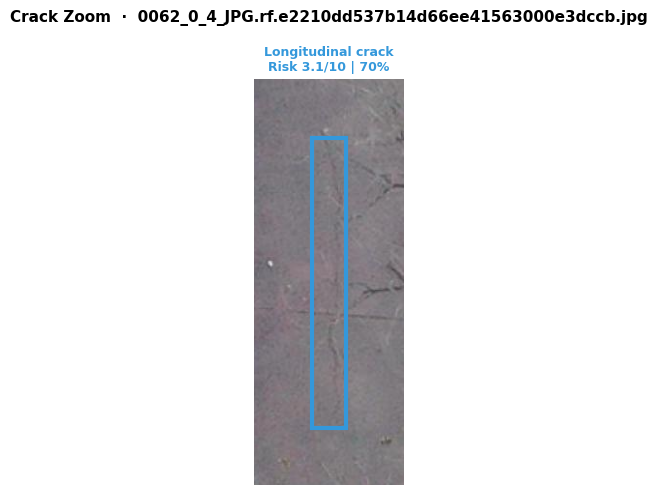

[15] 0062_0_4_JPG.rf.e2210dd537b14d66ee41563000e3dccb.jpg  |  1 crack(s)  |  Max risk 3.1/10  |  Monitor quarterly


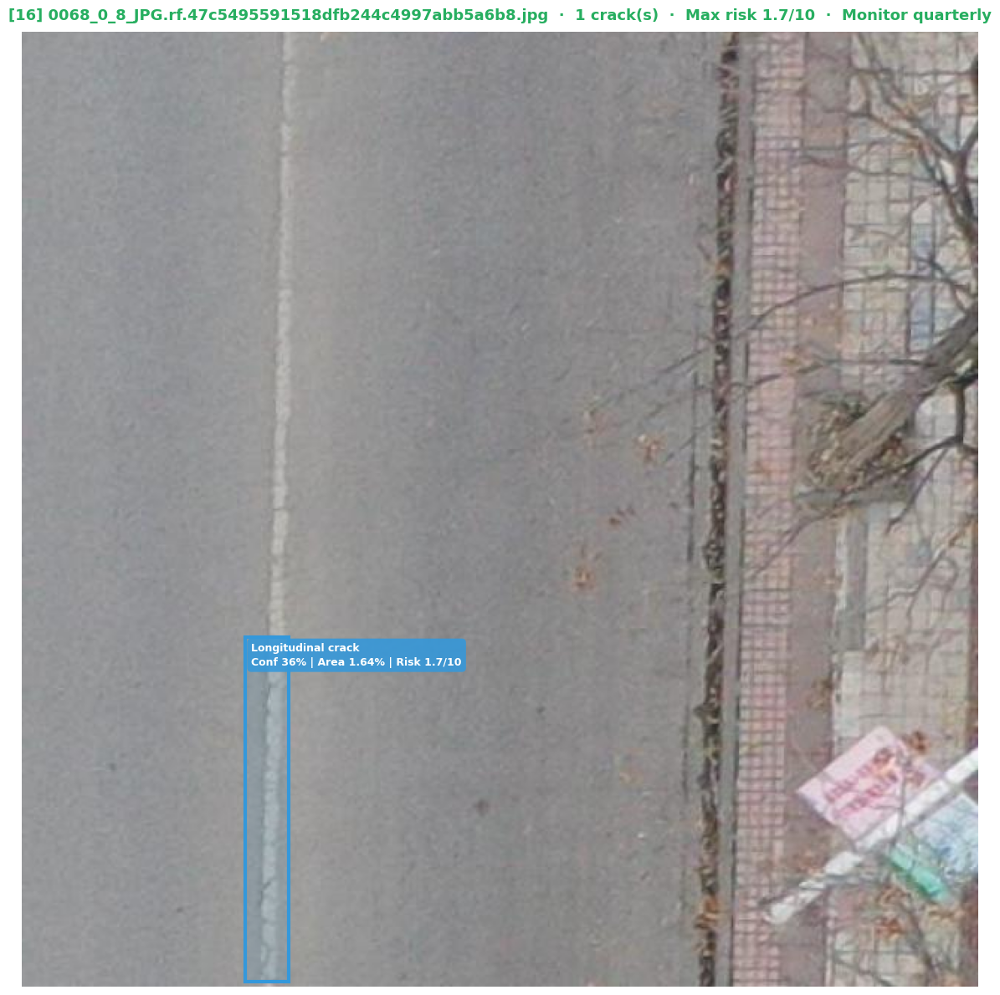

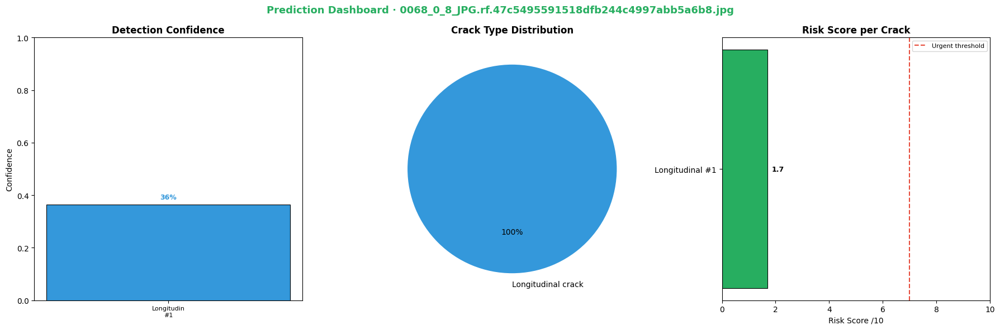

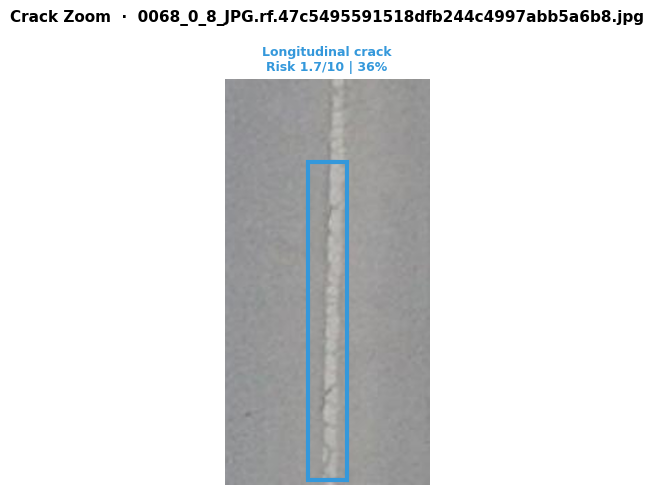

[16] 0068_0_8_JPG.rf.47c5495591518dfb244c4997abb5a6b8.jpg  |  1 crack(s)  |  Max risk 1.7/10  |  Monitor quarterly


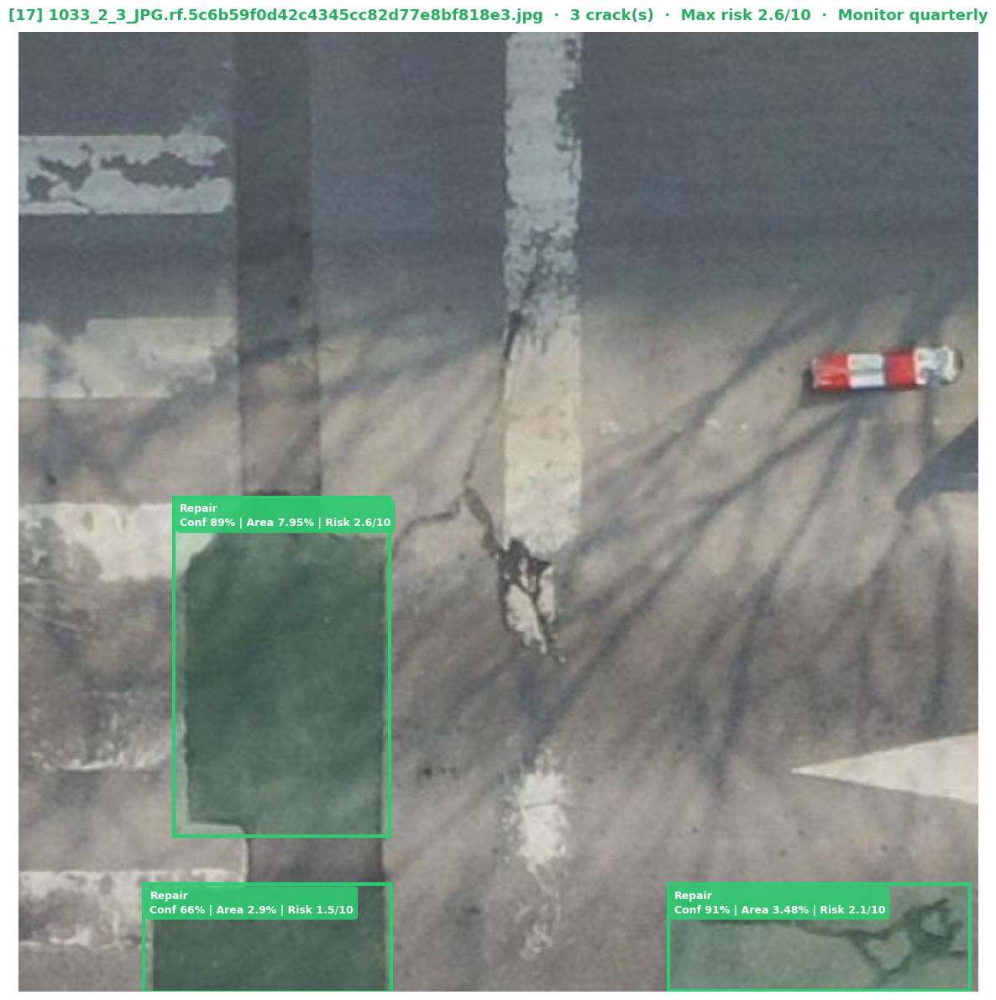

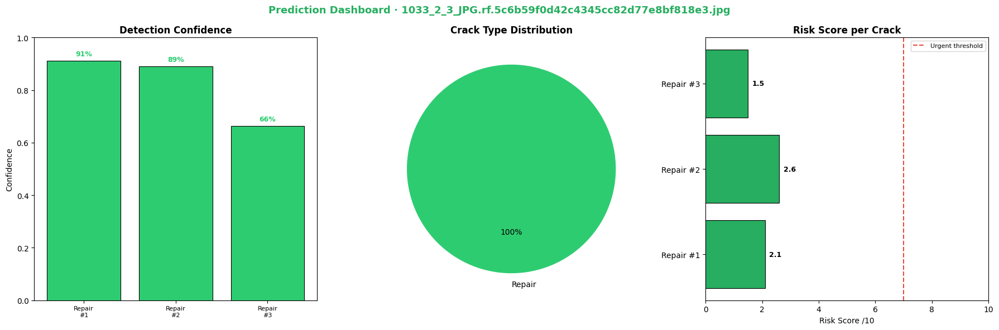

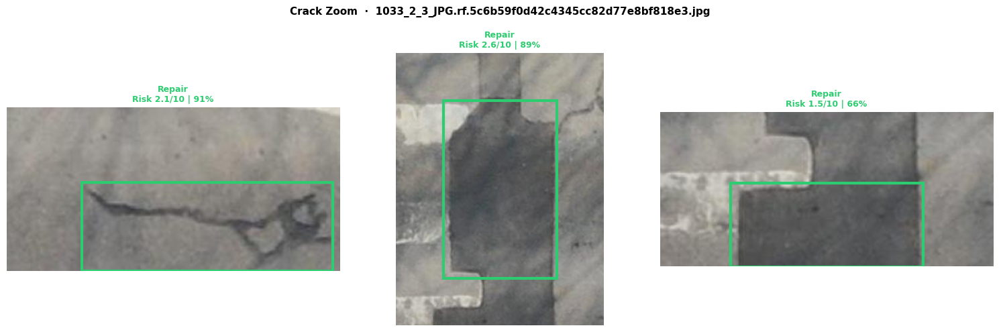

[17] 1033_2_3_JPG.rf.5c6b59f0d42c4345cc82d77e8bf818e3.jpg  |  3 crack(s)  |  Max risk 2.6/10  |  Monitor quarterly


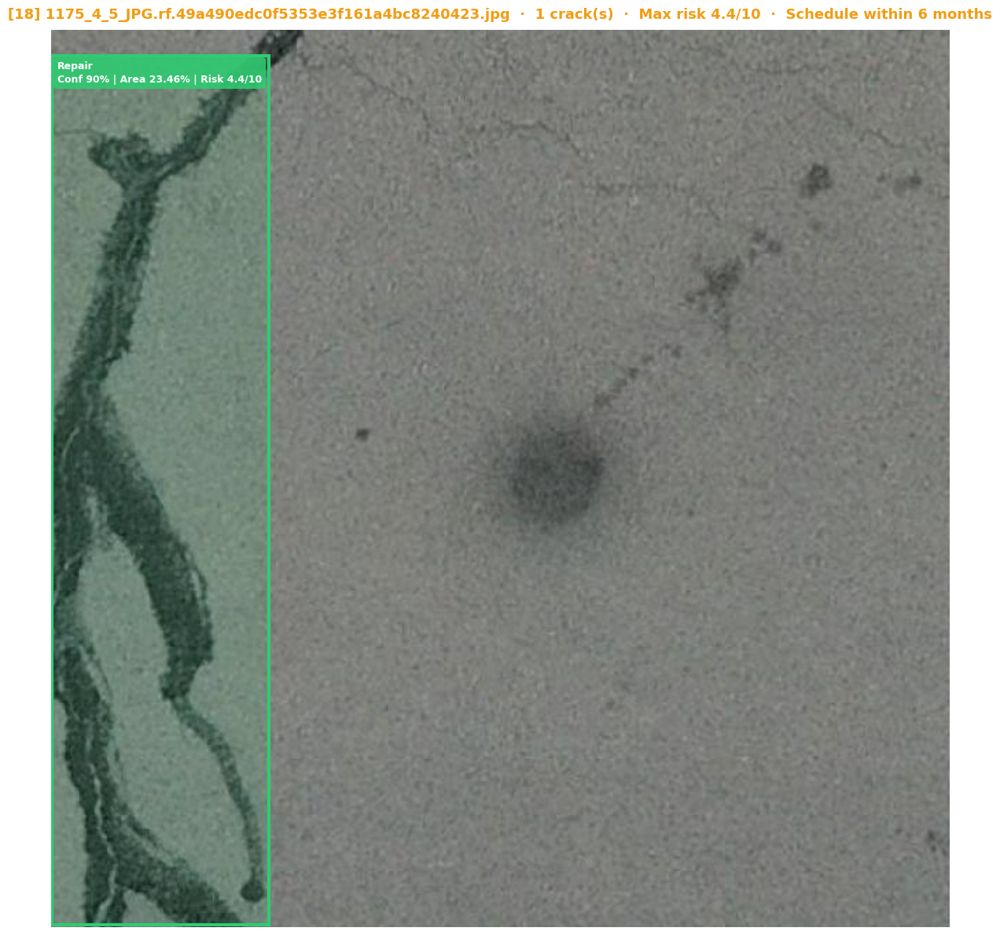

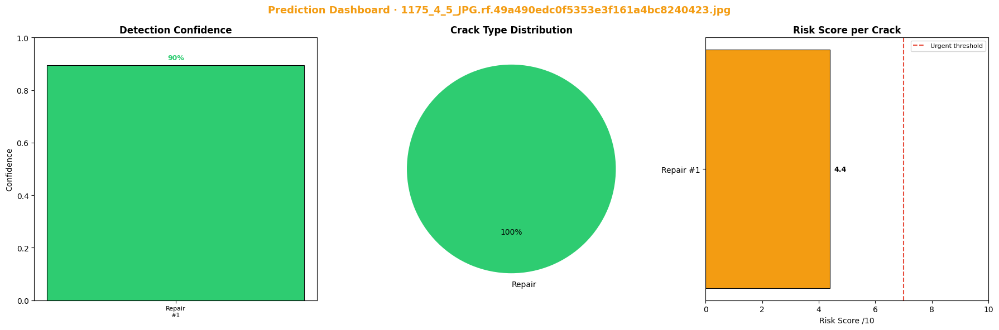

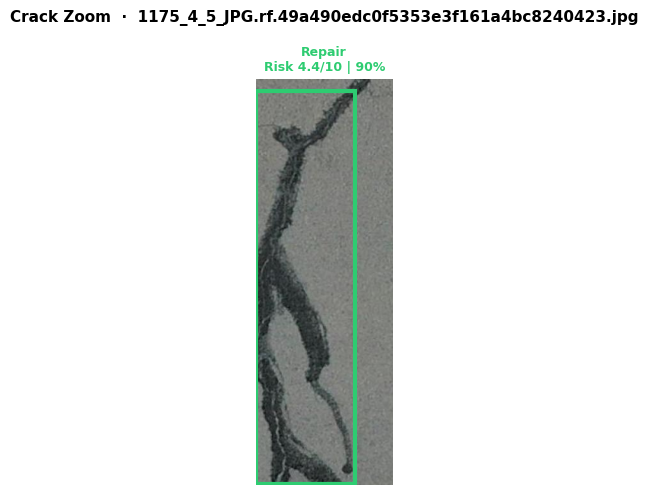

[18] 1175_4_5_JPG.rf.49a490edc0f5353e3f161a4bc8240423.jpg  |  1 crack(s)  |  Max risk 4.4/10  |  Schedule within 6 months
  ⏭  [19] 0008_5_2_JPG.rf.47cccfe57181844ff7e129885c13ccce.jpg — no detections


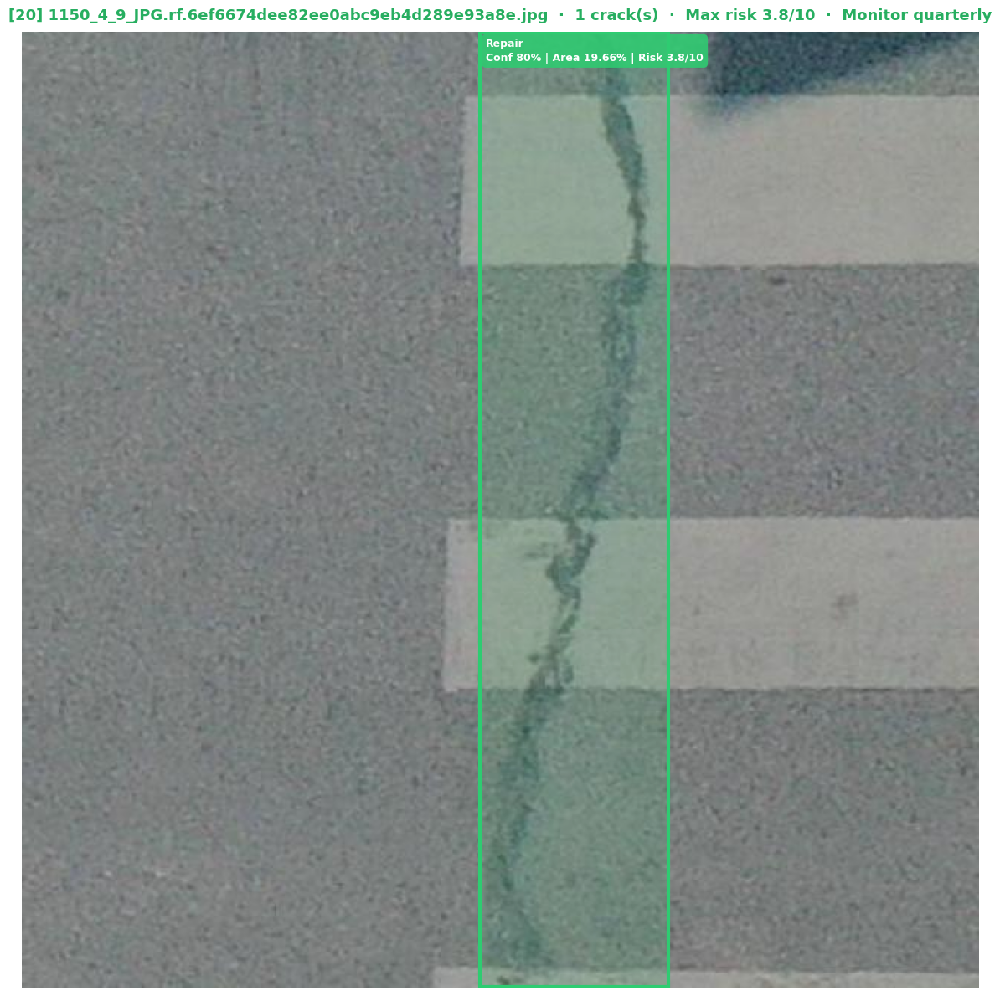

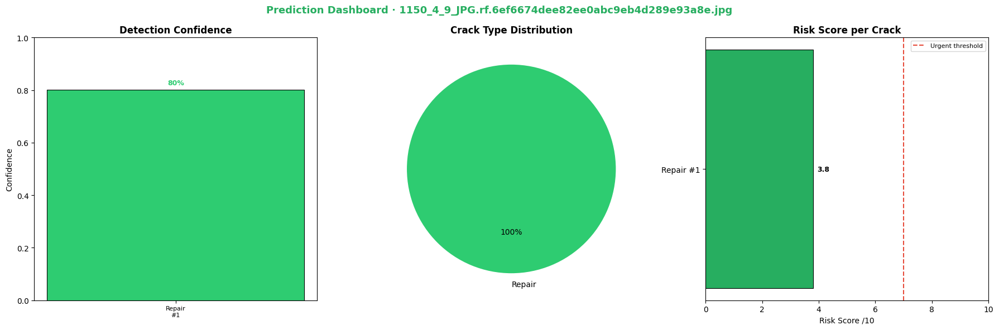

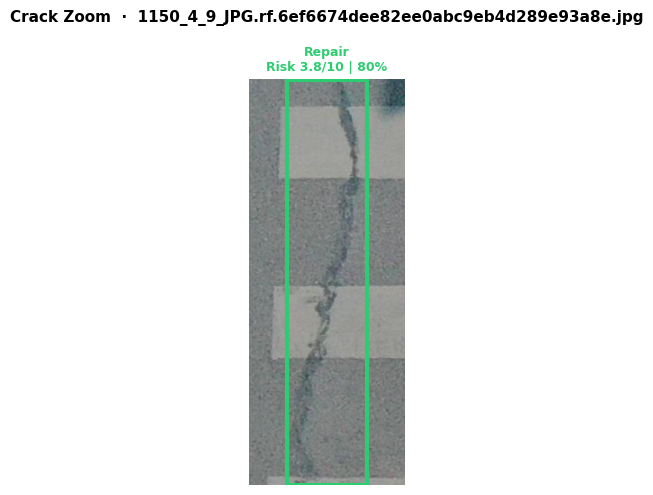

[20] 1150_4_9_JPG.rf.6ef6674dee82ee0abc9eb4d289e93a8e.jpg  |  1 crack(s)  |  Max risk 3.8/10  |  Monitor quarterly


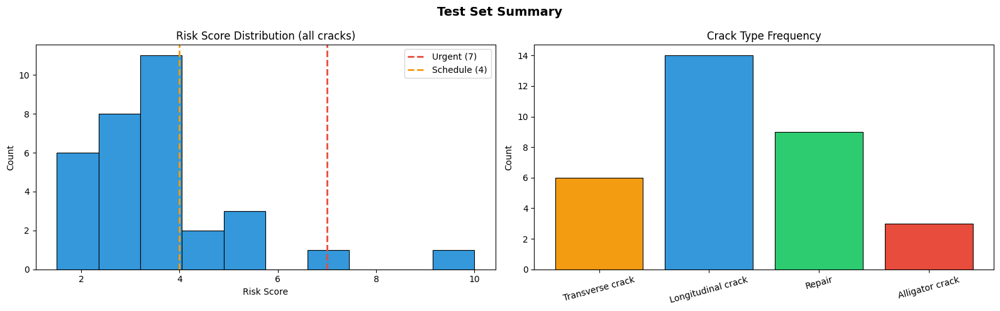


✅ Done  |  17 images  |  32 total cracks  |  Saved → /kaggle/working/predictions


In [28]:
import os, random, json, cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO

# ── CONFIG ────────────────────────────────────────────────────────────────────
MODEL_PATH = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
TEST_DIR   = Path('/kaggle/input/datasets/rachelgenene/clasfication/test/images')
SAVE_DIR   = Path('/kaggle/working/predictions'); SAVE_DIR.mkdir(exist_ok=True)
N_SAMPLES  = 20
CONF       = 0.30

CLASS_NAMES = ['Alligator crack', 'Longitudinal crack', 'Repair', 'Transverse crack']
COLORS      = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
RISK_W      = [9, 6, 3, 7]   # risk weight per class

# ── LOAD ──────────────────────────────────────────────────────────────────────
model    = YOLO(MODEL_PATH)
all_imgs = sorted(list(TEST_DIR.glob('*.jpg')) + list(TEST_DIR.glob('*.png')))
random.seed(42)
samples  = random.sample(all_imgs, min(N_SAMPLES, len(all_imgs)))
print(f"✅ {len(all_imgs)} test images → visualizing {len(samples)}")

log = []

for idx, img_path in enumerate(samples, 1):
    bgr = cv2.imread(str(img_path))
    if bgr is None: continue
    rgb  = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    H, W = rgb.shape[:2]

    res  = model(img_path, conf=CONF, verbose=False)
    dets = []
    if res[0].boxes:
        for box in res[0].boxes:
            x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
            ci   = int(box.cls[0]); cf = float(box.conf[0])
            area = round(((x2-x1)*(y2-y1))/(H*W)*100, 2)
            risk = round(RISK_W[ci] * (cf * 0.6 + area/10 * 0.4), 1)
            dets.append(dict(x1=x1,y1=y1,x2=x2,y2=y2,
                             ct=CLASS_NAMES[ci], ci=ci, cf=cf,
                             area=area, risk=min(risk,10), color=COLORS[ci]))

    if not dets:
        print(f"  ⏭  [{idx}] {img_path.name} — no detections"); continue

    max_risk  = max(d['risk'] for d in dets)
    border    = '#8e44ad' if max_risk>=9 else '#e74c3c' if max_risk>=7 \
                else '#f39c12' if max_risk>=4 else '#27ae60'
    timeline  = ('CLOSE ROAD – repair within 24 h' if max_risk>=9 else
                 'Urgent – repair within 1 month'  if max_risk>=7 else
                 'Schedule within 6 months'         if max_risk>=4 else
                 'Monitor quarterly')

    # ── FIG 1 · Annotated image ───────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(18, 12))
    fig.patch.set_facecolor('white'); ax.imshow(rgb); ax.axis('off')
    for d in dets:
        c = d['color']
        ax.add_patch(patches.Rectangle((d['x1'],d['y1']),
            d['x2']-d['x1'],d['y2']-d['y1'], lw=0, facecolor=c, alpha=0.12))
        ax.add_patch(patches.Rectangle((d['x1'],d['y1']),
            d['x2']-d['x1'],d['y2']-d['y1'], lw=3, edgecolor=c, facecolor='none'))
        ax.text(d['x1']+4, d['y1']+4,
                f"{d['ct']}\nConf {d['cf']:.0%} | Area {d['area']}% | Risk {d['risk']}/10",
                fontsize=9, color='white', fontweight='bold', va='top', linespacing=1.4,
                bbox=dict(boxstyle='round,pad=0.4', facecolor=c, alpha=0.88, lw=0))
    for sp in ax.spines.values(): sp.set_edgecolor(border); sp.set_linewidth(6)
    ax.set_title(f"[{idx}] {img_path.name}  ·  {len(dets)} crack(s)  ·  "
                 f"Max risk {max_risk}/10  ·  {timeline}",
                 fontsize=13, fontweight='bold', color=border, pad=10)
    plt.tight_layout()
    plt.savefig(SAVE_DIR/f"ann_{idx:03d}.png", dpi=130, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()

    # ── FIG 2 · Dashboard: bar + pie + risk gauge ─────────────────────────────
    fig2, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig2.patch.set_facecolor('white')
    fig2.suptitle(f"Prediction Dashboard · {img_path.name}",
                  fontsize=13, fontweight='bold', color=border)

    # Bar – confidence per detection
    labels = [f"{d['ct'][:10]}\n#{i+1}" for i,d in enumerate(dets)]
    confs  = [d['cf'] for d in dets]
    cols   = [d['color'] for d in dets]
    axes[0].bar(labels, confs, color=cols, edgecolor='black', linewidth=0.8)
    axes[0].set_ylim(0,1); axes[0].set_ylabel('Confidence')
    axes[0].set_title('Detection Confidence', fontweight='bold')
    axes[0].tick_params(axis='x', labelsize=8)
    for i,(v,c) in enumerate(zip(confs,cols)):
        axes[0].text(i, v+0.02, f'{v:.0%}', ha='center', fontsize=9, color=c, fontweight='bold')

    # Pie – class distribution
    from collections import Counter
    ct_counts = Counter(d['ct'] for d in dets)
    axes[1].pie(ct_counts.values(), labels=ct_counts.keys(),
                colors=[COLORS[CLASS_NAMES.index(k)] for k in ct_counts],
                autopct='%1.0f%%', startangle=90,
                wedgeprops=dict(edgecolor='white', linewidth=2))
    axes[1].set_title('Crack Type Distribution', fontweight='bold')

    # Risk gauge (horizontal bar)
    risks  = [d['risk'] for d in dets]
    yticks = [f"{d['ct'][:12]} #{i+1}" for i,d in enumerate(dets)]
    hcols  = ['#8e44ad' if r>=9 else '#e74c3c' if r>=7
              else '#f39c12' if r>=4 else '#27ae60' for r in risks]
    axes[2].barh(yticks, risks, color=hcols, edgecolor='black', linewidth=0.8)
    axes[2].set_xlim(0,10); axes[2].set_xlabel('Risk Score /10')
    axes[2].set_title('Risk Score per Crack', fontweight='bold')
    axes[2].axvline(7, color='#e74c3c', lw=1.5, ls='--', label='Urgent threshold')
    axes[2].legend(fontsize=8)
    for i,v in enumerate(risks):
        axes[2].text(v+0.15, i, f'{v}', va='center', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.savefig(SAVE_DIR/f"dash_{idx:03d}.png", dpi=130, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()

    # ── FIG 3 · Zoom crops per crack ─────────────────────────────────────────
    ncols = min(len(dets), 4)
    fig3, axes3 = plt.subplots(1, ncols, figsize=(5*ncols, 5))
    fig3.patch.set_facecolor('white')
    if ncols == 1: axes3 = [axes3]
    for ax3, d in zip(axes3, dets):
        pad  = 60
        x1c  = max(0,d['x1']-pad); y1c=max(0,d['y1']-pad)
        x2c  = min(W,d['x2']+pad); y2c=min(H,d['y2']+pad)
        crop = rgb[y1c:y2c, x1c:x2c]
        sh,sw = crop.shape[:2]
        scale = max(1.0, 400/max(sh,sw,1))
        crop  = cv2.resize(crop,(int(sw*scale),int(sh*scale)),interpolation=cv2.INTER_CUBIC)
        ax3.imshow(crop); ax3.axis('off')
        bx=(d['x1']-x1c)*scale; by=(d['y1']-y1c)*scale
        bw=(d['x2']-d['x1'])*scale; bh=(d['y2']-d['y1'])*scale
        ax3.add_patch(patches.Rectangle((bx,by),bw,bh,lw=3,
                      edgecolor=d['color'],facecolor='none'))
        ax3.set_title(f"{d['ct']}\nRisk {d['risk']}/10 | {d['cf']:.0%}",
                      fontsize=9, fontweight='bold', color=d['color'])
    fig3.suptitle(f"Crack Zoom  ·  {img_path.name}", fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(SAVE_DIR/f"zoom_{idx:03d}.png", dpi=130, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()

    print(f"[{idx}] {img_path.name}  |  {len(dets)} crack(s)  |  "
          f"Max risk {max_risk}/10  |  {timeline}")
    log.append(dict(image=img_path.name, n_cracks=len(dets),
                    max_risk=max_risk, timeline=timeline,
                    dets=[dict(type=d['ct'],conf=round(d['cf'],3),
                               area=d['area'],risk=d['risk']) for d in dets]))

# ── SUMMARY CHART ─────────────────────────────────────────────────────────────
if log:
    fig4, axes4 = plt.subplots(1, 2, figsize=(16, 5))
    fig4.patch.set_facecolor('white')
    fig4.suptitle('Test Set Summary', fontsize=14, fontweight='bold')

    # Risk distribution across all images
    all_risks = [d['risk'] for r in log for d in r['dets']]
    axes4[0].hist(all_risks, bins=10, color='#3498db', edgecolor='black', linewidth=0.8)
    axes4[0].axvline(7, color='#e74c3c', lw=2, ls='--', label='Urgent (7)')
    axes4[0].axvline(4, color='#f39c12', lw=2, ls='--', label='Schedule (4)')
    axes4[0].set_xlabel('Risk Score'); axes4[0].set_ylabel('Count')
    axes4[0].set_title('Risk Score Distribution (all cracks)'); axes4[0].legend()

    # Class frequency
    from collections import Counter
    all_types = Counter(d['type'] for r in log for d in r['dets'])
    axes4[1].bar(all_types.keys(), all_types.values(),
                 color=[COLORS[CLASS_NAMES.index(k)] for k in all_types],
                 edgecolor='black', linewidth=0.8)
    axes4[1].set_ylabel('Count'); axes4[1].set_title('Crack Type Frequency')
    axes4[1].tick_params(axis='x', rotation=15)

    plt.tight_layout()
    plt.savefig(SAVE_DIR/'summary.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close()

with open(SAVE_DIR/'report.json','w') as f: json.dump(log, f, indent=2)
print(f"\n✅ Done  |  {len(log)} images  |  "
      f"{sum(r['n_cracks'] for r in log)} total cracks  |  Saved → {SAVE_DIR}")

# test on unseen image

✅  5758 test images found  →  sampling 50

▶  Predicting — asphalt cracks only, full-screen display...

  ⏭️  [1/50]  United_States_001467.jpg  — no asphalt cracks, skipped
  ⏭️  [2/50]  Czech_001949.jpg  — no asphalt cracks, skipped


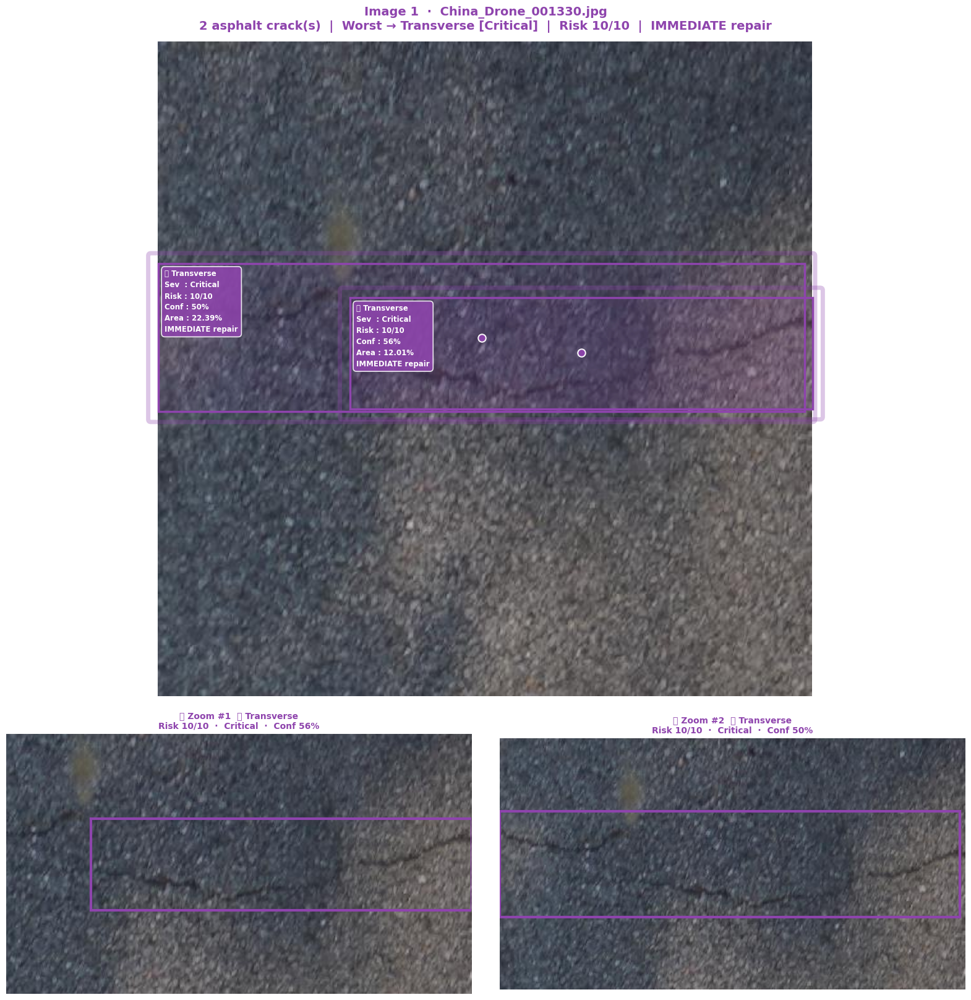

══════════════════════════════════════════════════════════════
  [1]  China_Drone_001330.jpg  (10:53:46)
  1. 🟣 Transverse      Risk   10/10  Critical   Area 12.01%  Conf 56%  →  IMMEDIATE repair
  2. 🟣 Transverse      Risk   10/10  Critical   Area 22.39%  Conf 50%  →  IMMEDIATE repair
  ⏭️  [4/50]  India_009679.jpg  — no asphalt cracks, skipped
  ⏭️  [5/50]  India_007623.jpg  — no asphalt cracks, skipped


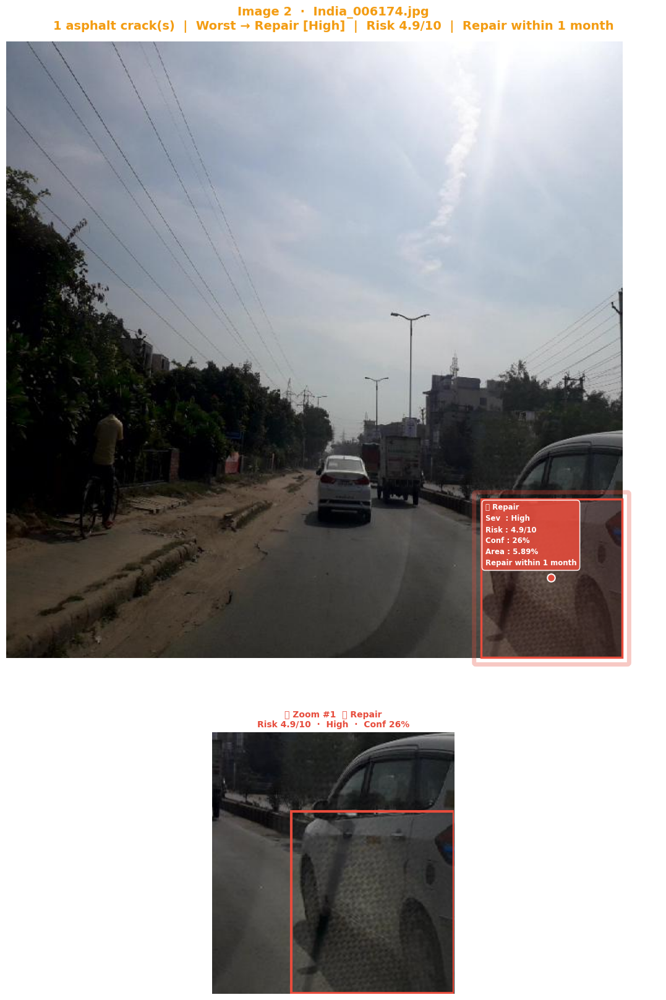

══════════════════════════════════════════════════════════════
  [2]  India_006174.jpg  (10:53:48)
  1. 🔴 Repair          Risk  4.9/10  High       Area  5.89%  Conf 26%  →  Repair within 1 month
  ⏭️  [7/50]  India_000323.jpg  — no asphalt cracks, skipped
  ⏭️  [8/50]  Czech_001318.jpg  — no asphalt cracks, skipped


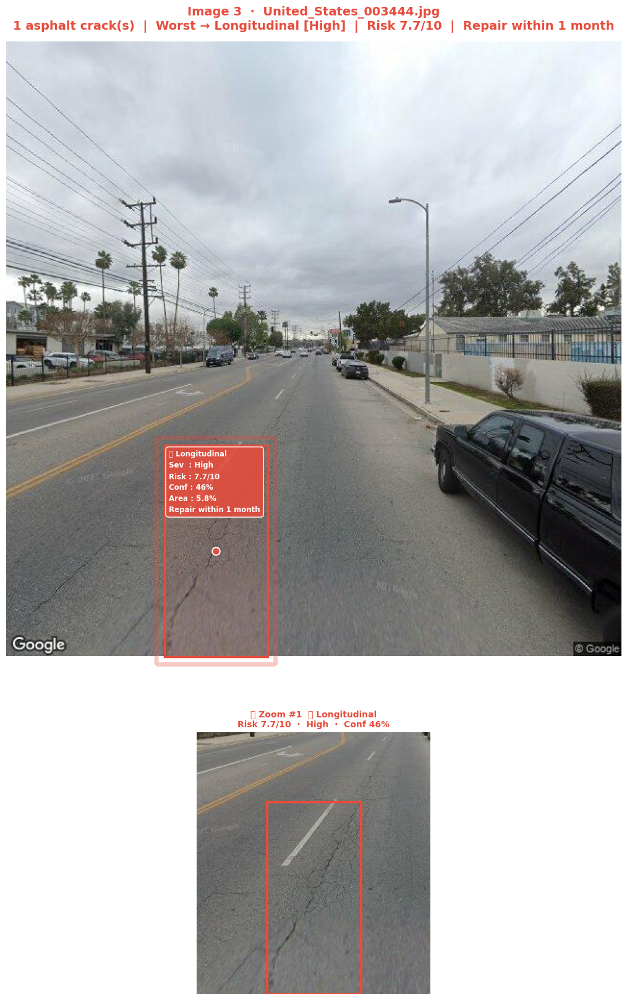

══════════════════════════════════════════════════════════════
  [3]  United_States_003444.jpg  (10:53:50)
  1. 🔴 Longitudinal    Risk  7.7/10  High       Area   5.8%  Conf 46%  →  Repair within 1 month
  ⏭️  [10/50]  Norway_004607.jpg  — no asphalt cracks, skipped
  ⏭️  [11/50]  Czech_000215.jpg  — no asphalt cracks, skipped
  ⏭️  [12/50]  Norway_007042.jpg  — no asphalt cracks, skipped
  ⏭️  [13/50]  Japan_010187.jpg  — no asphalt cracks, skipped


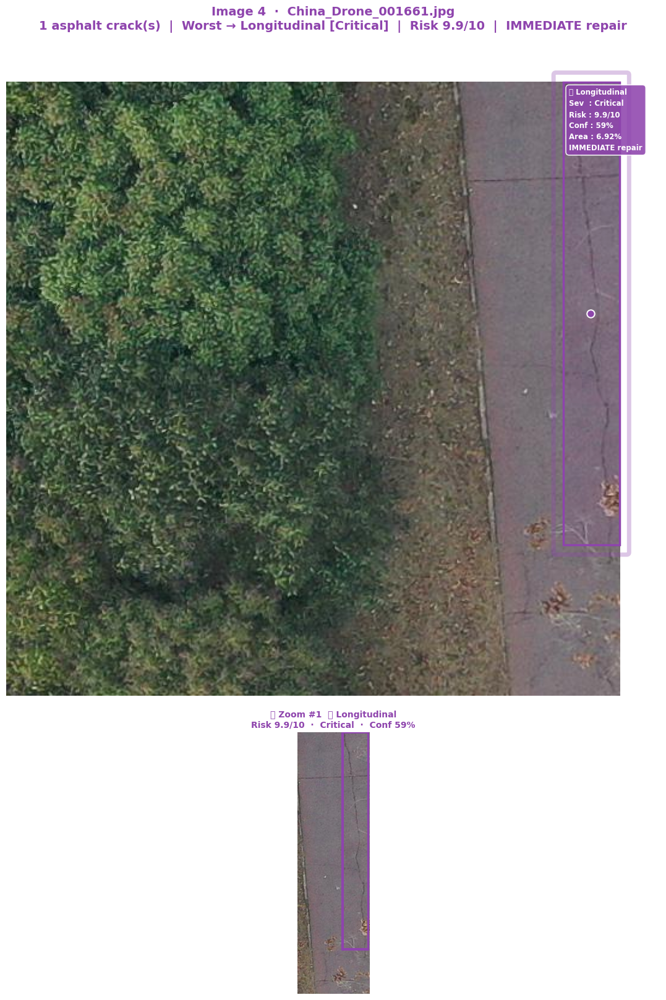

══════════════════════════════════════════════════════════════
  [4]  China_Drone_001661.jpg  (10:53:52)
  1. 🟣 Longitudinal    Risk  9.9/10  Critical   Area  6.92%  Conf 59%  →  IMMEDIATE repair
  ⏭️  [15/50]  China_Drone_001555.jpg  — no asphalt cracks, skipped
  ⏭️  [16/50]  Czech_000685.jpg  — no asphalt cracks, skipped
  ⏭️  [17/50]  India_005886.jpg  — no asphalt cracks, skipped
  ⏭️  [18/50]  India_006819.jpg  — no asphalt cracks, skipped
  ⏭️  [19/50]  Norway_002246.jpg  — no asphalt cracks, skipped
  ⏭️  [20/50]  Norway_007696.jpg  — no asphalt cracks, skipped


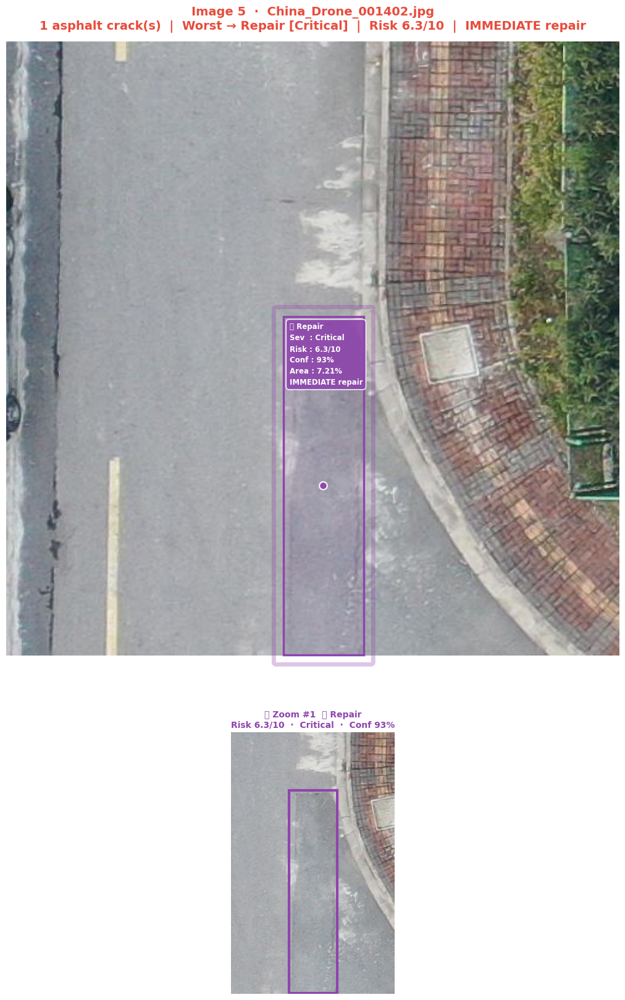

══════════════════════════════════════════════════════════════
  [5]  China_Drone_001402.jpg  (10:53:54)
  1. 🟣 Repair          Risk  6.3/10  Critical   Area  7.21%  Conf 93%  →  IMMEDIATE repair
  ⏭️  [22/50]  Norway_005529.jpg  — no asphalt cracks, skipped
  ⏭️  [23/50]  India_004316.jpg  — no asphalt cracks, skipped
  ⏭️  [24/50]  United_States_001973.jpg  — no asphalt cracks, skipped


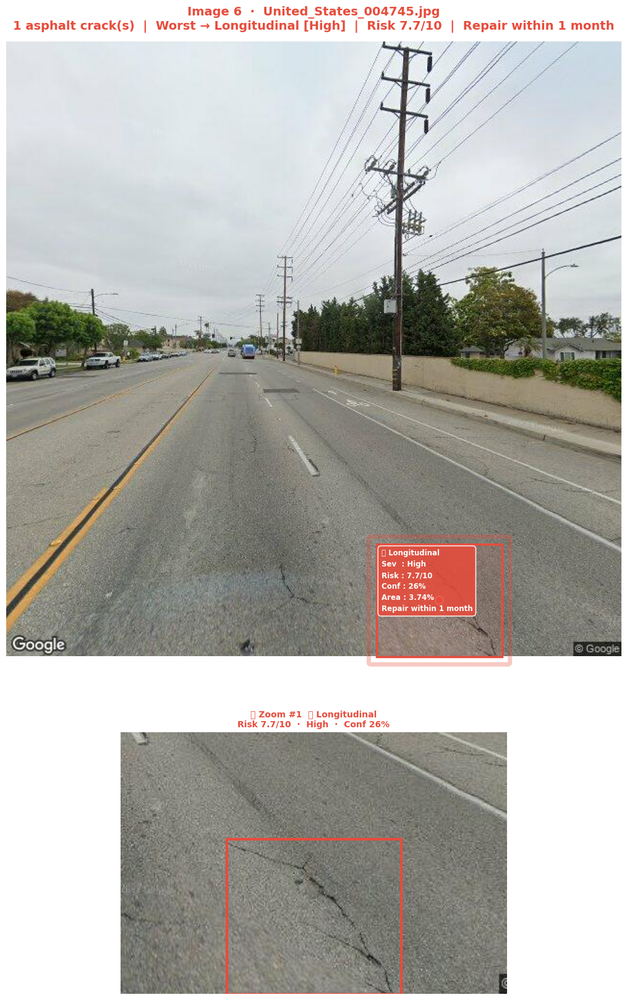

══════════════════════════════════════════════════════════════
  [6]  United_States_004745.jpg  (10:53:57)
  1. 🔴 Longitudinal    Risk  7.7/10  High       Area  3.74%  Conf 26%  →  Repair within 1 month
  ⏭️  [26/50]  Norway_004581.jpg  — no asphalt cracks, skipped


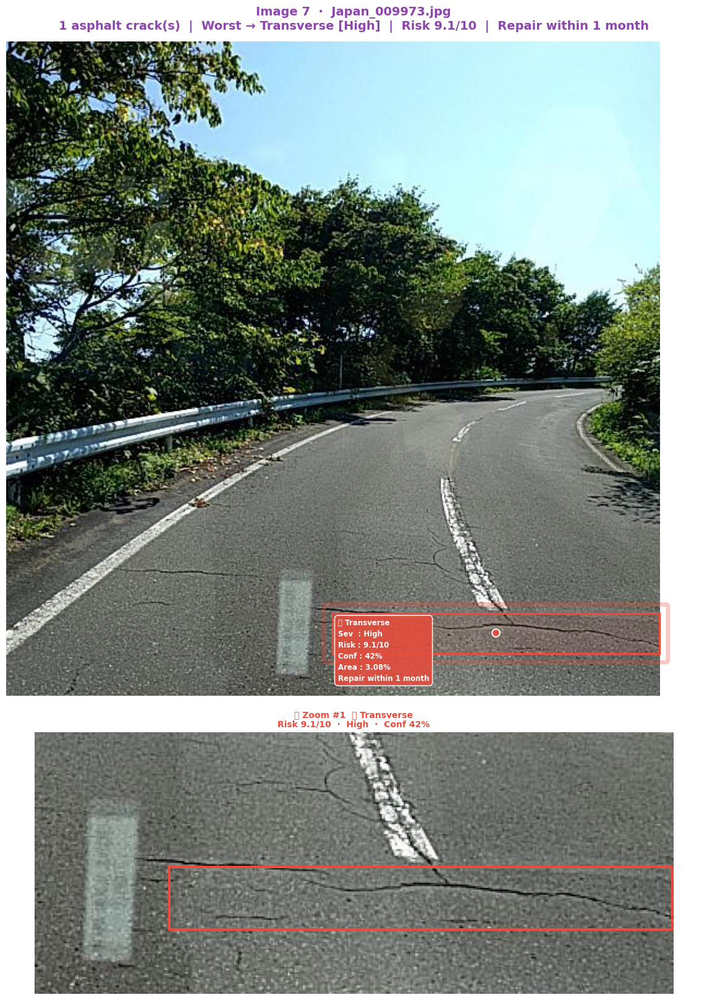

══════════════════════════════════════════════════════════════
  [7]  Japan_009973.jpg  (10:53:59)
  1. 🔴 Transverse      Risk  9.1/10  High       Area  3.08%  Conf 42%  →  Repair within 1 month
  ⏭️  [28/50]  India_005975.jpg  — no asphalt cracks, skipped
  ⏭️  [29/50]  Japan_012101.jpg  — no asphalt cracks, skipped
  ⏭️  [30/50]  Norway_006942.jpg  — no asphalt cracks, skipped
  ⏭️  [31/50]  India_009824.jpg  — no asphalt cracks, skipped


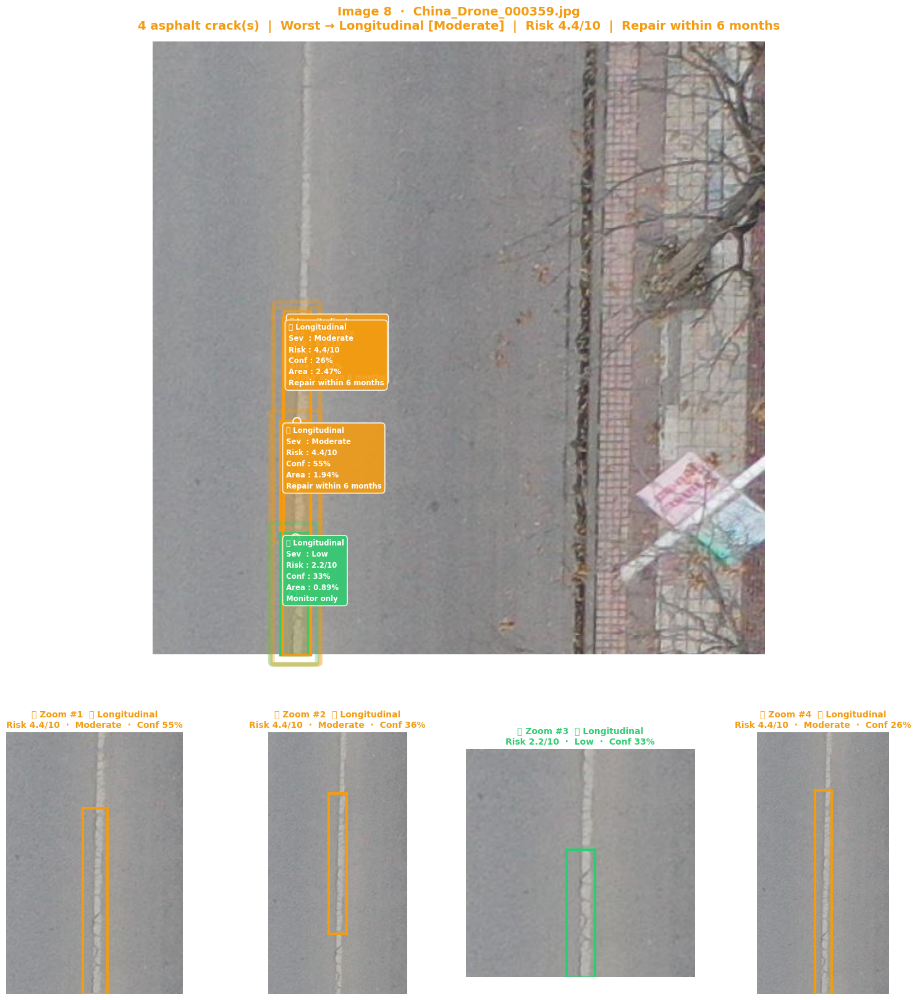

══════════════════════════════════════════════════════════════
  [8]  China_Drone_000359.jpg  (10:54:02)
  1. 🟡 Longitudinal    Risk  4.4/10  Moderate   Area  1.94%  Conf 55%  →  Repair within 6 months
  2. 🟡 Longitudinal    Risk  4.4/10  Moderate   Area  1.62%  Conf 36%  →  Repair within 6 months
  3. 🟢 Longitudinal    Risk  2.2/10  Low        Area  0.89%  Conf 33%  →  Monitor only
  4. 🟡 Longitudinal    Risk  4.4/10  Moderate   Area  2.47%  Conf 26%  →  Repair within 6 months
  ⏭️  [33/50]  India_001595.jpg  — no asphalt cracks, skipped


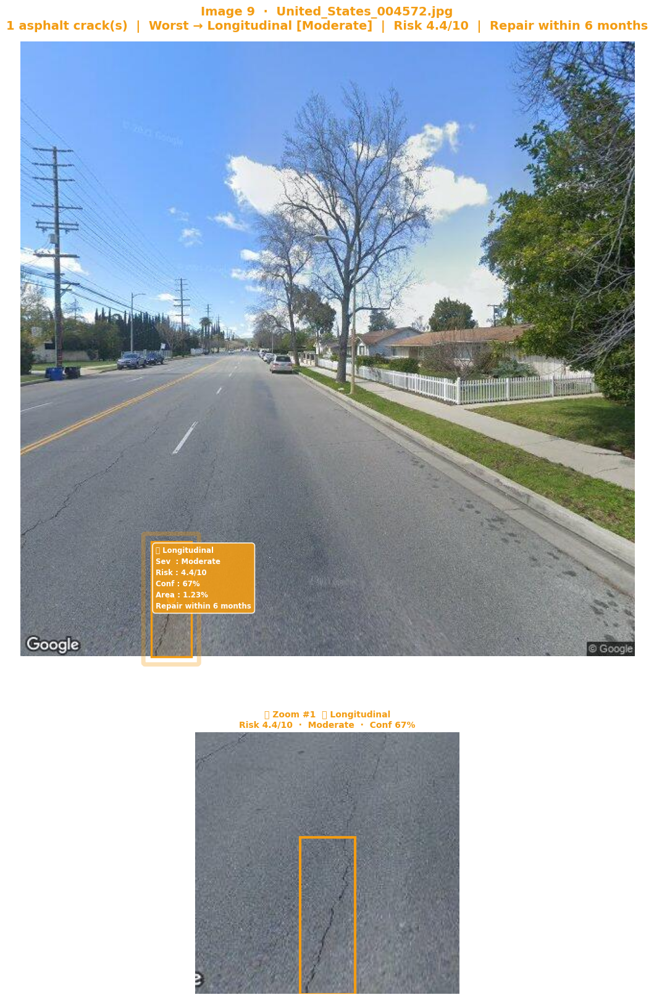

══════════════════════════════════════════════════════════════
  [9]  United_States_004572.jpg  (10:54:04)
  1. 🟡 Longitudinal    Risk  4.4/10  Moderate   Area  1.23%  Conf 67%  →  Repair within 6 months
  ⏭️  [35/50]  Japan_010260.jpg  — no asphalt cracks, skipped


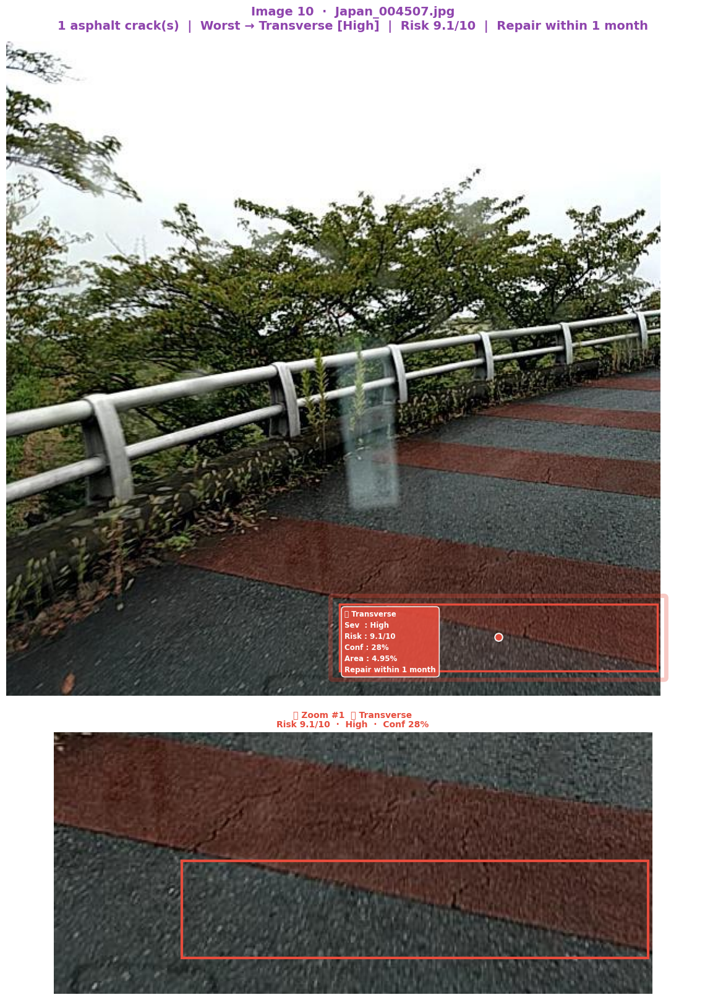

══════════════════════════════════════════════════════════════
  [10]  Japan_004507.jpg  (10:54:06)
  1. 🔴 Transverse      Risk  9.1/10  High       Area  4.95%  Conf 28%  →  Repair within 1 month
  ⏭️  [37/50]  India_009815.jpg  — no asphalt cracks, skipped
  ⏭️  [38/50]  India_001389.jpg  — no asphalt cracks, skipped
  ⏭️  [39/50]  India_005674.jpg  — no asphalt cracks, skipped
  ⏭️  [40/50]  Japan_004321.jpg  — no asphalt cracks, skipped
  ⏭️  [41/50]  Czech_001293.jpg  — no asphalt cracks, skipped
  ⏭️  [42/50]  Czech_000600.jpg  — no asphalt cracks, skipped
  ⏭️  [43/50]  Japan_007279.jpg  — no asphalt cracks, skipped
  ⏭️  [44/50]  Czech_000900.jpg  — no asphalt cracks, skipped
  ⏭️  [45/50]  Japan_005839.jpg  — no asphalt cracks, skipped


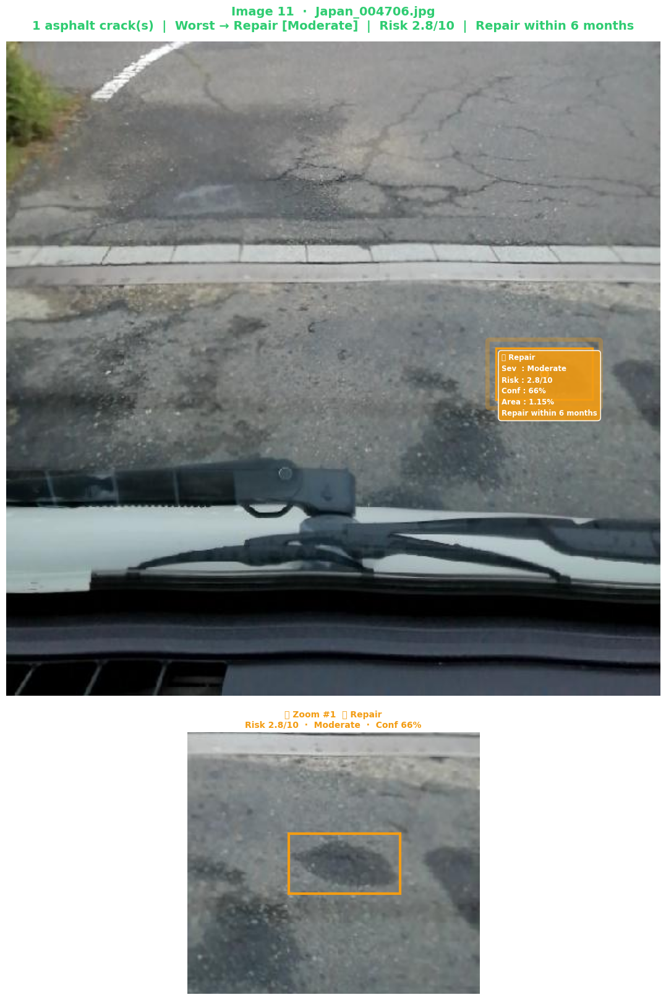

══════════════════════════════════════════════════════════════
  [11]  Japan_004706.jpg  (10:54:09)
  1. 🟡 Repair          Risk  2.8/10  Moderate   Area  1.15%  Conf 66%  →  Repair within 6 months
  ⏭️  [47/50]  Norway_007767.jpg  — no asphalt cracks, skipped
  ⏭️  [48/50]  India_008955.jpg  — no asphalt cracks, skipped


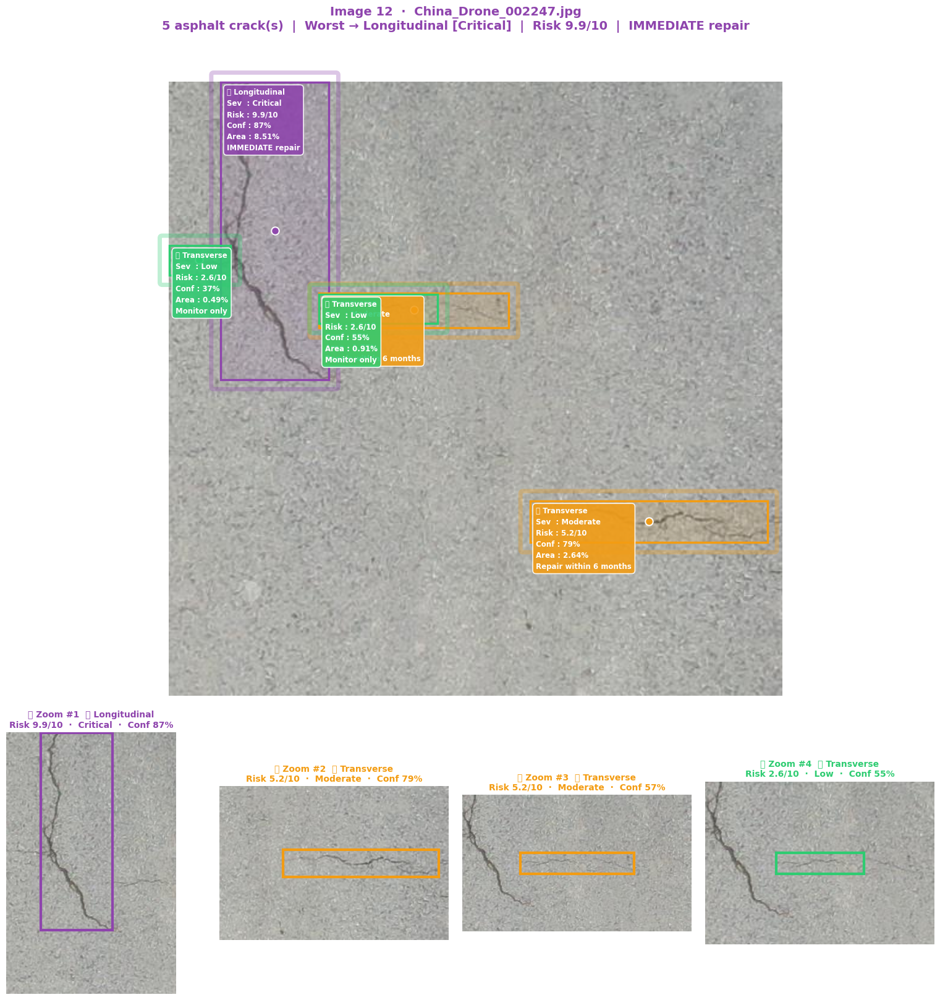

══════════════════════════════════════════════════════════════
  [12]  China_Drone_002247.jpg  (10:54:12)
  1. 🟣 Longitudinal    Risk  9.9/10  Critical   Area  8.51%  Conf 87%  →  IMMEDIATE repair
  2. 🟡 Transverse      Risk  5.2/10  Moderate   Area  2.64%  Conf 79%  →  Repair within 6 months
  3. 🟡 Transverse      Risk  5.2/10  Moderate   Area  1.75%  Conf 57%  →  Repair within 6 months
  4. 🟢 Transverse      Risk  2.6/10  Low        Area  0.91%  Conf 55%  →  Monitor only
  5. 🟢 Transverse      Risk  2.6/10  Low        Area  0.49%  Conf 37%  →  Monitor only
  ⏭️  [50/50]  Japan_012797.jpg  — no asphalt cracks, skipped

══════════════════════════════════════════════════════════════
  DONE
  Crack images shown : 12
  Clean  skipped     : 38
  Total cracks found : 20
  Saved to           : /kaggle/working/rdd2022_results


In [24]:
from ultralytics import YOLO
import cv2, json, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from datetime import datetime
from matplotlib.widgets import Button
import matplotlib.gridspec as gridspec

# ── Config ────────────────────────────────────────────────────────────────────
MODEL_PATH  = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
TEST_DIR    = Path('/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images')
CLASS_NAMES = ['Alligator', 'Longitudinal', 'Repair', 'Transverse']
CONF        = 0.25          # raised → fewer false positives on non-asphalt
MIN_AREA    = 0.3           # % — ignore tiny noise boxes
MAX_AREA    = 40.0          # % — ignore huge boxes that are NOT cracks
MIN_ASPECT  = 0.05          # very thin boxes only (real cracks are elongated)
N_SAMPLES   = 50
SAVE_DIR    = Path('/kaggle/working/rdd2022_results')
SAVE_DIR.mkdir(exist_ok=True)

# ── Load images ───────────────────────────────────────────────────────────────
all_imgs = sorted(list(TEST_DIR.glob('*.jpg')) +
                  list(TEST_DIR.glob('*.jpeg')) +
                  list(TEST_DIR.glob('*.png')))
random.seed(42)
samples = random.sample(all_imgs, min(N_SAMPLES, len(all_imgs)))
print(f"✅  {len(all_imgs)} test images found  →  sampling {len(samples)}\n")

# ── Severity ──────────────────────────────────────────────────────────────────
TYPE_W = {'Alligator':1.5, 'Transverse':1.3, 'Longitudinal':1.1, 'Repair':0.7}
SEV = {
    'Low':      dict(color='#2ecc71', emoji='🟢', base=2, action='Monitor only',           mo=18),
    'Moderate': dict(color='#f39c12', emoji='🟡', base=4, action='Repair within 6 months', mo=9),
    'High':     dict(color='#e74c3c', emoji='🔴', base=7, action='Repair within 1 month',  mo=4),
    'Critical': dict(color='#8e44ad', emoji='🟣', base=9, action='IMMEDIATE repair',        mo=1),
}

def get_sev(area, ct):
    lv = 'Low' if area < 1 else 'Moderate' if area < 3 else 'High' if area < 6 else 'Critical'
    s  = SEV[lv]
    return lv, s['color'], s['emoji'], min(10, round(s['base'] * TYPE_W.get(ct, 1), 1)), s['action'], s['mo']

# ── Asphalt crack filter ──────────────────────────────────────────────────────
def is_asphalt_crack(crop, x1, y1, x2, y2, H, W):
    """
    Returns True only if the detection looks like a real asphalt crack.
    Checks:
      1. Box size is within plausible crack range
      2. Region has enough edge energy (cracks = dark thin lines)
      3. Region mean brightness is road-like (dark grey asphalt)
      4. Not a sky / vegetation region (too bright / too green)
    """
    bw   = x2 - x1
    bh   = y2 - y1
    area = (bw * bh) / (H * W) * 100

    # size filter
    if area < MIN_AREA or area > MAX_AREA:
        return False

    if crop.size == 0:
        return False

    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    mean_bright = gray.mean()

    # skip very bright regions (sky, white markings)
    if mean_bright > 200:
        return False

    # skip very green regions (grass / vegetation)
    r, g, b = crop[:,:,0].mean(), crop[:,:,1].mean(), crop[:,:,2].mean()
    if g > r + 20 and g > b + 20:
        return False

    # edge energy — real cracks have strong edges
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3,3), 0), 30, 100)
    edge_density = edges.mean()
    if edge_density < 5:
        return False

    return True

# ── Model ─────────────────────────────────────────────────────────────────────
model   = YOLO(MODEL_PATH)
log     = []
skipped = 0
shown   = 0

print("▶  Predicting — asphalt cracks only, full-screen display...\n")

# ══════════════════════════════════════════════════════════════════════════════
for idx, img_path in enumerate(samples, 1):

    bgr = cv2.imread(str(img_path))
    if bgr is None:
        continue
    rgb  = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    H, W = rgb.shape[:2]

    # ── Raw predictions ───────────────────────────────────────────────────────
    res = model(img_path, conf=CONF, verbose=False)
    raw_dets = []
    if res[0].boxes:
        for box in res[0].boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            x1,y1 = max(0,x1), max(0,y1)
            x2,y2 = min(W,x2), min(H,y2)
            ct = CLASS_NAMES[int(box.cls[0])]
            cf = float(box.conf[0])
            ar = round(((x2-x1)*(y2-y1)) / (H*W) * 100, 2)
            raw_dets.append((x1,y1,x2,y2,ct,cf,ar))

    # ── Asphalt crack filter ──────────────────────────────────────────────────
    dets = []
    for (x1,y1,x2,y2,ct,cf,ar) in raw_dets:
        crop = rgb[y1:y2, x1:x2]
        if is_asphalt_crack(crop, x1, y1, x2, y2, H, W):
            lv, col, em, risk, act, mo = get_sev(ar, ct)
            dets.append(dict(x1=x1,y1=y1,x2=x2,y2=y2,
                             ct=ct, cf=cf, area=ar, lv=lv,
                             color=col, emoji=em, risk=risk, action=act, mo=mo))

    # ── Skip clean images ─────────────────────────────────────────────────────
    if not dets:
        skipped += 1
        print(f"  ⏭️  [{idx}/{len(samples)}]  {img_path.name}  — no asphalt cracks, skipped")
        continue

    shown += 1
    worst = max(dets, key=lambda d: d['risk'])
    sc    = ('#2ecc71' if worst['risk'] <= 3 else
             '#f39c12' if worst['risk'] <= 6 else
             '#e74c3c' if worst['risk'] <= 8 else '#8e44ad')

    # ══════════════════════════════════════════════════════════════════════════
    # FIGURE:  Row 1 — full-screen annotated image (tall)
    #          Row 2 — zoom crops side by side (one per detection, max 4)
    # ══════════════════════════════════════════════════════════════════════════
    n_zooms  = min(len(dets), 4)
    fig      = plt.figure(figsize=(20, 20), facecolor='white')
    gs_outer = gridspec.GridSpec(2, 1, figure=fig,
                                 height_ratios=[3, 1.2],
                                 hspace=0.08)

    # ── TOP: full image ───────────────────────────────────────────────────────
    ax_main = fig.add_subplot(gs_outer[0])
    ax_main.imshow(rgb)
    ax_main.set_facecolor('white')

    for d in dets:
        x1, y1, x2, y2, c = d['x1'],d['y1'],d['x2'],d['y2'],d['color']

        # outer glow
        ax_main.add_patch(patches.FancyBboxPatch(
            (x1-6, y1-6), (x2-x1)+12, (y2-y1)+12,
            boxstyle="round,pad=2",
            lw=5, edgecolor=c, facecolor='none', alpha=0.30))
        # fill
        ax_main.add_patch(patches.Rectangle(
            (x1,y1), x2-x1, y2-y1,
            lw=0, facecolor=c, alpha=0.10))
        # solid border
        ax_main.add_patch(patches.Rectangle(
            (x1,y1), x2-x1, y2-y1,
            lw=2.5, edgecolor=c, facecolor='none'))
        # center dot
        ax_main.plot((x1+x2)//2, (y1+y2)//2, 'o',
                     color=c, ms=9, alpha=0.95,
                     markeredgecolor='white', markeredgewidth=1.5)
        # label
        label = (f"{d['emoji']} {d['ct']}\n"
                 f"Sev  : {d['lv']}\n"
                 f"Risk : {d['risk']}/10\n"
                 f"Conf : {d['cf']:.0%}\n"
                 f"Area : {d['area']}%\n"
                 f"{d['action']}")
        ax_main.text(x1+5, y1+5, label,
                     fontsize=8.5, color='white', fontweight='bold',
                     va='top', linespacing=1.5,
                     bbox=dict(boxstyle='round,pad=0.45',
                               facecolor=c, alpha=0.88,
                               edgecolor='white', linewidth=1.2))

    ax_main.set_title(
        f"Image {shown}  ·  {img_path.name}\n"
        f"{len(dets)} asphalt crack(s)  |  "
        f"Worst → {worst['ct']} [{worst['lv']}]  |  Risk {worst['risk']}/10  |  {worst['action']}",
        fontsize=14, fontweight='bold', color=sc, pad=14)
    for sp in ax_main.spines.values():
        sp.set_edgecolor(sc); sp.set_linewidth(4)
    ax_main.axis('off')

    # ── BOTTOM: zoom crops ────────────────────────────────────────────────────
    gs_zoom = gridspec.GridSpecFromSubplotSpec(
        1, n_zooms, subplot_spec=gs_outer[1], wspace=0.06)

    for i, d in enumerate(dets[:n_zooms]):
        pad  = 80
        x1c  = max(0, d['x1']-pad);  y1c = max(0, d['y1']-pad)
        x2c  = min(W, d['x2']+pad);  y2c = min(H, d['y2']+pad)
        crop = rgb[y1c:y2c, x1c:x2c]

        # upscale crop for clarity
        scale  = max(1, 300 // max(crop.shape[:2], default=1))
        if scale > 1:
            crop = cv2.resize(crop,
                              (crop.shape[1]*scale, crop.shape[0]*scale),
                              interpolation=cv2.INTER_CUBIC)

        ax_z = fig.add_subplot(gs_zoom[i])
        ax_z.imshow(crop)
        ax_z.set_facecolor('white')

        # draw box on crop (adjusted coords)
        bx1 = (d['x1']-x1c) * (scale if scale>1 else 1)
        by1 = (d['y1']-y1c) * (scale if scale>1 else 1)
        bw  = (d['x2']-d['x1']) * (scale if scale>1 else 1)
        bh  = (d['y2']-d['y1']) * (scale if scale>1 else 1)
        ax_z.add_patch(patches.Rectangle(
            (bx1, by1), bw, bh,
            lw=3, edgecolor=d['color'], facecolor='none'))

        ax_z.set_title(
            f"🔍 Zoom #{i+1}  {d['emoji']} {d['ct']}\n"
            f"Risk {d['risk']}/10  ·  {d['lv']}  ·  Conf {d['cf']:.0%}",
            fontsize=10, fontweight='bold', color=d['color'], pad=6)
        for sp in ax_z.spines.values():
            sp.set_edgecolor(d['color']); sp.set_linewidth(3)
        ax_z.axis('off')

    out = SAVE_DIR / f"rdd_{shown:03d}_{img_path.stem}.png"
    plt.savefig(out, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()

    # ── Console ───────────────────────────────────────────────────────────────
    ts = datetime.now().strftime('%H:%M:%S')
    print(f"{'═'*62}")
    print(f"  [{shown}]  {img_path.name}  ({ts})")
    for i, d in enumerate(dets, 1):
        print(f"  {i}. {d['emoji']} {d['ct']:<14}  "
              f"Risk {d['risk']:>4}/10  {d['lv']:<9}  "
              f"Area {d['area']:>5}%  Conf {d['cf']:.0%}  →  {d['action']}")

    log.append(dict(image=img_path.name,
                    detections=[dict(type=d['ct'], risk=d['risk'],
                                     sev=d['lv'],  area=d['area'])
                                for d in dets]))

# ── Report ────────────────────────────────────────────────────────────────────
rp = SAVE_DIR / 'rdd2022_report.json'
with open(rp, 'w') as f:
    json.dump(log, f, indent=2)

print(f"\n{'═'*62}")
print(f"  DONE")
print(f"  Crack images shown : {shown}")
print(f"  Clean  skipped     : {skipped}")
print(f"  Total cracks found : {sum(len(r['detections']) for r in log)}")
print(f"  Saved to           : {SAVE_DIR}")

  ⏭  [1] United_States_001467.jpg — no cracks
  ⏭  [2] Czech_001949.jpg — no cracks


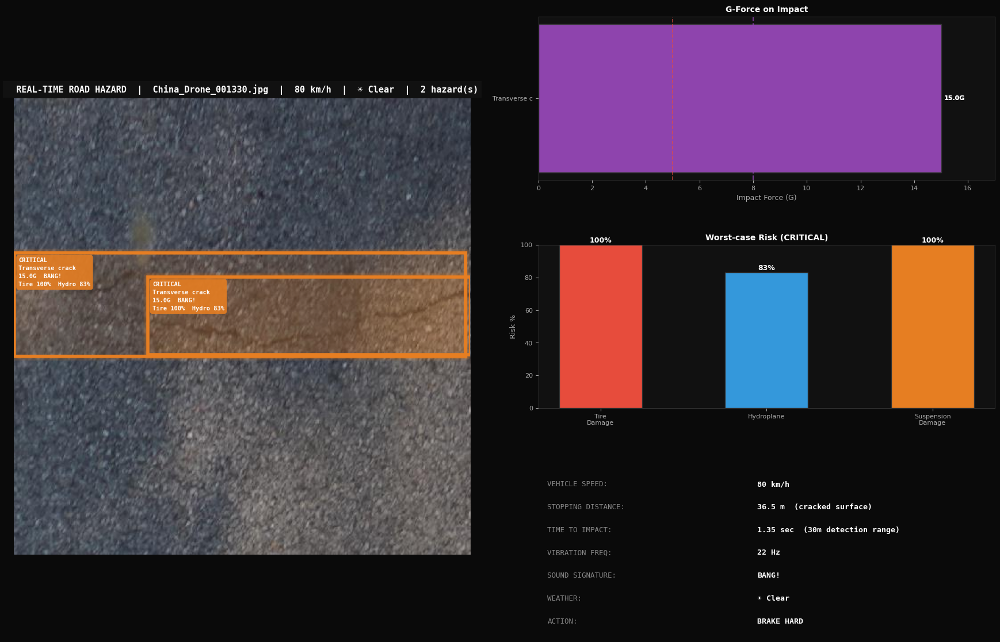

[1] China_Drone_001330.jpg | Weather:Clear | Max 15.0G | CRITICAL | Stop:36.5m | Tire:100%
  ⏭  [4] India_009679.jpg — no cracks
  ⏭  [5] India_007623.jpg — no cracks
  ⏭  [6] India_006174.jpg — no cracks
  ⏭  [7] India_000323.jpg — no cracks
  ⏭  [8] Czech_001318.jpg — no cracks


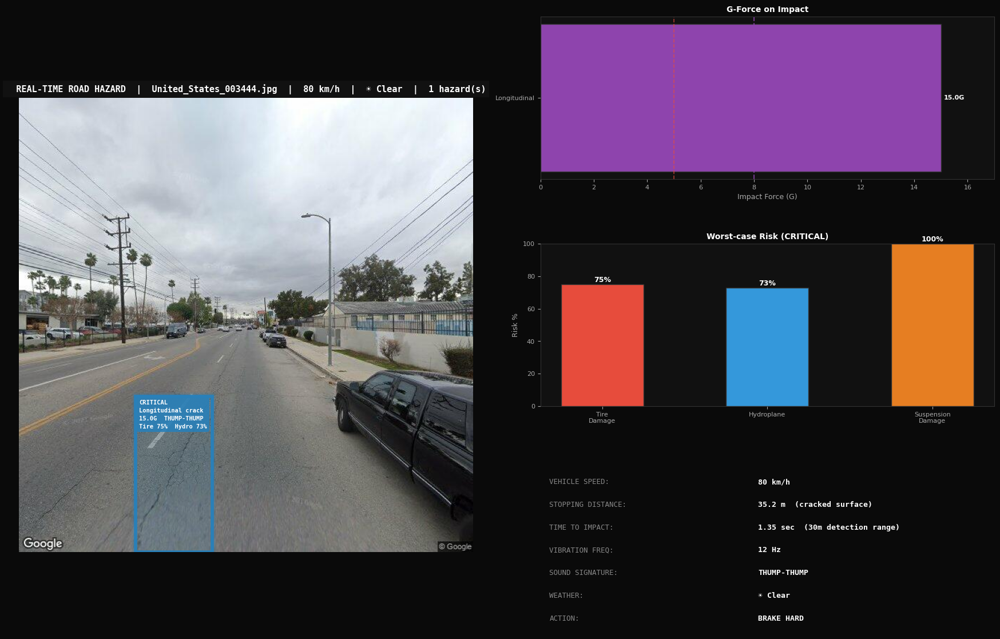

[2] United_States_003444.jpg | Weather:Clear | Max 15.0G | CRITICAL | Stop:35.2m | Tire:75%
  ⏭  [10] Norway_004607.jpg — no cracks
  ⏭  [11] Czech_000215.jpg — no cracks
  ⏭  [12] Norway_007042.jpg — no cracks
  ⏭  [13] Japan_010187.jpg — no cracks


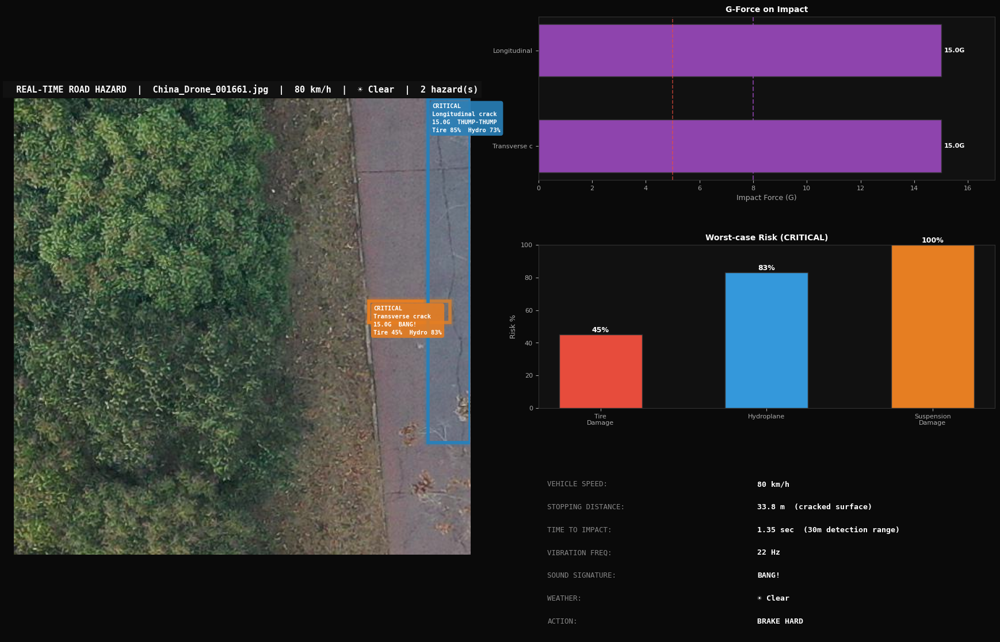

[3] China_Drone_001661.jpg | Weather:Clear | Max 15.0G | CRITICAL | Stop:33.8m | Tire:45%
  ⏭  [15] China_Drone_001555.jpg — no cracks
  ⏭  [16] Czech_000685.jpg — no cracks
  ⏭  [17] India_005886.jpg — no cracks
  ⏭  [18] India_006819.jpg — no cracks
  ⏭  [19] Norway_002246.jpg — no cracks
  ⏭  [20] Norway_007696.jpg — no cracks

✅  Done  |  3 images  |  Saved → /kaggle/working/realtime_output


In [29]:
# ═══════════════════════════════════════════════════════════════════════
#  REAL-TIME CRACK DANGER SYSTEM — What happens when a car drives over
# ═══════════════════════════════════════════════════════════════════════
import cv2, time, json, math
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from collections import deque

MODEL_PATH  = '/kaggle/input/models/rahel1696/yolo11/pytorch/default/1/final_crack_model.pt'
TEST_DIR    = Path('/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images')
SAVE_DIR    = Path('/kaggle/working/realtime_output'); SAVE_DIR.mkdir(exist_ok=True)
CONF        = 0.28
CAR_SPEED   = 80    # km/h  ← change this to simulate different speeds
CAR_WEIGHT  = 1800  # kg    ← vehicle weight

CLASS_NAMES = ['Alligator crack', 'Longitudinal crack', 'Repair', 'Transverse crack']

# ── Physics lookup per crack type ──────────────────────────────────────
CRACK_PHYSICS = {
    'Alligator crack': dict(
        base_impact=9.2, vibration_hz=18, tire_damage_risk=0.82,
        hydroplane_risk=0.75, suspension_damage=0.88,
        description="Network of interlocking cracks — tires can catch edges",
        sound="CRUNCH / THUD", color='#c0392b'
    ),
    'Longitudinal crack': dict(
        base_impact=5.8, vibration_hz=12, tire_damage_risk=0.45,
        hydroplane_risk=0.55, suspension_damage=0.52,
        description="Runs parallel to travel — causes rhythmic suspension bounce",
        sound="THUMP-THUMP", color='#2980b9'
    ),
    'Repair': dict(
        base_impact=3.2, vibration_hz=8, tire_damage_risk=0.15,
        hydroplane_risk=0.20, suspension_damage=0.22,
        description="Patched area — usually raised, minor jolt at speed",
        sound="BUMP", color='#27ae60'
    ),
    'Transverse crack': dict(
        base_impact=7.4, vibration_hz=22, tire_damage_risk=0.68,
        hydroplane_risk=0.62, suspension_damage=0.75,
        description="Perpendicular to travel — sudden sharp impact at full width",
        sound="BANG!", color='#e67e22'
    ),
}

# ── Weather multipliers ────────────────────────────────────────────────
WEATHER_MULT = {
    'Clear':   dict(impact=1.0, hydro=1.0, label='☀ Clear'),
    'Wet':     dict(impact=1.25, hydro=2.2, label='🌧 Wet road'),
    'Night':   dict(impact=1.15, hydro=1.3, label='🌙 Night'),
    'Fog':     dict(impact=1.10, hydro=1.5, label='🌫 Fog'),
}

def detect_weather(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    b = gray.mean(); s = gray.std()
    blur = cv2.Laplacian(gray, cv2.CV_64F).var()
    if b > 175 and s < 35:      return 'Clear'
    if blur < 80 and b > 110:   return 'Wet'
    if b < 65:                  return 'Night'
    if s < 38 and b > 120:      return 'Fog'
    return 'Clear'

def compute_driving_impact(det, speed_kmh, car_weight_kg, weather):
    """Simulate what happens when a car hits this crack at given speed."""
    p     = CRACK_PHYSICS[det['ct']]
    wm    = WEATHER_MULT[weather]
    area  = det['area']

    # Impact force — scales with speed² and weight (Newtonian)
    speed_ms      = speed_kmh / 3.6
    impact_factor = (speed_ms ** 2) / 100 * (car_weight_kg / 1500)
    raw_impact    = p['base_impact'] * impact_factor * (area / 3 + 0.5) * wm['impact']
    impact_g      = min(round(raw_impact, 2), 15.0)   # G-force estimate

    # Derived risks
    tire_risk     = min(1.0, p['tire_damage_risk'] * (speed_kmh/80) * (area/5+0.5) * wm['impact'])
    hydro_risk    = min(1.0, p['hydroplane_risk']  * wm['hydro'] * (speed_kmh/60))
    susp_risk     = min(1.0, p['suspension_damage'] * impact_factor * (area/4+0.3))

    # Stopping distance on cracked surface (simplified μ degradation)
    mu_base       = 0.75
    mu_cracked    = mu_base * (1 - 0.08 * min(area, 10) / 10)
    if weather == 'Wet':  mu_cracked *= 0.55
    if weather == 'Fog':  mu_cracked *= 0.85
    stop_dist     = round((speed_ms**2) / (2 * 9.81 * mu_cracked), 1)

    # Time-to-impact at current speed (assume 30m detection range)
    tti_sec       = round(30 / max(speed_ms, 0.1), 2)

    alert_level = ('CRITICAL' if impact_g > 8  else
                   'DANGER'   if impact_g > 5  else
                   'WARNING'  if impact_g > 2.5 else 'CAUTION')
    alert_color = {'CRITICAL':'#8e44ad','DANGER':'#e74c3c',
                   'WARNING':'#f39c12','CAUTION':'#27ae60'}[alert_level]

    return dict(
        impact_g      = impact_g,
        tire_risk_pct = round(tire_risk * 100),
        hydro_risk_pct= round(hydro_risk * 100),
        susp_risk_pct = round(susp_risk * 100),
        stop_dist_m   = stop_dist,
        tti_sec       = tti_sec,
        vib_hz        = p['vibration_hz'],
        sound         = p['sound'],
        alert_level   = alert_level,
        alert_color   = alert_color,
        description   = p['description'],
    )

def draw_realtime_hud(rgb, dets, impacts, weather, speed, img_name, idx):
    """Draw a heads-up-display style overlay."""
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    from matplotlib.gridspec import GridSpec

    fig = plt.figure(figsize=(22, 14), facecolor='#0a0a0a')
    gs  = GridSpec(3, 4, figure=fig, hspace=0.4, wspace=0.35)

    # ── Left: annotated image ──────────────────────────────────────────
    ax_img = fig.add_subplot(gs[:, :2])
    ax_img.set_facecolor('#0a0a0a')
    ax_img.imshow(rgb)
    ax_img.axis('off')

    for d, imp in zip(dets, impacts):
        c  = CRACK_PHYSICS[d['ct']]['color']
        al = imp['alert_level']
        lw = 4 if al == 'CRITICAL' else 3 if al == 'DANGER' else 2
        ax_img.add_patch(mpatches.FancyBboxPatch(
            (d['x1'], d['y1']), d['x2']-d['x1'], d['y2']-d['y1'],
            boxstyle="round,pad=3", lw=lw, edgecolor=c, facecolor=c, alpha=0.15))
        ax_img.add_patch(mpatches.Rectangle(
            (d['x1'], d['y1']), d['x2']-d['x1'], d['y2']-d['y1'],
            lw=lw, edgecolor=c, facecolor='none'))
        # HUD label
        label = (f"{al}\n{d['ct']}\n"
                 f"{imp['impact_g']:.1f}G  {imp['sound']}\n"
                 f"Tire {imp['tire_risk_pct']}%  Hydro {imp['hydro_risk_pct']}%")
        ax_img.text(d['x1']+5, d['y1']+5, label,
                    fontsize=7.5, color='white', fontweight='bold', va='top',
                    fontfamily='monospace', linespacing=1.5,
                    bbox=dict(boxstyle='round,pad=0.4', facecolor=c,
                              alpha=0.90, lw=0))

    ax_img.set_title(
        f"  REAL-TIME ROAD HAZARD  |  {img_name}  |  {speed} km/h  |  "
        f"{WEATHER_MULT[weather]['label']}  |  {len(dets)} hazard(s)",
        fontsize=11, fontweight='bold', color='white',
        fontfamily='monospace', pad=8,
        bbox=dict(facecolor='#111', lw=0))
    for sp in ax_img.spines.values():
        sp.set_edgecolor(impacts[0]['alert_color'] if impacts else '#444')
        sp.set_linewidth(4)

    if not impacts: plt.tight_layout(); plt.show(); plt.close(); return

    worst = max(impacts, key=lambda x: x['impact_g'])

    # ── Top-right: G-force gauge ──────────────────────────────────────
    ax_g = fig.add_subplot(gs[0, 2:])
    ax_g.set_facecolor('#111')
    g_vals = [imp['impact_g'] for imp in impacts]
    labels = [f"{d['ct'][:12]}" for d in dets]
    cols   = [imp['alert_color'] for imp in impacts]
    bars   = ax_g.barh(labels, g_vals, color=cols, edgecolor='#333', height=0.55)
    ax_g.axvline(8, color='#8e44ad', lw=1.5, ls='--', alpha=0.8)
    ax_g.axvline(5, color='#e74c3c', lw=1.2, ls='--', alpha=0.7)
    ax_g.set_xlim(0, max(15, max(g_vals)+2))
    ax_g.set_xlabel('Impact Force (G)', color='#aaa', fontsize=9)
    ax_g.set_title('G-Force on Impact', color='white', fontsize=10, fontweight='bold')
    ax_g.tick_params(colors='#aaa', labelsize=8)
    for spine in ax_g.spines.values(): spine.set_edgecolor('#333')
    ax_g.set_facecolor('#111')
    for bar, v in zip(bars, g_vals):
        ax_g.text(v+0.1, bar.get_y()+bar.get_height()/2,
                  f'{v:.1f}G', va='center', fontsize=8,
                  color='white', fontweight='bold')

    # ── Middle-right: Risk radar bars ─────────────────────────────────
    ax_risk = fig.add_subplot(gs[1, 2:])
    ax_risk.set_facecolor('#111')
    categories = ['Tire\nDamage', 'Hydroplane', 'Suspension\nDamage']
    risk_vals  = [worst['tire_risk_pct'], worst['hydro_risk_pct'], worst['susp_risk_pct']]
    risk_cols  = ['#e74c3c','#3498db','#e67e22']
    xpos = range(len(categories))
    ax_risk.bar(xpos, risk_vals, color=risk_cols, edgecolor='#333', width=0.5)
    ax_risk.set_xticks(list(xpos)); ax_risk.set_xticklabels(categories, color='#aaa', fontsize=8)
    ax_risk.set_ylim(0, 100); ax_risk.set_ylabel('Risk %', color='#aaa', fontsize=9)
    ax_risk.set_title(f'Worst-case Risk ({worst["alert_level"]})', color='white',
                      fontsize=10, fontweight='bold')
    ax_risk.tick_params(colors='#aaa', labelsize=8)
    for spine in ax_risk.spines.values(): spine.set_edgecolor('#333')
    for i, v in enumerate(risk_vals):
        ax_risk.text(i, v+1.5, f'{v}%', ha='center', fontsize=9,
                     color='white', fontweight='bold')

    # ── Bottom-right: Telemetry panel ─────────────────────────────────
    ax_tel = fig.add_subplot(gs[2, 2:])
    ax_tel.set_facecolor('#0d0d0d'); ax_tel.axis('off')
    lines = [
        ("VEHICLE SPEED",      f"{speed} km/h"),
        ("STOPPING DISTANCE",  f"{worst['stop_dist_m']} m  (cracked surface)"),
        ("TIME TO IMPACT",     f"{worst['tti_sec']} sec  (30m detection range)"),
        ("VIBRATION FREQ",     f"{worst['vib_hz']} Hz"),
        ("SOUND SIGNATURE",    worst['sound']),
        ("WEATHER",            WEATHER_MULT[weather]['label']),
        ("ACTION",             ("BRAKE HARD" if worst['impact_g']>8 else
                                "REDUCE SPEED" if worst['impact_g']>5 else
                                "CAUTION" if worst['impact_g']>2.5 else "PASS SAFELY")),
    ]
    for i, (k, v) in enumerate(lines):
        y = 0.92 - i * 0.14
        ax_tel.text(0.02, y, k+':', transform=ax_tel.transAxes,
                    fontsize=9, color='#888', fontfamily='monospace')
        ax_tel.text(0.48, y, v, transform=ax_tel.transAxes,
                    fontsize=9.5, color='white', fontweight='bold', fontfamily='monospace')

    plt.savefig(SAVE_DIR/f'hud_{idx:03d}_{Path(img_name).stem}.png',
                dpi=120, bbox_inches='tight', facecolor='#0a0a0a')
    plt.show(); plt.close()


# ═══════════════════════════════════════════════════════════════════════
#  MAIN LOOP
# ═══════════════════════════════════════════════════════════════════════
import random
from pathlib import Path

model    = YOLO(MODEL_PATH)
all_imgs = sorted(list(TEST_DIR.glob('*.jpg')) + list(TEST_DIR.glob('*.png')))
random.seed(42)
samples  = random.sample(all_imgs, min(20, len(all_imgs)))

log = []; shown = 0

for idx, img_path in enumerate(samples, 1):
    bgr = cv2.imread(str(img_path))
    if bgr is None: continue
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    H, W = rgb.shape[:2]

    weather = detect_weather(rgb)
    res     = model(img_path, conf=CONF, verbose=False)
    dets    = []

    if res[0].boxes:
        for box in res[0].boxes:
            x1,y1,x2,y2 = map(int, box.xyxy[0].tolist())
            ci   = int(box.cls[0]); cf = float(box.conf[0])
            area = round(((x2-x1)*(y2-y1))/(H*W)*100, 2)
            dets.append(dict(x1=x1,y1=y1,x2=x2,y2=y2,
                             ct=CLASS_NAMES[ci], cf=cf, area=area))

    if not dets:
        print(f"  ⏭  [{idx}] {img_path.name} — no cracks"); continue

    # Compute driving physics for every detection
    impacts = [compute_driving_impact(d, CAR_SPEED, CAR_WEIGHT, weather) for d in dets]
    shown  += 1

    draw_realtime_hud(rgb, dets, impacts, weather, CAR_SPEED, img_path.name, shown)

    worst = max(impacts, key=lambda x: x['impact_g'])
    print(f"[{shown}] {img_path.name} | Weather:{weather} | "
          f"Max {worst['impact_g']:.1f}G | {worst['alert_level']} | "
          f"Stop:{worst['stop_dist_m']}m | Tire:{worst['tire_risk_pct']}%")

    log.append(dict(image=img_path.name, weather=weather,
                    speed_kmh=CAR_SPEED, max_g=worst['impact_g'],
                    alert=worst['alert_level'], stop_dist=worst['stop_dist_m'],
                    cracks=[dict(type=d['ct'], area=d['area'],
                                 g_force=i['impact_g'], tire_risk=i['tire_risk_pct'],
                                 hydro_risk=i['hydro_risk_pct'])
                            for d,i in zip(dets,impacts)]))

with open(SAVE_DIR/'driving_report.json','w') as f: json.dump(log, f, indent=2)
print(f"\n✅  Done  |  {shown} images  |  Saved → {SAVE_DIR}")